# 26 · Apprentissage par renforcement — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch26_rl/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 26.Q1 à 26.Q12, 26.R1 à 26.R3, 26.1 à 26.6 | vérifier tes réponses courtes | 🧠 🔁 ✏️ | ★ à ★★ | |
| A | 26.13 | Prendre en main gymnasium avec FrozenLake | 📦 | ★ | 15 |
|  | 26.14 | Retours actualisés et retours à venir | 🔨 | ★★ | 30 |
|  | 26.15 | Reproduire les courbes d'actualisation (fig. 26.13-26.14) | 🎨 | ★ | 15 |
|  | 26.16 | Prédire l'effet du camion sur la table L | 🔮 | ★ | 10 |
|  | 26.17 | Flippers : la longueur optimale de chaque partie par recherche exhaustive | 🔬 | ★★ | 25 |
|  | 26.18 | L-learning sur Flippers, sans puis avec camion | 🔬 | ★★★ | 40 |
| B | 26.19 | Politiques gloutonne et softmax (ε-greedy importée du ch. 11) | 🔨 | ★★★ | 35 |
|  | 26.20 | Mises à jour de Q-learning et de SARSA, états terminaux compris | 🔨 | ★★★ | 75 |
|  | 26.21 | La boucle d'entraînement tabulaire et l'évaluation d'une politique | 🔨 | ★★★ | 90 |
| C | 26.22 | Q-learning sur FrozenLake, glissant ou non | 📦 | ★★ | 25 |
|  | 26.23 | Lire des courbes d'apprentissage RL bruitées | 📈 | ★★ | 15 |
|  | 26.24 | L'agent qui n'apprenait rien | 🐛 | ★★ | 25 |
|  | 26.25 | Q-learning sur Flippers avec camion : 300, 3 000 puis 6 000 parties | 🔬 | ★★★ | 40 |
|  | 26.26 | Itération sur les valeurs : la référence quand le modèle est connu | 🔨 | ★★★ | 40 |
|  | 26.27 | α, γ, ε : balayage d'hyperparamètres sur Flippers bruité | 🔬 | ★★★ | 45 |
| D | 26.28 | Prédire le chemin appris par SARSA et par Q-learning au bord de la falaise | 🔮 | ★ | 10 |
|  | 26.29 | Q-learning contre SARSA sur Flippers et CliffWalking | 🔬 | ★★★ | 45 |
|  | 26.30 | Reproduire les comparaisons au fil de l'entraînement (fig. 26.58-26.60) | 🎨 | ★★★ | 35 |
| E | 26.31 | Une mémoire de rejeu | 🔨 | ★★★ | 40 |
|  | 26.32 | Concevoir la récompense : finale, pénalité par coup ou façonnée | 🔬 | ★★ | 30 |
|  | 26.33 | Rejouer l'expérience pour apprendre avec moins d'épisodes | 🔬 | ★★★ | 35 |
|  | 26.34 | Rapporter un résultat RL honnête : plusieurs graines, configuration, intervalle | 🛠️ | ★★ | 25 |
| F | 26.35 | Morpion contre un adversaire aléatoire : masque d'actions ou pénalité | 📦 | ★★★ | 45 |
|  | 26.36 | CartPole : discrétiser un état continu pour un Q-learning tabulaire | 📦 | ★★★ | 45 |
|  | 26.37 | Auto-apprentissage au morpion : l'agent joue les deux camps | 🔬 | ★★★★ | 90 |
|  | 26.38 | Défi CartPole tabulaire : tenir 475 pas en moyenne sur 500 | 🏆 | ★★★★ | 120 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Manipuler la boucle agent-environnement avec Gymnasium, et calculer des retours actualisés.
- Écrire dans `mylearn.rl` un agent tabulaire complet (politiques, mises à jour du Q-learning et de SARSA, boucle d'entraînement, itération sur les valeurs, mémoire de rejeu) et le comparer sur Flippers, FrozenLake, CliffWalking, le morpion et CartPole.
- Rapporter un résultat de RL sur plusieurs graines.

**Rappel express.** $G_t = r_t + \gamma\,G_{t+1}$. Q-learning : $Q(s, a) \leftarrow Q(s, a) + \alpha\,[r + \gamma \max_{a'} Q(s', a') - Q(s, a)]$, la cible vaut $r$ si $s'$ est terminal. SARSA : $Q(s', a')$ de l'action réellement choisie au lieu du max. ε-greedy : l'action gloutonne avec la probabilité $1 - \varepsilon + \varepsilon/|\mathcal{A}|$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 26.1 à 26.6)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"F"`) ; plusieurs lettres : entre guillemets (`"AF"`), dans l'ordre demandé quand l'énoncé en impose un. Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les dérivations ∂ 26.7 et 26.8, l'estimation 🧮 26.9, la réflexion (🗣️ 26.10, ⚖️ 26.11, 📄 26.12) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math


def discounted(rewards, gamma):
    """G_0 = sum of gamma**k * r_k."""
    return sum(gamma ** k * r for k, r in enumerate(rewards))


def softmax_prob(q, tau, i):
    """Probability of action i under a softmax of temperature tau."""
    m = max(q)
    weights = [math.exp((v - m) / tau) for v in q]
    return weights[i] / sum(weights)


REWARDS_26_1 = [1, 0, 0, 2, 0, 4]
Q_26_3, R_26_3, NEXT_26_3, GAMMA_26_3, ALPHA_26_3 = 0.5, 0.2, [0.1, 0.6, 0.3, 0.6], 0.9, 0.5
TARGET_26_3 = R_26_3 + GAMMA_26_3 * max(NEXT_26_3)
NEW_26_3 = Q_26_3 + ALPHA_26_3 * (TARGET_26_3 - Q_26_3)
TARGET_26_4 = R_26_3 + GAMMA_26_3 * NEXT_26_3[2]
NEW_26_4 = Q_26_3 + ALPHA_26_3 * (TARGET_26_4 - Q_26_3)
Q_26_5, EPS_26_5 = [1, 2, 4, 0], 0.2


def chain_26_6(alpha, episodes, n_states=3, gamma=0.9):
    """Q of the chain 0 -> 1 -> ... -> n_states (terminal), updated in the order of the steps."""
    q = [0.0] * n_states
    for _ in range(episodes):
        for s in range(n_states):
            target = 1.0 if s == n_states - 1 else gamma * q[s + 1]
            q[s] += alpha * (target - q[s])
    return q

**26.Q1 — Apprendre avec des récompenses : ni supervisé, ni non supervisé**

In [3]:
wb.record("26.Q1a", "B", mistakes={"le RL utilise souvent des réseaux : relis ce que l'agent reçoit à la place d'un label": "A", "un agent apprend de ses propres essais : ce sont des données": "C", "relis les exemples du livre : ascenseurs, cultures, robot": "D"})
wb.record("26.Q1b", "ACE", mistakes={"un des problèmes cités se résout avec des labels, un autre sans aucun signal : ni l'un ni l'autre n'est du RL": "ABCE",
          "il manque un problème où l'on agit et où l'on est jugé sur le résultat": "AC",
          "le regroupement sans labels est de l'apprentissage non supervisé": "ACDE"})
wb.record("26.Q1c", False, mistakes={"relis le §26.2 : quand arrive la récompense d'une partie gagnée ?": True})
wb.record("26.Q1d", False, mistakes={"relis le §26.1 : le livre parle d'une approche générale": True})
wb.record("26.Q1e", "B", mistakes={"le livre dit qu'il n'existe souvent pas de réponse objectivement juste": "A", "relis le §26.2 : le critère est celui qu'on choisit": "C"})

WB_ANSWER {"hash": "3b16861541defdb5922ebc7b1ea45220a532c31954db75207b140e32fcd7ff58", "id": "26.Q1a", "kind": "str", "mistakes": {"b3ab87506659d49382924252d3b87c864ef9321f3fd048d87a64b3717c59ba5e": "le RL utilise souvent des réseaux : relis ce que l'agent reçoit à la place d'un label", "e7a01a2fcf29b6d23096e137a380649ed4eab3cdaceb1f23c8bd16997046c3e1": "un agent apprend de ses propres essais : ce sont des données", "f980ee6b3cb789a11bbae3d361c9d575f1f6cb70d583ec9812e4b27de13a2062": "relis les exemples du livre : ascenseurs, cultures, robot"}}
📝 Ex 26.Q1a : réponse enregistrée (str).
WB_ANSWER {"hash": "9e595933637d0e91b3b46bd76f67917780295b2ad846df03491e39ffb86078ca", "id": "26.Q1b", "kind": "str", "mistakes": {"08a8bcbfc1d1dae69d7c7becdf01fecbb1ff8f3b09653923d9191780eb41fe0f": "le regroupement sans labels est de l'apprentissage non supervisé", "77be7d2fe95e1621e6b7913ac9655b03a8e9b19dd96177341b3817cbd80f4bf0": "un des problèmes cités se résout avec des labels, un autre sans aucun sig

**26.Q2 — Les quatre informations données à l'agent du morpion**

In [4]:
wb.record("26.Q2a", "B", mistakes={"l'amie choisit les coups : c'est l'agent": "A", "relis qui donne les récompenses et joue en retour": "C"})
wb.record("26.Q2b", "ABDF", mistakes={"l'agent ne reçoit pas la règle du jeu : il l'apprend": "ABCDF",
          "il manque une des quatre informations": "ABD",
          "on ne lui dit même pas que c'est un jeu": "ABDEF"})
wb.record("26.Q2c", False, mistakes={"relis ce que le livre dit des informations privées de l'agent": True})
wb.record("26.Q2d", "B", mistakes={"proposer des coups interdits ne fait pas gagner de temps": "A", "relis le §26.2.1 : à quoi servent les récompenses d'un coup interdit ?": "C"})
wb.record("26.Q2e", 9 - 2, mistakes={"les coups permis sont les cases vides": 2})

WB_ANSWER {"hash": "cae1e6c47800539e0d4537e2c6a5f45d93fffe5ee385408ffd77088cb1941fe1", "id": "26.Q2a", "kind": "str", "mistakes": {"67c99b35f744f20ba53d1624d0d1ae719dd82842c1d7eccb4da965c5c38bc3a5": "l'amie choisit les coups : c'est l'agent", "b47c1f281806111d5f73582d939c4e925f8e75167a995fa2c831351c65d17850": "relis qui donne les récompenses et joue en retour"}}
📝 Ex 26.Q2a : réponse enregistrée (str).
WB_ANSWER {"hash": "92ea1d9e4aaa437eb06b32680c73f305b62f20bc147290e20e615e2f22586aa2", "id": "26.Q2b", "kind": "str", "mistakes": {"098b2c96e9b8614fb0157075ec3ad0b85bab5c97bc35ce2016e4433e79fac7a4": "l'agent ne reçoit pas la règle du jeu : il l'apprend", "0a092cbe8824e4e361124cbabe3347b9eef727dcecc6443bda39157439c1e134": "on ne lui dit même pas que c'est un jeu", "43c73e12878a3f6ab4ca9d7c4e33772ea928b5b4883ac2bc63ea1388efcefb6c": "il manque une des quatre informations"}}
📝 Ex 26.Q2b : réponse enregistrée (str).
WB_ANSWER {"hash": "36b02c79e58855cee76dff7e1c459ea6bcf76f24293ed833b9ecd783f

**26.Q3 — État, actions, politique et informations privées**

In [5]:
wb.record("26.Q3a", "CAB", mistakes={"l'agent agit avant que l'environnement réponde": "ACB",
          "l'agent se met à jour après la réponse": "CBA"})
wb.record("26.Q3b", "B", mistakes={"une epoch est un passage sur un dataset, pas une partie": "A", "la politique est la règle de choix des actions": "C", "une transition est le passage d'un état à un autre": "D"})
wb.record("26.Q3c", "B", mistakes={"une moyenne de récompenses mesure un résultat, pas une règle de choix": "A", "la liste des états décrit le monde, pas ce qu'on y fait": "C", "le plateau de départ est un état, pas une règle": "D"})
wb.record("26.Q3d", False, mistakes={"relis le §26.3.1 : qui exécute l'action, et pourquoi ?": True})
wb.record("26.Q3e", True, mistakes={"relis le §26.3.1 : un état contient tous les nombres qui décrivent l'environnement": False})

WB_ANSWER {"hash": "123574aeb60640a0b6431fc186745d73b63bb9ed56231e3df7ce5494b129e32a", "id": "26.Q3a", "kind": "str", "mistakes": {"3a4312d2cbaa8ea0ed0396f6c06b051e9b2363379a392dde6a47bd45cbe4504a": "l'agent agit avant que l'environnement réponde", "935969b5861cbd5c5054a552fb5d351c925780f4673452d5309402d727431dea": "l'agent se met à jour après la réponse"}}
📝 Ex 26.Q3a : réponse enregistrée (str).
WB_ANSWER {"hash": "1cdf5ad1580feb66e44f4813a39ac9e391f511d8555b9e4f4e7faf089c74f493", "id": "26.Q3b", "kind": "str", "mistakes": {"488f60616a3ee1ea8f13e6a6028c2167044334bf2963dd76c668ac4a872003d0": "une transition est le passage d'un état à un autre", "5b56ce066f4fcb7d1a8b8052929981649245ed7584424b0b42aec5bbf629b6f8": "une epoch est un passage sur un dataset, pas une partie", "842fa3fc41feb81c08844d18e9eadd2522fc3bcbf0d3a0add914a816cdd44ea5": "la politique est la règle de choix des actions"}}
📝 Ex 26.Q3b : réponse enregistrée (str).
WB_ANSWER {"hash": "7572e1344c7a932771d1a361699409b2cbdb4f7

**26.Q4 — Réponse de l'environnement, épisode et agents libres ou déclenchés**

In [6]:
wb.record("26.Q4a", "B", mistakes={"la politique appartient à l'agent": "A", "l'environnement ne connaît pas la meilleure action": "C", "les valeurs Q sont calculées par l'agent": "D"})
wb.record("26.Q4b", "BA", mistakes={"le cuisinier attend la sonnerie : il est déclenché ; le minuteur tourne seul": "AB",
          "le minuteur tourne de lui-même": "BB",
          "le cuisinier attend qu'on le sollicite": "AA"})
wb.record("26.Q4c", "B", mistakes={"au backgammon, chacun attend son tour": "A", "les deux joueurs attendent leur tour": "C"})
wb.record("26.Q4d", True, mistakes={"relis le §26.3.4 : lequel des quatre cas le livre dit-il le plus simple ?": False})
wb.record("26.Q4e", "C", mistakes={"il manque les indicateurs de fin et le dictionnaire info": "A", "c'est ce que renvoie reset, pas step": "B", "c'est l'ancienne API de Gym : Gymnasium sépare deux façons de finir": "D"})

WB_ANSWER {"hash": "ae500f407936114398e54c1e5c7ce982cef503445786b07a45050136217df561", "id": "26.Q4a", "kind": "str", "mistakes": {"3026bb0646a540533a10ee337f064ac1e129928763860b11ec59eeb5df823dc9": "la politique appartient à l'agent", "c33bea5131431d13c9377d42f61d9448568d48ed39ba067651b303b2bef747ec": "l'environnement ne connaît pas la meilleure action", "db5f3bd2db198cced45d5b54d54b11ce5f6ad3b286e8e561d571f51ae72da104": "les valeurs Q sont calculées par l'agent"}}
📝 Ex 26.Q4a : réponse enregistrée (str).
WB_ANSWER {"hash": "081cdd5c94d2cd35919d46416e35b572206af28a0dd3ba1e7fb1b2afd0cb7b19", "id": "26.Q4b", "kind": "str", "mistakes": {"17943718359f89ae8588e198392500a267aa6cd3450d7c76604ebc8854173f9d": "le cuisinier attend la sonnerie : il est déclenché ; le minuteur tourne seul", "b960baec91376be196bfd729b72ffcb0f60ce772cfc2217ef62af44080506da2": "le cuisinier attend qu'on le sollicite", "fce2c3259425ae46ee5780e62791474eac071ee14816ee886f4f9ca4cd667d6c": "le minuteur tourne de lui-même

**26.Q5 — MDP, observabilité, attribution du crédit, exploration ou exploitation**

In [7]:
wb.record("26.Q5a", "B", mistakes={"relis l'encadré sur les MDP : il s'agit de mémoire, pas d'équiprobabilité": "A", "la propriété de Markov ne dit rien du signe des récompenses": "C", "un MDP peut être stochastique": "D"})
wb.record("26.Q5b", "B", mistakes={"l'agent voit-il tout l'état ?": "A"})
wb.record("26.Q5c", "B", mistakes={"le dilemme porte sur le choix du prochain coup, pas sur le mérite des coups passés": "A", "il s'agit de partager le mérite d'une victoire entre les coups": "C", "l'actualisation pèse les récompenses futures, elle ne dit pas quel coup a compté": "D"})
wb.record("26.Q5d", False, mistakes={"une politique gloutonne rejoue toujours la même action : une action sous-estimée n'est plus jamais essayée": True})
wb.record("26.Q5e", "B", mistakes={"la régression logistique ne choisit pas d'actions": "A", "le k-means regroupe des données, il ne choisit pas d'actions": "C"})

WB_ANSWER {"hash": "88a863c5b5f372aa8a03f2f25901f03470331b01db211469b169df83f1d21021", "id": "26.Q5a", "kind": "str", "mistakes": {"09bd1bd66a11a23c70e6499e0aeb595862ee9e477a74a153c9bb1a418dc9221e": "un MDP peut être stochastique", "11f584a6f2b0196ebcb1986f20e5e3390d56a90210194fe1d46c9fca4f38811c": "la propriété de Markov ne dit rien du signe des récompenses", "65171feae06e5d9b795564fb496aab13521cb05e59be91e5e9afdcdc6c2b3f32": "relis l'encadré sur les MDP : il s'agit de mémoire, pas d'équiprobabilité"}}
📝 Ex 26.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "50aecb4c02974f2e72fa9b4d8f152902e38d5761404c6c5806156e69e7718b5f", "id": "26.Q5b", "kind": "str", "mistakes": {"440f890e5a41cb7ca3a49e84d4ae3480d292226ef639444cd09c8c3982c8ad53": "l'agent voit-il tout l'état ?"}}
📝 Ex 26.Q5b : réponse enregistrée (str).
WB_ANSWER {"hash": "e3e9d0dad7684dc63ef6e260481d94a8de493a785db0e8925db411c97d088679", "id": "26.Q5c", "kind": "str", "mistakes": {"34dc6a10bbefbc1ce4b9a6a3be8fb76dcc7c126c5126

**26.Q6 — Retour total, retour actualisé et rôle de γ**

In [8]:
wb.record("26.Q6a", 2 + 0 + 1)
wb.record("26.Q6b", discounted([2, 0, 1], 0.5), decimals=2, mistakes={"le poids de la 3e récompense est γ², pas γ": 2.5, "c'est le retour total : actualise": 3})
wb.record("26.Q6c", True, mistakes={"avec γ = 0, que valent les poids γ^k pour k ≥ 1 ?": False})
wb.record("26.Q6d", "B", mistakes={"c'est l'interprétation du livre, que la fiche corrige": "A", "c'est le rôle du learning rate α": "C"})
wb.record("26.Q6e", round(1 / (1 - 0.95)), mistakes={"1 / (1 − γ), pas γ / (1 − γ)": 19})

WB_ANSWER {"hash": "5cc09472abed251e357c44ac712f631ab3341e29166d4935ddf8df366033b614", "id": "26.Q6a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex 26.Q6a : réponse enregistrée (int).
WB_ANSWER {"alt_coarse": ["67d5d00933a6eefbc7c2472d36cb82a0fbf428bcd030c4b70029f6cc6f382bf1"], "decimals": 2, "hash": "c6826b9e87bf39451ce2b2e7603285964971b54588b6236406a1f9cec5fd24e0", "hash_coarse": "b9d684fa8b4ab9f232dcae067449bb2f2abc25efe1bb7fddda9043a6dd6740f4", "id": "26.Q6b", "kind": "float", "magnitude": 0, "mistakes": {"2dd2abc7c40055fa0d98669de02dadbb87a664bd6b392dbd80ffb3b3af2bbae5": "c'est le retour total : actualise", "412cd84c156c1b955c2a64c87dc6050c9b3351f8bda0b2810f49b29f32889c6e": "le poids de la 3e récompense est γ², pas γ"}, "sign": 1}
📝 Ex 26.Q6b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "c22f66f63bad161a5eeb9820a1e1a677df46de3dc4300da02799dce4c4519003", "id": "26.Q6c", "kind": "bool", "mistakes": {"d81cb38918035dae5cb5551e43f4133487c95c11ced7f3d48a9769a6c05f2

**26.Q7 — Flippers et L-learning : pourquoi « lousy » ?**

In [9]:
wb.record("26.Q7a", "B", mistakes={"relis la règle du jeu au §26.4": "A", "les diagonales ne comptent pas, et les autres tuiles doivent être vides": "C"})
wb.record("26.Q7b", 6, mistakes={"les diagonales ne comptent pas": 8, "les colonnes comptent aussi": 3})
wb.record("26.Q7c", "B", mistakes={"la moyenne, c'est justement ce qui manque au L-learning": "A", "relis la règle de mise à jour du §26.5": "C"})
wb.record("26.Q7d", True, mistakes={"relis les résultats du livre sans camion, après 6 000 parties": False})
wb.record("26.Q7e", "B", mistakes={"le jeu reste gagnable, seulement plus long": "A", "le camion retourne des tuiles, il n'en ajoute pas": "C"})

WB_ANSWER {"hash": "538df74ac7680383b792419d8b4ac0d4f88b2172aa5f8adfbcd8eb9cab660cf6", "id": "26.Q7a", "kind": "str", "mistakes": {"34304e5dda609ebedffeebec871b14a530d9e95ded64d7b2fc5d7ff4e81e6570": "relis la règle du jeu au §26.4", "e68e3d100455e2ab76bfafbc06d7c831aef828436decaaff2b7c0968026e4f7f": "les diagonales ne comptent pas, et les autres tuiles doivent être vides"}}
📝 Ex 26.Q7a : réponse enregistrée (str).
WB_ANSWER {"hash": "2bd5087d363a4f8a646373592a7f114829a42cc072284f596b483da485cfea88", "id": "26.Q7b", "kind": "int", "magnitude": 0, "mistakes": {"0ab4b1ac01bac0567e2c0924a1769a8b0a1ea3a221c1a7d4f8cb3d443f60d652": "les diagonales ne comptent pas", "539be6e9fd910fce109ab6bc7e461738b70b15f9a1163dfe515a1915f6297dfa": "les colonnes comptent aussi"}, "sign": 1}
📝 Ex 26.Q7b : réponse enregistrée (int).
WB_ANSWER {"hash": "18f0e36417c12a0252ce9d003b7be169ff531b3e91ec1f90b64bece65262d612", "id": "26.Q7c", "kind": "str", "mistakes": {"100da9b4fb3bdd1859015353a306ad35b97196756315f44d7

**26.Q8 — La mise à jour du Q-learning : α, γ et la valeur de l'état suivant**

In [10]:
wb.record("26.Q8a", "B", mistakes={"la ligne de s porte la valeur qu'on met à jour : la cible regarde ce qui vient après": "A", "la cible regarde l'état atteint par l'action, pas celui du départ": "C"})
wb.record("26.Q8b", "B", mistakes={"c'est le cas α = 1": "A", "α = 0 laisse l'ancienne valeur": "C"})
wb.record("26.Q8c", "B", mistakes={"la moyenne, c'est 0 < α < 1": "A", "c'est le cas α = 0": "C"})
wb.record("26.Q8d", False, mistakes={"relis le §26.6 : quand le Q-learning met-il la table à jour ?": True})
wb.record("26.Q8e", 0.4 + 0.5 * (0 + 1 * 0.8 - 0.4), decimals=2, mistakes={"c'est la cible : mélange-la avec l'ancienne valeur": 0.8})

WB_ANSWER {"hash": "1f91f4aae10cb34887cb635e08114355c04726d4b34e34790d27fa520648bf59", "id": "26.Q8a", "kind": "str", "mistakes": {"059792eb9d9cb257fac67d033fc81764f7e5d7750f4e1fa4993827a7d8253cf5": "la ligne de s porte la valeur qu'on met à jour : la cible regarde ce qui vient après", "e0c878f5194ccaf4d8d9129f1c863cf9b9424241dbf21f7f687cc786f5fd4c3b": "la cible regarde l'état atteint par l'action, pas celui du départ"}}
📝 Ex 26.Q8a : réponse enregistrée (str).
WB_ANSWER {"hash": "b09242176cd352570fd1f08c9665cb70ed1e2ba62f62f98f1495f41124c39ddc", "id": "26.Q8b", "kind": "str", "mistakes": {"51c63c6a732169c53e8114a3a6e912b4d6c18b2e36b1d4f5f563e3ea63603f93": "c'est le cas α = 1", "d7a74b016ba59bb25a246f85813a760d46d8012e735617bde291f6266cafdd2b": "α = 0 laisse l'ancienne valeur"}}
📝 Ex 26.Q8b : réponse enregistrée (str).
WB_ANSWER {"hash": "a6dd5e9d92a352d8175119c2771f0f27424e31b3d8d4d288114d70629e26db95", "id": "26.Q8c", "kind": "str", "mistakes": {"3f90807716064fcce6361b8727c68dac3ad0d

**26.Q9 — ε-greedy ou softmax : vrai ou faux**

In [11]:
wb.record("26.Q9a", True, mistakes={"c'est la version du livre que la fiche corrige": False})
wb.record("26.Q9b", 1 - 0.1 + 0.1 / 5, decimals=2, mistakes={"l'exploration peut aussi tirer l'action gloutonne": 0.9})
wb.record("26.Q9c", False, mistakes={"une grande température rend les probabilités presque égales": True})
wb.record("26.Q9d", True, mistakes={"relis la fin du paragraphe softmax du §26.6.2": False})
wb.record("26.Q9e", "B", mistakes={"divise 0 par la somme des zéros : est-ce défini ?": "A", "aucune action n'est préférée : la formule elle-même pose problème": "C"})

WB_ANSWER {"hash": "61411985752285ae4705dd2fe19cc199894c213318e9f89f3d4ccc8bd8cd466f", "id": "26.Q9a", "kind": "bool", "mistakes": {"abfa163c21a49bf6d87d6ebc6b4ee3c12944c41aad9b5bf6f96fe6f619453248": "c'est la version du livre que la fiche corrige"}}
📝 Ex 26.Q9a : réponse enregistrée (bool).
WB_ANSWER {"decimals": 2, "hash": "d86f92b68c67ba84756c7e522d067da5b40730376dbaa04c846373b4a1136934", "hash_coarse": "ab71d13ff076ca204c7a26c59d91cd768ce8f114c244985a6e7d53b61c2a85e3", "id": "26.Q9b", "kind": "float", "magnitude": -1, "mistakes": {"b9e1387eb8651bb79a40e18a9df8348bdaacadfada5865cdc2a1158c6e404294": "l'exploration peut aussi tirer l'action gloutonne"}, "sign": 1}
📝 Ex 26.Q9b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "d51b786f837ed4438c01bc26fae5014772420aa3c085357411ab036e71ee9a29", "id": "26.Q9c", "kind": "bool", "mistakes": {"56cc65a1db55373050eadb2dd280d309cb8b14f7ce36ac4d1f629fc8504c3a56": "une grande température rend les probabilités presque égales"}}
📝 Ex

**26.Q10 — Table initialisée à zéro : comment la valeur remonte et converge**

In [12]:
wb.record("26.Q10a", "A", mistakes={"la mise à jour est déterministe : que vaut une cible faite de zéros ?": "B", "la mise à jour mélange des nombres nuls": "C"})
wb.record("26.Q10b", "B", mistakes={"le Q-learning met à jour un seul pas à la fois": "A", "la première action ne voit la victoire que bien plus tard": "C"})
wb.record("26.Q10c", True, mistakes={"relis le §26.6.4 : la valeur remonte grâce à la cible qui regarde l'état suivant": False})
wb.record("26.Q10d", "A", mistakes={"α = 1 remplace à chaque fois : relis l'encadré sur la convergence": "B", "une politique gloutonne ne visite pas toutes les cases": "C"})
wb.record("26.Q10e", "C", mistakes={"relis les résultats du §26.6.5 : la longueur baisse encore après 300 parties": "A", "relis les résultats du §26.6.5 : la longueur baisse encore après 3 000 parties": "B"})

WB_ANSWER {"hash": "50976916dbd2e604b8ff1cc93d599512a5f4a26e4bbe433038cc4efc57d03860", "id": "26.Q10a", "kind": "str", "mistakes": {"6a81f08a200f690c839996e67a4cce08669ca1ed1fe10ffb8829a08b2447df29": "la mise à jour est déterministe : que vaut une cible faite de zéros ?", "f2d0052a7e4cf7201274fae38774610918358e060e42ed251d18100651e005bd": "la mise à jour mélange des nombres nuls"}}
📝 Ex 26.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "7b35eaa9edc856f30eb5e057d10cc2775b7bf3889776c9e796c38ca7cf4ff39c", "id": "26.Q10b", "kind": "str", "mistakes": {"c81b3b8efa823f1221db9e3c27533667fa7b56633a5fa73c35adad5ef35ed8d3": "le Q-learning met à jour un seul pas à la fois", "e40f1344f8be783b3ac187ed30c51390d26c2345728158f7b01ba05790931e67": "la première action ne voit la victoire que bien plus tard"}}
📝 Ex 26.Q10b : réponse enregistrée (str).
WB_ANSWER {"hash": "bbadf13a37ba997d3811cf054e32e718142a8446c5ea0f2e321f1876a194756b", "id": "26.Q10c", "kind": "bool", "mistakes": {"4b715fa81e4bdd624

**26.Q11 — SARSA contre Q-learning : l'action suivante réellement jouée**

In [13]:
wb.record("26.Q11a", "A", mistakes={"le nom liste les cinq éléments d'une mise à jour": "B", "le nom liste les cinq éléments d'une mise à jour, pas un nom propre": "C"})
wb.record("26.Q11b", "B", mistakes={"c'est la cible du Q-learning": "A", "relis la formule de SARSA": "C"})
wb.record("26.Q11c", "A", mistakes={"SARSA apprend la valeur de la politique qu'il suit": "B"})
wb.record("26.Q11d", True, mistakes={"si a' est l'action gloutonne, que vaut Q(s', a') comparé au max ?": False})
wb.record("26.Q11e", False, mistakes={"relis l'encadré « un défaut du Q-learning ? »": True})

WB_ANSWER {"hash": "3637e2d97fec7622b8befab8a057e902a90608d2b56cb802e8221411e4101130", "id": "26.Q11a", "kind": "str", "mistakes": {"9627478252f7daa494e7b94a420d625aa603b0e55c75070b4241f1c3403588c4": "le nom liste les cinq éléments d'une mise à jour", "ddcad25f56b3bdeb00c3b3eb0a5b071850dee65ba843055989056e5ef413b19b": "le nom liste les cinq éléments d'une mise à jour, pas un nom propre"}}
📝 Ex 26.Q11a : réponse enregistrée (str).
WB_ANSWER {"hash": "e5a6fe1029b97c124582c35f28a610799ba855c0178c19a85e6be249d0effcdc", "id": "26.Q11b", "kind": "str", "mistakes": {"2eae0a92c9345c241f1490809d5d43dfe9f56fd6561c18f33171dc9caca7d586": "relis la formule de SARSA", "dffb019558979af50ba97723922f080eab4800bc8919bfe6fe26039b80ed906e": "c'est la cible du Q-learning"}}
📝 Ex 26.Q11b : réponse enregistrée (str).
WB_ANSWER {"hash": "d1ea101b354ff8ead37551a8d5a5143c76d1997c768312e589b419e44627c02a", "id": "26.Q11c", "kind": "str", "mistakes": {"dbfaaea10a8859a73c6774db7640a87589ca653a49d5012699923b62189de

**26.Q12 — Tables géantes, rejeu d'expérience, AlphaGo Zero et lancer de rayons**

In [14]:
wb.record("26.Q12a", 16, mistakes={"c'est le nombre du livre, pour un plateau de 9 cases": 9})
wb.record("26.Q12b", "B", mistakes={"relis le §26.8": "A", "une table plus petite ne tiendrait pas les états": "C"})
wb.record("26.Q12c", "B", mistakes={"c'est plutôt la version du livre, pas celle de DQN": "A", "DQN garde toutes les transitions récentes": "C"})
wb.record("26.Q12d", False, mistakes={"relis le §26.10 : « Zero » veut dire zéro donnée humaine": True})
wb.record("26.Q12e", "B", mistakes={"l'adversaire n'est pas une règle de l'agent": "A", "relis le §26.10": "C"})

WB_ANSWER {"hash": "a72412a6369756edaefb2f2bf7377ec72931ae7295d61d4b49b7dfb502d35358", "id": "26.Q12a", "kind": "int", "magnitude": 1, "mistakes": {"4396028dad007ee73dbe02c3eeb2aceaa2e5edc75e16f481e5d23e2d270f1450": "c'est le nombre du livre, pour un plateau de 9 cases"}, "sign": 1}
📝 Ex 26.Q12a : réponse enregistrée (int).
WB_ANSWER {"hash": "260844a460446d5ee830a57fee786b0d32af0e72086516f13225d153e652769a", "id": "26.Q12b", "kind": "str", "mistakes": {"308270e401a5b5dd5d620a3122a9a8b255057bacc2b95eddebed67f8a124b0a6": "relis le §26.8", "360ccf44ebbff823ed2f35045036c83a1bac99d4aebe83801db30a3034bccc4d": "une table plus petite ne tiendrait pas les états"}}
📝 Ex 26.Q12b : réponse enregistrée (str).
WB_ANSWER {"hash": "a4f336960c8ea4d1ff49a597bd101e0c2757dc6bf08458abc66b6899c0041618", "id": "26.Q12c", "kind": "str", "mistakes": {"5565f74f0c52e7296e59a7a13fd948857859af9f4677a81a9f16325ab3a470c9": "DQN garde toutes les transitions récentes", "83750c0604e2e54b76cd51c1f73f4ec3552c42eb6bf30af

**26.R1 — Ch. 25 : un réseau comme fonction qui remplace une table (le décodeur d'un VAE)**

In [15]:
wb.record("26.R1a", "C", mistakes={"les codes sont des nombres réels": "A", "les latents ne sont pas des bits": "B"})
wb.record("26.R1b", True, mistakes={"relis 25.Q11 et 25.17 : que fait un autoencodeur d'une entrée voisine de ses données ?": False})
wb.record("26.R1c", 4, mistakes={"un DQN rend une valeur par action": 1})

WB_ANSWER {"hash": "56508a6c8b5da7686ecf0a6bf22bef24a557d048b2f4fc6689062de4913d0310", "id": "26.R1a", "kind": "str", "mistakes": {"6ac190fccaf45f91198ba27a7b9c004accf070c3e41789bdc206bd634afbb956": "les codes sont des nombres réels", "aed59cd6909a8d84f5d85921fe5325f98d8f62a34dcb7ff9523d8c962200804d": "les latents ne sont pas des bits"}}
📝 Ex 26.R1a : réponse enregistrée (str).
WB_ANSWER {"hash": "0f2d4a33ab83f4fb6d0a6a1a1ae4e1217e61c921ca404eedaf843221f5953a70", "id": "26.R1b", "kind": "bool", "mistakes": {"5638671831a00bca65e3f0b283852b2afc200b7b6908fd4839859c14085f8980": "relis 25.Q11 et 25.17 : que fait un autoencodeur d'une entrée voisine de ses données ?"}}
📝 Ex 26.R1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "e00f5eba01ba1af94fd2fafe497dd712f8ca139253c231e5a25a447a1cffed72", "id": "26.R1c", "kind": "int", "magnitude": 0, "mistakes": {"35721529d89d129d3ed8bdcd5a77cf6e3730ec8b02fec63951014604c3417746": "un DQN rend une valeur par action"}, "sign": 1}
📝 Ex 26.R1c : réponse 

**26.R2 — Ch. 23 : que sauvegarder pour reprendre un entraînement ?**

In [16]:
wb.record("26.R2a", "ABCD", mistakes={"l'optimiseur a un état (les moyennes d'Adam)": "ACD",
          "sans l'état des générateurs, la suite ne sera pas la même": "ABC",
          "le code de PyTorch n'est pas un état de l'entraînement": "ABCDE",
          "il faut savoir où l'on s'est arrêté": "ABD"})
wb.record("26.R2b", "A", mistakes={"les récompenses sont un historique, pas l'état appris": "B", "l'environnement n'est pas appris": "C"})
wb.record("26.R2c", False, mistakes={"où en était ε ? et le générateur aléatoire ?": True})

WB_ANSWER {"hash": "485f5c13f92fdc3b233a0abde2528e52c7394bde1c3a2dc596d487977a3f0189", "id": "26.R2a", "kind": "str", "mistakes": {"c1a737c6b88be6912119c0ef1590328f54d6bf02618bf1c2376ff14e07ad79ab": "l'optimiseur a un état (les moyennes d'Adam)", "c2a18e3342200e800c386fb5a8c1653e4f37b2780d635ff9f929b1b4e4a7c1a4": "sans l'état des générateurs, la suite ne sera pas la même", "eed12bf0769a3cd614adfa3b15371fe0d46357f523dffa464eb882b43e2f014c": "le code de PyTorch n'est pas un état de l'entraînement", "f34abf9c99d4da5959462f52a75bd3d54f75c284062c634157ec4d546581029f": "il faut savoir où l'on s'est arrêté"}}
📝 Ex 26.R2a : réponse enregistrée (str).
WB_ANSWER {"hash": "83c4ad675676ba7a1bf9c384f23ca6bef7137ce39aeb0a64cd860941efc79608", "id": "26.R2b", "kind": "str", "mistakes": {"e10f57d0fbf478380c4cc559c269e446a117e3f697d39aa0082fb9bad171dd92": "les récompenses sont un historique, pas l'état appris", "fb748fa091608118aff6c48d7f3cb7acd364dd152a3f1a564920235ac3a5e21e": "l'environnement n'est pa

**26.R3 — Ch. 11 : bandit à bras multiples, ε-greedy et UCB**

In [17]:
wb.record("26.R3a", "A", mistakes={"un bandit n'a pas d'état qui change": "B", "les bras sont les actions, pas des états": "C"})
wb.record("26.R3b", 3 + 0.25 * (5 - 3), decimals=2, mistakes={"le pas multiplie l'écart au nouveau gain": 3.25})
wb.record("26.R3c", "B", mistakes={"c'est la règle gloutonne": "A", "c'est l'exploration d'ε-greedy": "C"})

WB_ANSWER {"hash": "4f2ba4a66980f5e32bfa5330a9b061dc0a3dd453963cd6f3b2420222a3e95b2a", "id": "26.R3a", "kind": "str", "mistakes": {"043ff547fae91770581ce97537b8e4d8d408b682c5920568f9520e46fb8334b2": "un bandit n'a pas d'état qui change", "58db802180fe03208986ec19131e01c027ed300fa714e03d22f120dfa68e5948": "les bras sont les actions, pas des états"}}
📝 Ex 26.R3a : réponse enregistrée (str).
WB_ANSWER {"decimals": 2, "hash": "e96e7e4695bfdb5b41ea92bee6c774ef08bc5762488c3198b25fdf4f83ea957e", "hash_coarse": "a691db691e196ec31fb24588e7cfb243e862d76efca9397c0d8aea66589b7180", "id": "26.R3b", "kind": "float", "magnitude": 0, "mistakes": {"6e6eeb667299c662ebb7166fbaf06096059f8b2b07cf2bbf5c9728d232fecdf4": "le pas multiplie l'écart au nouveau gain"}, "sign": 1}
📝 Ex 26.R3b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "2352c499088c07ce11ce1f3e9799165eec8b41ce0804acd3372648035d92b96c", "id": "26.R3c", "kind": "str", "mistakes": {"1f546b3188ca52481a4933ed9820e9dc408eebc6a145baf

**Ex 26.1 — Retours total et actualisé d'une partie de six coups**

In [18]:
wb.record("26.1a", sum(REWARDS_26_1))
wb.record("26.1b", sum(REWARDS_26_1[2:]), mistakes={"le TFR du coup 3 ne compte pas les récompenses d'avant": 7})
wb.record("26.1c", discounted(REWARDS_26_1, 0.5), decimals=3, mistakes={"la récompense du coup 1 n'est pas actualisée (γ⁰ = 1)": discounted(REWARDS_26_1, 0.5) * 0.5})
wb.record("26.1d", discounted(REWARDS_26_1, 0.9), decimals=3, mistakes={"la récompense du coup 1 n'est pas actualisée (γ⁰ = 1)": discounted(REWARDS_26_1, 0.9) * 0.9})
wb.record("26.1e", discounted(REWARDS_26_1[3:], 0.9), decimals=2, mistakes={"le retour du coup 4 commence à sa propre récompense": discounted(REWARDS_26_1[4:], 0.9),
          "c'est le retour total du coup 4 : actualise": 6})
wb.record("26.1f", REWARDS_26_1[0], mistakes={"γ⁰ = 1 : la récompense immédiate reste": 0})
wb.record("26.1g", True, mistakes={"G_t − G_{t+1} = r_t : quel est son signe ?": False})

WB_ANSWER {"hash": "bdef85a988a13494b8b17dd41af3cdfea1e5c9342ab7051ceddf2704fee87c16", "id": "26.1a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex 26.1a : réponse enregistrée (int).
WB_ANSWER {"hash": "9b565d9aa5537dc758f27e8cab48f5e5e9d6bf4971e27d06795eac70baf570f4", "id": "26.1b", "kind": "int", "magnitude": 0, "mistakes": {"aac6d9a311798420387567758e600fcfff1d9d1320bc688c8559c1db6d79ee9b": "le TFR du coup 3 ne compte pas les récompenses d'avant"}, "sign": 1}
📝 Ex 26.1b : réponse enregistrée (int).
WB_ANSWER {"decimals": 3, "hash": "45786612a1b76a6a015c282a86774322002eb6dcb107219e60e31be470bdb7ce", "hash_coarse": "20fba4d7bc582d031c70e9216b2be9a6276aaed06a07802b90ff8d7c7d3b83f6", "id": "26.1c", "kind": "float", "magnitude": 0, "mistakes": {"f11a565ecee8c6353361f09673e25f36337ea2635aa1c0d3aed10cf13e8851b6": "la récompense du coup 1 n'est pas actualisée (γ⁰ = 1)"}, "sign": 1}
📝 Ex 26.1c : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "3c225233840361e75

**Ex 26.2 — Taille des tables : de Flippers au Go**

In [19]:
wb.record("26.2a", 2 ** 9, mistakes={"chaque tuile a deux états : 2 puissance 9, pas 9 au carré": 81, "2 × 9 ne compte pas les combinaisons": 18})
wb.record("26.2b", 2 ** 9 * 9, mistakes={"multiplie par le nombre d'actions": 512})
wb.record("26.2c", 2 ** 16 * 16, mistakes={"multiplie par le nombre d'actions": 2 ** 16, "16 actions, pas 9": 2 ** 16 * 9})
wb.record("26.2d", 4 + 4, mistakes={"les colonnes comptent aussi": 4, "les diagonales ne comptent pas": 10})
wb.record("26.2e", 3 ** 9, mistakes={"trois états par case : 3 puissance 9": 2 ** 9, "3 puissance 9, pas 9 puissance 3": 9 ** 3})
wb.record("26.2f", 3 ** 16 * 16, mistakes={"c'est le compte du livre, avec 9 colonnes": 3 ** 16 * 9, "multiplie par 16 actions": 3 ** 16})
wb.record("26.2g", math.floor(361 * math.log10(3)) + 1, mistakes={"le nombre de chiffres est la partie entière du log, plus 1": 172})

WB_ANSWER {"hash": "ad6cc83d4581bdefca7a8d08934c6d907918bc493510a9b3383524502da3ce85", "id": "26.2a", "kind": "int", "magnitude": 2, "mistakes": {"17dce6f6b6f9ad04b1721979e4e62b65e3fbd7b99d5fd782ccb454f44e527d82": "chaque tuile a deux états : 2 puissance 9, pas 9 au carré", "9886edfc24cb8725bbf8ab182d80140eb7fec9887c4063fe2095ad27938ec680": "2 × 9 ne compte pas les combinaisons"}, "sign": 1}
📝 Ex 26.2a : réponse enregistrée (int).
WB_ANSWER {"hash": "97f72136f69d5a5b3ba6e256f13b9167916a23bf420f852d2f6e1643bd1bb9bd", "id": "26.2b", "kind": "int", "magnitude": 3, "mistakes": {"26392c79ba1d33f04287ca8cce6d8df2a71998bf27db5a44c18a0ace64ec8807": "multiplie par le nombre d'actions"}, "sign": 1}
📝 Ex 26.2b : réponse enregistrée (int).
WB_ANSWER {"hash": "2daefdcf990ebdcd21848733bee85182fecdd1d14fc00467cd3f8dc69dae6532", "id": "26.2c", "kind": "int", "magnitude": 6, "mistakes": {"b82043b18446849fabf237f5d0c9629925e7b4b8c669085d4f5a1c63c4637c0b": "16 actions, pas 9", "cc0dc7097c1b20619099a6c606

**Ex 26.3 — Une mise à jour de Q-learning à la main**

In [20]:
wb.record("26.3a", TARGET_26_3, decimals=2, mistakes={"multiplie le max par γ": R_26_3 + max(NEXT_26_3),
          "le max de la ligne de s', pas la moyenne": R_26_3 + GAMMA_26_3 * sum(NEXT_26_3) / 4})
wb.record("26.3b", TARGET_26_3 - Q_26_3, decimals=2, mistakes={"δ = cible − ancienne valeur, pas l'inverse": Q_26_3 - TARGET_26_3})
wb.record("26.3c", NEW_26_3, decimals=2, mistakes={"c'est la cible : mélange-la avec l'ancienne valeur": TARGET_26_3,
          "α multiplie δ, puis on l'ajoute à l'ancienne valeur": ALPHA_26_3 * (TARGET_26_3 - Q_26_3)})
wb.record("26.3d", Q_26_3 + ALPHA_26_3 * (R_26_3 - Q_26_3), decimals=2, mistakes={"s' terminal : la cible est r seul": NEW_26_3,
          "la cible est r, mais il faut encore mélanger": R_26_3})
wb.record("26.3e", TARGET_26_3, decimals=2, mistakes={"avec α = 1, la nouvelle valeur est la cible": NEW_26_3})
wb.record("26.3f", False, mistakes={"une mise à jour ne touche qu'une case : Q(s, a)": True})

WB_ANSWER {"decimals": 2, "hash": "17beef03479d14538995aa54f386826130b69304633d3d43058b3c632bfacc3c", "hash_coarse": "761d7dcb41a5264f7f00dd78ad6948fc7e8ace1fd5ed246c38e74e015d6ef07d", "id": "26.3a", "kind": "float", "magnitude": -1, "mistakes": {"6186f3402f9a2324955c58258eb00201b971f0f33eb7b4fb6fbd95eba9dfc17d": "multiplie le max par γ", "ce4e396c00a1c4b979e8ab22dfab0224ee9ce5721c1bbce49b2509339f1aa58b": "le max de la ligne de s', pas la moyenne"}, "sign": 1}
📝 Ex 26.3a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "294ec392fcf42dd8206a218256280108c9da708961c50f136f81775d8faa06e6", "hash_coarse": "6c3b64661cd6925201783c94d45fa6e2eedef22f75ba235e79383d6b9fa970bd", "id": "26.3b", "kind": "float", "magnitude": -1, "mistakes": {"b32c3a6cbdff3be5b05c93482f38ff13b13a5531c8fa3809e3ab21cb4ae0bea3": "δ = cible − ancienne valeur, pas l'inverse"}, "sign": 1}
📝 Ex 26.3b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "c40bf54a8e21a

**Ex 26.4 — La même transition vue par SARSA**

In [21]:
wb.record("26.4a", TARGET_26_4, decimals=2, mistakes={"SARSA prend Q(s', a') de l'action choisie, pas le max": TARGET_26_3})
wb.record("26.4b", NEW_26_4, decimals=3, mistakes={"c'est la cible : mélange-la avec l'ancienne valeur": TARGET_26_4,
           "SARSA prend Q(s', a') de l'action choisie, pas le max": NEW_26_3})
wb.record("26.4c", NEW_26_3 - NEW_26_4, decimals=3, mistakes={"Q-learning moins SARSA, pas l'inverse": NEW_26_4 - NEW_26_3})
wb.record("26.4d", True, mistakes={"Q(s', 1) vaut 0,6, le max de la ligne": False})
wb.record("26.4e", "B", mistakes={"le Q-learning apprend la valeur de la politique gloutonne, pas de celle qu'il suit": "A"})

WB_ANSWER {"decimals": 2, "hash": "1a2a2b0f74e6d0f9a35e105f144bdee8d2f272aebe75b8bd8758a6159c4084cb", "hash_coarse": "fa7a0a6bd6c5e0d40a596b58610d3923eda94260c1bedf2ebceecab7f1544af8", "id": "26.4a", "kind": "float", "magnitude": -1, "mistakes": {"65f70807208ae8161071531938d9e4632b1f0de9a7e8eb930b453566a571873c": "SARSA prend Q(s', a') de l'action choisie, pas le max"}, "sign": 1}
📝 Ex 26.4a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"alt_coarse": ["3c541efce94aa6b63e7b20adfafb02fd314ecd306138ebd441ed7b9eeb701d7a"], "decimals": 3, "hash": "1f2fcd27071d89c37070720843afd3b9772c4325fbe42144c944784d3363941e", "hash_coarse": "15ea303da1e5f788ab86a0e584568ba1f40b1ba13277ec59422a9a748d952ece", "id": "26.4b", "kind": "float", "magnitude": -1, "mistakes": {"139f305849b3768cfd8c12cfc0c1579c91ceeca76f1f8af8c703749ea2a5c3ae": "SARSA prend Q(s', a') de l'action choisie, pas le max", "910e9d38af1624aa758bc2211d4d1dc440f0e5b2b0f5b6a31eddb17099757fef": "c'est la cible : mélange-la avec l

**Ex 26.5 — Probabilités d'action : ε-greedy (standard et version du livre) et softmax**

In [22]:
wb.record("26.5a", 1 - EPS_26_5 + EPS_26_5 / 4, decimals=2, mistakes={"l'exploration standard peut aussi tirer l'action gloutonne": 1 - EPS_26_5})
wb.record("26.5b", EPS_26_5 / 4, decimals=2, mistakes={"l'action 0 n'est jouée qu'en exploration : ε divisé par le nombre d'actions": EPS_26_5})
wb.record("26.5c", 1 - EPS_26_5, decimals=2, mistakes={"dans la version du livre, l'exploration ne tire jamais la gloutonne": 1 - EPS_26_5 + EPS_26_5 / 4})
wb.record("26.5d", EPS_26_5 / 3, decimals=3, mistakes={"le livre tire parmi les trois autres actions": EPS_26_5 / 4})
wb.record("26.5e", softmax_prob(Q_26_5, 1, 2), decimals=3, mistakes={"c'est la « softmax » du livre : la vraie passe par l'exponentielle": 4 / 7})
wb.record("26.5f", softmax_prob(Q_26_5, 2, 2), decimals=3, mistakes={"divise les valeurs par τ = 2 avant l'exponentielle": softmax_prob(Q_26_5, 1, 2),
          "on divise par τ, on ne multiplie pas": softmax_prob(Q_26_5, 0.5, 2)})
wb.record("26.5g", False, mistakes={"e^(Q+10) = e^10 × e^Q : le facteur se simplifie": True})
wb.record("26.5h", 4 / 7, decimals=3, mistakes={"c'est la vraie softmax : le livre divise les valeurs par leur somme": softmax_prob(Q_26_5, 1, 2)})

WB_ANSWER {"decimals": 2, "hash": "f7c3b3b1fc789a6c2964e0a5c24d6b3388ee9b97434fc0c6379e1661ea2b21bc", "hash_coarse": "e4f6ab7e571f2cf944df7c2a0f3728d5ceadf12508d27471887ea45f503c73f7", "id": "26.5a", "kind": "float", "magnitude": -1, "mistakes": {"81baebac60cb006bfd94c5b015839caca3c156c4619d2936ff3d03edd7a4ea29": "l'exploration standard peut aussi tirer l'action gloutonne"}, "sign": 1}
📝 Ex 26.5a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "3093dd3b85dbb854a3fbab733173594f1195111db059222533e9ffddc8f4cbb0", "hash_coarse": "6d83eba4b7fab661dd182e1864bfb5d6a0e85d7776e38871eb04bcce0f7befe8", "id": "26.5b", "kind": "float", "magnitude": -2, "mistakes": {"cfc761b24fc312c26b77841d32911f78f5fc2d4828a296ee2fc82fbaa845e24a": "l'action 0 n'est jouée qu'en exploration : ε divisé par le nombre d'actions"}, "sign": 1}
📝 Ex 26.5b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "93c87e3f3039d8bcf4aaff7664d49efcddb317839040da32d8926036

**Ex 26.6 — Regarder la valeur remonter une chaîne d'états**

In [23]:
wb.record("26.6a", round(chain_26_6(1.0, 1)[2]))
wb.record("26.6b", chain_26_6(1.0, 2)[1], decimals=2, mistakes={"le pas de 1 à 2 ne rapporte rien : seule la valeur actualisée de l'état 2 compte": 1.0})
wb.record("26.6c", chain_26_6(1.0, 3)[0], decimals=2, mistakes={"compte les actualisations entre l'état 0 et la récompense": 0.9})
wb.record("26.6d", 3, mistakes={"les mises à jour suivent l'ordre des pas : l'état 0 est mis à jour avant que 1 ait une valeur": 1,
          "à cet épisode, l'état 1 avait-il déjà une valeur quand l'état 0 a été mis à jour ?": 2})
wb.record("26.6e", chain_26_6(0.5, 2)[1], decimals=3, mistakes={"à l'épisode 2, l'état 1 voit la valeur de l'état 2 d'avant sa propre mise à jour": 0.5 * 0.9 * 0.75,
          "α = 0,5 : on ne garde que la moitié de l'écart": 0.9 * 0.5})
wb.record("26.6f", chain_26_6(0.5, 3)[2], decimals=3, mistakes={"compte les mises à jour de l'état 2 pendant les trois épisodes": 0.75})
wb.record("26.6g", 0.9 ** 2, decimals=2, mistakes={"α ne change pas la limite, seulement la vitesse": 0.5 * 0.81,
          "compte les actualisations entre l'état 0 et la récompense": 0.9})
wb.record("26.6h", 10, mistakes={"refais le raisonnement de d) : à quel épisode chaque état reçoit-il sa première valeur ?": 11,
          "compte les états non terminaux de la chaîne": 9})

WB_ANSWER {"hash": "e25a73150a8cc2c712ccd33a091c458d61ec01183d40dfbb4022bb25a670c052", "id": "26.6a", "kind": "int", "magnitude": 0, "sign": 1}


📝 Ex 26.6a : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "b7dc94dbdc5a82a44356d9b560551e002c85e4d4318718852a2ce7326f4d68f8", "hash_coarse": "b88d269a81234d4f63066af7ec8cb8a08d0b06e516451f12cf247dea44b972fe", "id": "26.6b", "kind": "float", "magnitude": -1, "mistakes": {"377dc9558db258a5795d5a1100c0a307cadc729574d8896886be387e0b1c3b6e": "le pas de 1 à 2 ne rapporte rien : seule la valeur actualisée de l'état 2 compte"}, "sign": 1}
📝 Ex 26.6b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "ad6d18eda31093b18d6a18f750306eafbe8985d71d8b8be8278afc29370ed918", "hash_coarse": "c3a7ebaaa0665a62be0cf660db03265c0e44982cbd2c099094c5757e2d6419a5", "id": "26.6c", "kind": "float", "magnitude": -1, "mistakes": {"177f91e6763a53adc09a024e604db8f6aa6cfb797d8c180735b45f21e33d9f9f": "compte les actualisations entre l'état 0 et la récompense"}, "sign": 1}
📝 Ex 26.6c : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "adb69fdb08c8c2d72fe79f9774

## Partie A · La boucle, les retours, Flippers et le L-learning

Tu prends en main l'API de Gymnasium sur FrozenLake (26.13), tu écris les retours dans ta librairie (26.14, 26.15), puis tu passes à Flippers : tu prédis ce que le camion fait au L-learning (26.16), tu calcules la partie la plus courte de chaque plateau (26.17) et tu écris le L-learning du livre (26.18).

La cellule d'outils sert aux parties A à F. Elle importe Gymnasium et `wb.envs`, qui donne les jeux du chapitre : `Flippers` (le plateau de 3 × 3 du livre, avec son camion `truck_prob` ; un état est un entier de 0 à 511 dont le bit $i$ est la tuile $i$, ligne par ligne ; `board(state)` le dessine ; `evaluate_flippers` connaît la partie la plus courte de chaque plateau, que tu calcules toi-même en 26.17) et `TicTacToe` (le morpion, partie F). Elle donne aussi `make_env` (un environnement de Gymnasium, déjà initialisé avec sa graine), `tie_argmax` (la meilleure valeur d'une ligne, ex æquo au hasard), `moving_average`, `evaluate_flippers` (fait jouer une table, gloutonnement, sur les 506 plateaux non gagnants), `summary_flippers`, `length_histograms`, `show_lake_policy` (une politique de FrozenLake en flèches), `masked_greedy` et `GameRecorder` (note les coups joués, pour les vérifications). `pct` et `fr` écrivent les nombres à la française.

In [24]:
# Tools for the notebook exercises (parts A to F)
import json
import math
import tempfile
import time
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from wb import envs
from wb.envs import Flippers, TicTacToe, minimax_policy, plot_flippers_game, ttt_tables
from wb.nbtools import StopCheck, checked, filled, fr, refuses, returned, run_pytest_group, same, verdict, written

TEST_RL = "tests/test_ch26_rl.py"                       # the tests of your library rl.py
WORK_DIR = Path(tempfile.mkdtemp(prefix="wb_ch26_"))     # a temporary folder for the files the exercises write
make_env = wb.datasets.make_env                          # make_env("FrozenLake-v1", seed=0, is_slippery=False)
ACTIONS_LAKE = "←↓→↑"                                    # FrozenLake: 0 left, 1 down, 2 right, 3 up


def pct(x, digits=1):
    """A share written the French way: 0.734 -> '73,4 %'."""
    return f"{100 * x:.{digits}f} %".replace(".", ",")


def tie_argmax(row, rng):
    """The index of a largest value of `row`, drawn at random among the ties (like argmax_random_tie, ch. 11)."""
    row = np.asarray(row)
    best = np.flatnonzero(row == row.max())
    return int(best[0] if best.size == 1 else best[rng.integers(best.size)])


def moving_average(x, window=100):
    """At each position, the mean of the last `window` values (fewer at the start): an array as long as x."""
    x = np.asarray(x, dtype=float)
    total = np.concatenate([[0.0], np.cumsum(x)])
    end = np.arange(1, len(x) + 1)
    start = np.maximum(0, end - window)
    return (total[end] - total[start]) / (end - start)


def evaluate_flippers(table, truck_prob=0.0, repeats=1, seed=0, max_steps=100):
    """Play each of the 506 non-winning boards `repeats` times with the greedy policy of `table` (512, 9) (ties at
    random), the truck passing with probability truck_prob. Returns a dict of arrays, one value per game: "start"
    (the board), "length" (moves played), "optimal" (its minimal number of moves), "won" (bool)."""
    rng = np.random.default_rng(seed)
    env = Flippers(truck_prob=truck_prob, max_steps=max_steps)
    table = np.asarray(table)
    rows = []
    for start in range(512):
        if start in env.winning:
            continue
        for _ in range(repeats):
            state, info = env.reset(seed=int(rng.integers(2**31)), options={"state": start})
            terminated = truncated = False
            while not (terminated or truncated):
                state, _, terminated, truncated, info = env.step(tie_argmax(table[state], rng))
            rows.append((start, info["moves"], env.min_moves(start), terminated))
    rows = np.array(rows)
    return {"start": rows[:, 0], "length": rows[:, 1], "optimal": rows[:, 2], "won": rows[:, 3].astype(bool)}


def summary_flippers(result):
    """One line about an evaluate_flippers result: games won, played in the minimum of moves, lengths."""
    extra = result["length"] - result["optimal"]
    return (f"gagnées {pct(result['won'].mean())} · au minimum de coups {pct(np.mean(extra == 0))} · longueur "
            f"moyenne {fr(result['length'].mean(), 2)} (optimum {fr(result['optimal'].mean(), 2)}) · la plus longue "
            f"{result['length'].max()}")


def length_histograms(results, title=None):
    """Histograms of game lengths, one panel per entry of `results` (a label -> an evaluate_flippers result),
    like the figures 26.35 to 26.41 of the book (lengths above 20 are grouped in the last bar)."""
    fig, axes = plt.subplots(1, len(results), figsize=(3.4 * len(results), 2.8), sharey=True, squeeze=False)
    for ax, (label, result) in zip(axes[0], results.items()):
        lengths = np.minimum(result["length"], 21)
        ax.hist(lengths, bins=np.arange(0.5, 22.5), color=wb.plot.CATEGORICAL[0])
        ax.set_title(f"{label}\nmoyenne {fr(result['length'].mean(), 2)}", fontsize=9)
        ax.set_xlabel("coups (21 = plus de 20)")
    axes[0, 0].set_ylabel("parties")
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


def show_lake_policy(policy, desc=("SFFF", "FHFH", "FFFH", "HFFG"), title=None):
    """Print a FrozenLake policy (one action per state) as arrows on the map: H a hole, G the goal."""
    if title:
        print(title)
    policy = np.asarray(policy).reshape(-1)
    for r, row in enumerate(desc):
        print(" ".join(ch if ch in "HG" else ACTIONS_LAKE[int(policy[r * len(row) + c])] for c, ch in enumerate(row)))


def unpack(text):
    """Data packed by the builder (zlib + base64 of a JSON text)."""
    import base64
    import zlib
    return json.loads(zlib.decompress(base64.b64decode(text)).decode("utf-8"))


class GameRecorder(gym.Wrapper):
    """Records every game played on an environment: self.games is a list of games, each a list of
    (state, action, reward) in the order of the moves (used by the checks)."""

    def __init__(self, env):
        super().__init__(env)
        self.games = []

    def reset(self, **kwargs):
        state, info = self.env.reset(**kwargs)
        self.games.append([])
        self._state = state
        return state, info

    def step(self, action):
        state, reward, terminated, truncated, info = self.env.step(action)
        self.games[-1].append((int(self._state), int(action), float(reward)))
        self._state = state
        return state, reward, terminated, truncated, info


def masked_greedy(Q):
    """A policy (state, info) -> action for the games with an action mask: the best legal action of Q."""
    def policy(state, info):
        legal = np.flatnonzero(info["action_mask"])
        return int(legal[np.argmax(Q[state, legal])])
    return policy


print(f"tools ready · gymnasium {gym.__version__} · Flippers: {Flippers().observation_space.n} boards, "
      f"{Flippers().action_space.n} actions · tests: {TEST_RL}")

tools ready · gymnasium 1.4.0 · Flippers: 512 boards, 9 actions · tests: tests/test_ch26_rl.py


### Ex 26.13 — Prendre en main gymnasium avec FrozenLake 📦 ★ ⏱️ 15 min
**Objectif :** créer un environnement Gymnasium, lire ses espaces et jouer des épisodes avec `reset` et `step`.  
**Prérequis :** 0A (boucles, fonctions) · fiche §26.3 (encadré 🕰️ Gymnasium) · **Fil rouge :** FrozenLake · **Parcours :** R, M, C

FrozenLake est un lac gelé de 4 × 4 cases : on part de S (en haut à gauche), on doit atteindre G (en bas à droite) sans tomber dans un trou H. Chaque case est un état (numéroté ligne par ligne), et il y a quatre actions : 0 gauche, 1 bas, 2 droite, 3 haut. La récompense vaut 1 en atteignant G, 0 sinon. Une chute ou l'arrivée terminent l'épisode (`terminated`) ; au bout de 100 pas, il est coupé (`truncated`). Avec `is_slippery=True`, la glace glisse : l'agent part dans la direction voulue ou dans l'une des deux directions perpendiculaires, avec un tiers de chances chacune.

**Contrat**
- `env_13` et `slippery_13` : le lac sans et avec glissade, créés par `make_env("FrozenLake-v1", seed=0, is_slippery=...)` ;
- `play_actions_13(env, actions, seed=None)` : `env.reset(seed=seed)`, puis les actions dans l'ordre, jusqu'à la fin de l'épisode (`terminated` ou `truncated`) ou de la liste ; elle rend `(récompense totale, nombre de pas joués, terminated)`, ce dernier pour le dernier pas joué ;
- `random_success_13(env, n_episodes, rng)` : `n_episodes` épisodes au hasard, chacun commencé par `env.reset()` (sans graine), avec **un** tirage `int(rng.integers(n_actions))` par pas jusqu'à la fin de l'épisode ; elle rend la part des épisodes de récompense totale positive.

La vérification lit tes réponses a) et b), essaie ta fonction sur trois marches connues (dont une coupée à 100 pas), puis mesure c) la réussite d'actions au hasard sur 1 000 épisodes (`np.random.default_rng(13)`) et d) la réussite de la marche ↓ ↓ → → ↓ → sur la glace glissante, rejouée avec les graines 0 à 999.

Dans tes notes : pourquoi faut-il distinguer `terminated` de `truncated` (pense à la cible du Q-learning, fiche §26.6.1) ? Que dit d) de la politique « jouer toujours la même suite d'actions » quand l'environnement est stochastique ?

In [25]:
env_13 = make_env("FrozenLake-v1", seed=0, is_slippery=False)
slippery_13 = make_env("FrozenLake-v1", seed=0, is_slippery=True)
n_states_13 = env_13.observation_space.n
n_actions_13 = env_13.action_space.n


def play_actions_13(env, actions, seed=None):
    """Reset env (env.reset(seed=seed)), then play the actions in order, until the episode ends (terminated or
    truncated) or the list runs out. Returns (total reward, number of steps played, terminated), where
    terminated says whether the last step played ended the episode for good (a hole or the goal)."""
    env.reset(seed=seed)
    total, steps, terminated = 0.0, 0, False
    for action in actions:
        _, reward, terminated, truncated, _ = env.step(int(action))
        total += reward
        steps += 1
        if terminated or truncated:
            break
    return total, steps, terminated


def random_success_13(env, n_episodes, rng):
    """Play n_episodes episodes with random actions: env.reset() (no seed), then int(rng.integers(n_actions)) at
    each step, until terminated or truncated. Returns the fraction of episodes whose total reward is > 0."""
    n_actions = env.action_space.n
    successes = 0
    for _ in range(n_episodes):
        env.reset()
        total, terminated, truncated = 0.0, False, False
        while not (terminated or truncated):
            _, reward, terminated, truncated, _ = env.step(int(rng.integers(n_actions)))
            total += reward
        successes += total > 0
    return successes / n_episodes


with checked("26.13"):
    wb.check("26.13a", n_states_13)
    wb.check("26.13b", n_actions_13)
    WALK_13 = [1, 1, 2, 2, 1, 2]                  # down, down, right, right, down, right
    print(make_env("FrozenLake-v1", seed=0, is_slippery=False).unwrapped.desc.astype(str))   # S start, F frozen, H hole, G goal
    result_13 = play_actions_13(env_13, WALK_13)
    if returned("26.13", "play_actions_13", result_13):
        same("26.13", "la marche ↓ ↓ → → ↓ → sans glisser : (récompense totale, pas, terminated)",
             np.array(result_13, dtype=float), [1.0, 6.0, 1.0])
        same("26.13", "la marche arrêtée dans le trou de la case 5 (↓ →)", np.array(play_actions_13(env_13, [1, 2, 2]),
             dtype=float), [0.0, 2.0, 1.0])
        same("26.13", "120 pas contre le mur de gauche : coupé à 100 pas, pas terminé", np.array(
             play_actions_13(env_13, [0] * 120), dtype=float), [0.0, 100.0, 0.0])
        rate_13 = random_success_13(env_13, 1000, np.random.default_rng(13))
        print(f"des actions au hasard atteignent le but dans {pct(rate_13)} des épisodes")
        wb.check("26.13c", rate_13, computed=True)
        slip_13 = np.mean([play_actions_13(slippery_13, WALK_13, seed=i)[0] > 0 for i in range(1000)])
        print(f"sur la glace glissante, la même marche réussit {pct(slip_13)} du temps (graines 0 à 999)")
        wb.check("26.13d", slip_13, computed=True)

✅ Ex 26.13a : Bien joué !
✅ Ex 26.13b : C'est ça !
[['S' 'F' 'F' 'F']
 ['F' 'H' 'F' 'H']
 ['F' 'F' 'F' 'H']
 ['H' 'F' 'F' 'G']]
✅ Ex 26.13 : la marche ↓ ↓ → → ↓ → sans glisser : (récompense totale, pas, terminated) : [1.0, 6.0, 1.0], comme attendu.
✅ Ex 26.13 : la marche arrêtée dans le trou de la case 5 (↓ →) : [0.0, 2.0, 1.0], comme attendu.
✅ Ex 26.13 : 120 pas contre le mur de gauche : coupé à 100 pas, pas terminé : [0.0, 100.0, 0.0], comme attendu.
des actions au hasard atteignent le but dans 1,9 % des épisodes
✅ Ex 26.13c : Parfait !


sur la glace glissante, la même marche réussit 0,1 % du temps (graines 0 à 999)
✅ Ex 26.13d : Bravo !


In [26]:
wb.record("26.13a", n_states_13, mistakes={"c'est le nombre de cases d'une ligne : un état par case du lac": 4})
wb.record("26.13b", n_actions_13, mistakes={"compte les quatre directions": 2})
wb.record("26.13c", random_success_13(env_13, 1000, np.random.default_rng(13)), decimals=4)
wb.record("26.13d", np.mean([play_actions_13(slippery_13, [1, 1, 2, 2, 1, 2], seed=i)[0] > 0 for i in range(1000)]),
          decimals=4, mistakes={"sur la glace glissante, la marche ne réussit pas toujours : rejoue-la avec chaque graine": 1.0})

WB_ANSWER {"hash": "50f470fb5f97cc5f037a315c794fdf360a7b42e77d0192a91ee99bd0be09efd3", "id": "26.13a", "kind": "int", "magnitude": 1, "mistakes": {"a079ae550a5a5f37296bdabe14f59c2545bd389c462012c6f484bd7c4f01f68b": "c'est le nombre de cases d'une ligne : un état par case du lac"}, "sign": 1}
📝 Ex 26.13a : réponse enregistrée (int).
WB_ANSWER {"hash": "b92ffa175a42a6bd9a81a9c7ed330ec3bff380eb5bb3cf6e012a1a0758814d4c", "id": "26.13b", "kind": "int", "magnitude": 0, "mistakes": {"c4d58598e0d6cfa80c8f2577c9af2f4ee3b25a98f671679fae6c3099e4631934": "compte les quatre directions"}, "sign": 1}
📝 Ex 26.13b : réponse enregistrée (int).


WB_ANSWER {"decimals": 4, "hash": "fdb7ff39b7f64f4bd52cc74bf5ec7dc20a3e664d5a0c62ada30a7984fff62ce9", "hash_coarse": "70342251ee9d1a4156cad19e101f5feee2c751d5114e5230c910ffe3ca3f8158", "id": "26.13c", "kind": "float", "magnitude": -2, "sign": 1}
📝 Ex 26.13c : réponse enregistrée (float, 4 décimale(s)).


WB_ANSWER {"decimals": 4, "hash": "aa47f219fcd0ca0597e349f3f9396c7995fd238ade2a293c196464076a1fffc6", "hash_coarse": "7ac0ea1387d79f6a1f97ff5e347f753c55a3042b609146d4ee8ce80437b38dbb", "id": "26.13d", "kind": "float", "magnitude": -3, "mistakes": {"67a20300a0e98b6656efd2118ae64f049e83db0d865db8a7a949b053dc8ca4d1": "sur la glace glissante, la marche ne réussit pas toujours : rejoue-la avec chaque graine"}, "sign": 1}
📝 Ex 26.13d : réponse enregistrée (float, 4 décimale(s)).


### Ex 26.14 — Retours actualisés et retours à venir 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire le retour actualisé d'un épisode et les retours à venir de chacun de ses pas dans ta librairie.  
**Prérequis :** ✏️ 26.1 · fiche §26.3.7 (encadré 🧮) · **mylearn :** `rl.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/rl.py` (créé par `python tools/start_chapter.py 26`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; `rl.py` importe déjà `argmax_random_tie`, `epsilon_greedy_action` et `incremental_update` de ton `bandit.py` (ch. 11 ; la référence les remplace si tu ne l'as pas écrit). La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch26_rl.py -q` les lance tous dans un terminal.

**Contrat commun de `rl.py`** (les docstrings, plus ces précisions que vérifient les tests) : une entrée invalide lève `ValueError`, jamais `IndexError` ni `TypeError` : $\gamma$ hors de $[0, 1]$, $\alpha$ hors de $]0, 1]$, $\varepsilon$ hors de $[0, 1]$, une température $\le 0$ ou NaN, un NaN dans les récompenses, dans les valeurs ou dans la table, un état ou une action hors de `0 .. n - 1` (−1 compris, jamais ramené au dernier indice), booléen ou non entier (`0.5`) ; les entiers de NumPy sont acceptés. Les listes et les tuples sont acceptés en entrée ; chaque tableau rendu est un **nouveau** tableau `float64` (des entiers pour une politique), et une valeur seule est un `float` Python (`float(...)`), un indice un `int` Python.

Écris `discounted_return(rewards, gamma)` et `returns_to_go(rewards, gamma=1.0)` dans `rl.py`. **Contrat** propre à ces deux fonctions :
- `rewards` est une suite 1-D (une liste vide compris : le retour vaut 0,0 et `returns_to_go` rend un tableau de forme `(0,)`) ; un scalaire ou un tableau 2-D lèvent `ValueError` ;
- `discounted_return` rend un `float` Python ; `returns_to_go` un tableau `float64` de même longueur, dont le premier élément vaut `discounted_return(rewards, gamma)` ;
- avec $\gamma = 1$, `returns_to_go` donne les TFR du livre.

La première cellule de vérification essaie tes fonctions sur quelques cas ; la seconde lance les tests (`-k "test_discounted_return_ or test_returns_to_go_"`).

Dans tes notes : `returns_to_go` peut se calculer en un passage, de la fin vers le début. Quelle relation de la fiche l'autorise, et combien d'opérations coûte-t-elle pour un épisode de $T$ pas, contre la somme directe pour chaque pas ?

In [27]:
# Nothing to write here: discounted_return and returns_to_go go in mon_travail/mylearn/rl.py

with checked("26.14"):
    R = mylearn.rl
    same("26.14", "discounted_return([1, 2, 3], gamma=0.5)", R.discounted_return([1.0, 2.0, 3.0], 0.5), 2.75)
    same("26.14", "discounted_return((0, 0, 0, 5), gamma=0.9)", R.discounted_return((0, 0, 0, 5), 0.9), 5 * 0.9**3)
    same("26.14", "returns_to_go([1, 2, 3], gamma=0.5)", R.returns_to_go([1.0, 2.0, 3.0], 0.5), [2.75, 3.5, 3.0])
    same("26.14", "returns_to_go([2, 0, 1]), gamma = 1 : les TFR", R.returns_to_go([2, 0, 1]), [3.0, 1.0, 1.0])
    same("26.14", "un épisode vide", R.returns_to_go([], 0.9), np.zeros(0))
    refuses("26.14", "gamma = 1.5", lambda: R.discounted_return([1.0], 1.5))
    refuses("26.14", "des récompenses en 2-D", lambda: R.returns_to_go([[1.0, 2.0]], 0.9))

✅ Ex 26.14 : discounted_return([1, 2, 3], gamma=0.5) : 2.75, comme attendu.
✅ Ex 26.14 : discounted_return((0, 0, 0, 5), gamma=0.9) : 3.645, comme attendu.
✅ Ex 26.14 : returns_to_go([1, 2, 3], gamma=0.5) : [2.75, 3.5, 3.0], comme attendu.
✅ Ex 26.14 : returns_to_go([2, 0, 1]), gamma = 1 : les TFR : [3.0, 1.0, 1.0], comme attendu.
✅ Ex 26.14 : un épisode vide : [], comme attendu.
✅ Ex 26.14 : gamma = 1.5 : ValueError levée (gamma must be in [0, 1], got 1.5).
✅ Ex 26.14 : des récompenses en 2-D : ValueError levée (rewards must be 1-D (one episode), got shape (1, 2)).


In [28]:
if written(lambda: mylearn.rl.discounted_return([1.0], 0.5)):
    run_pytest_group(TEST_RL, impl="ref", keyword="test_discounted_return_ or test_returns_to_go_")
else:
    print("⏳ Ex 26.14 : les tests attendent tes fonctions.")

pytest: 29 passed, 179 deselected in 2.38s


### Ex 26.15 — Reproduire les courbes d'actualisation (fig. 26.13-26.14) 🎨 ★ ⏱️ 15 min
**Objectif :** tracer l'effet de $\gamma$ sur les récompenses d'une partie et sur le retour actualisé de son premier coup.  
**Prérequis :** Ex 26.14 · fiche §26.3.7 · **Parcours :** C

Le livre pèse les récompenses immédiates d'une partie de 10 coups par $\gamma^k$, pour sept valeurs de $\gamma$, puis trace le retour actualisé du premier coup selon $\gamma$ (fig. 26.13 et 26.14). Tu refais les deux figures avec tes propres récompenses, `REWARDS_15`, et ta fonction `discounted_return`.

**Contrat** : `plot_discounting_15(rewards, gammas)` trace deux panneaux côte à côte : à gauche, pour chaque $\gamma$, les récompenses actualisées $\gamma^k r_k$ des coups $k = 0, 1, \dots$ (une ligne avec des points par $\gamma$, une légende) ; à droite, le retour actualisé du premier coup, `mylearn.rl.discounted_return(rewards, gamma)`, en fonction de $\gamma$. Elle finit par `plt.show()` et rend ces retours, dans l'ordre de `gammas`.

La vérification compare tes retours à un calcul indépendant.

Dans tes notes : avec $\gamma = 0{,}2$ (la valeur du livre pour Flippers), à partir de quel coup les récompenses ne comptent-elles presque plus ? Pourquoi la courbe de droite monte-t-elle de plus en plus vite quand $\gamma$ approche de 1 ?

In [29]:
REWARDS_15 = np.round(np.random.default_rng(2615).uniform(0.5, 1.0, 10), 2)   # the immediate rewards of 10 moves
GAMMAS_15 = (0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0)
print("récompenses immédiates :", REWARDS_15)

récompenses immédiates : [0.8  0.84 0.67 0.64 0.97 0.96 0.64 0.95 0.87 0.72]


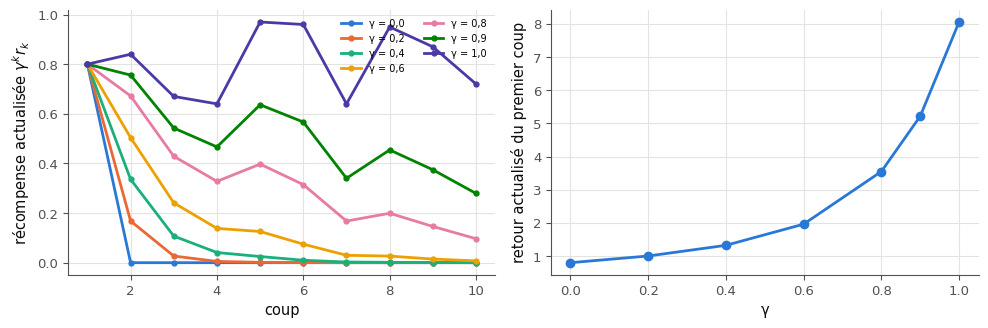

✅ Ex 26.15 : les retours actualisés du premier coup, de γ = 0 à γ = 1 : un tableau (7,), comme attendu.


In [30]:
def plot_discounting_15(rewards, gammas):
    """Two panels side by side. Left: for each gamma, the discounted rewards gamma**k * r_k of the moves
    k = 0, 1, ... (one line with markers per gamma, a legend). Right: the discounted return of the first move,
    mylearn.rl.discounted_return(rewards, gamma), for each gamma (gamma on the x axis). Ends with plt.show() and
    returns these returns as an array, in the order of `gammas`."""
    rewards = np.asarray(rewards, dtype=float)
    k = np.arange(len(rewards))
    returns = np.array([mylearn.rl.discounted_return(rewards, g) for g in gammas])
    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4))
    for g in gammas:
        left.plot(k + 1, g ** k * rewards, "o-", ms=3.5, label=f"γ = {fr(g, 1)}")
    left.set_xlabel("coup")
    left.set_ylabel("récompense actualisée $\\gamma^k r_k$")
    left.legend(fontsize=7, ncol=2)
    right.plot(gammas, returns, "o-")
    right.set_xlabel("γ")
    right.set_ylabel("retour actualisé du premier coup")
    plt.tight_layout()
    plt.show()
    return returns


with checked("26.15"):
    dfr_15 = plot_discounting_15(REWARDS_15, GAMMAS_15)
    if returned("26.15", "plot_discounting_15", dfr_15):
        same("26.15", "les retours actualisés du premier coup, de γ = 0 à γ = 1", dfr_15,
             [np.polynomial.polynomial.polyval(g, REWARDS_15) for g in GAMMAS_15])

### Ex 26.16 — Prédire l'effet du camion sur la table L 🔮 ★ ⏱️ 10 min
**Objectif :** prédire ce que le L-learning apprend sur Flippers, avec et sans le camion, avant de l'écrire.  
**Prérequis :** Ex 26.14 · 26.Q7 · fiche §26.5, §26.5.1 · **Fil rouge :** Flippers · **Parcours :** R, C

Le L-learning du livre (fiche §26.5) : une table L de 512 × 9 valeurs nulles ; dans chaque partie, l'agent joue l'action de plus grande valeur (ex æquo au hasard) ; à la fin, chaque coup joué reçoit son TFR, qui **remplace** la valeur de sa case. Le livre montre deux plateaux bien joués après 6 000 parties sans camion, et raconte comment un camion fait oublier un bon coup. La cellule suivante charge les résultats d'une expérience que tu refais en 26.18 avec ton propre code : pour cinq graines, une table entraînée 6 000 parties sans camion, une autre 6 000 parties avec un camion de probabilité 0,1 ; chaque agent joue ensuite les 506 plateaux non gagnants, une fois, gloutonnement et **sans** camion.

**Avant d'exécuter**, écris tes trois prédictions dans la cellule suivante :
a) sans camion, l'agent joue-t-il au moins 90 % des 506 plateaux en leur nombre minimal de coups ? (`True` ou `False`)
b) entraîné avec le camion, puis testé sans, gagne-t-il les 506 plateaux en 100 coups au plus ? (`True` ou `False`)
c) après 6 000 parties avec le camion, la part des cases de la table L encore à 0 (jamais jouées) : `"A"` moins de 25 %, `"B"` de 25 % à 75 %, `"C"` plus de 75 %.

La cellule d'expérience n'affiche rien tant que tes trois prédictions ne sont pas écrites.

In [31]:
# The L-learning results that 26.18 will reproduce (tools/chapters/history_ch26.py, five seeds): for each seed, the
# table after 6 000 games without the truck, and after 6 000 games with a truck of probability 0.1; each agent then
# played the 506 non-winning boards once, greedily, WITHOUT the truck
L_RESULTS_16 = unpack("eNqVk+tK61AQhV+l9LeEuV98lYOIaNDDqa20PQhK392dpNjG7GA7vybsYe8va9b6XG4377vl7eLP53LXtk+lg5vFcr/9//iv65vu632zLj32/eZt//f1YTWcqTMSKaWJkEWU89f2YX2/atfP+5cyQ2WIU0kt0TINtIx8tNvN/WO7Wu36WyIUy5GS9xWHm8UMC36zQJMCjihGoqBJ+QMNk801IpkCjIknaEiFn1nTgj1FzGtoUt7Q4KHkHA0vl4nYUQUVMN0oRKYw1hiBnni4BsMWZeZYNg9zrlMwjDYw0WnYi7gwxFQloqbTxgQYe8LqAg3MHaKiEl1hJuRyQyZBShj6VCRuPMggLLXYBV1qLM6WXv5qqHmWa8wkREmSgBjqjlWyM7MJ1sDQqRO5sj2+WKRfSbLR301NaCdXyzzJSKLjWswAPPscj310MlFnuOr28lxlvo5MLtcIySSIkIWLG5SmKOUpyTjlkqppi/SSGhlqnmWUNh+lZZK2cchFp2jRjGTGat4KeIjTsQ53hy8zfXdJ")   # packed, so that the numbers stay hidden until the experiment cell

In [32]:
optimal_16, all_won_16, zeros_16 = False, False, "C"

In [33]:
wb.record("26.16a", False, mistakes={"regarde la colonne « au minimum » des lignes sans camion": True})
wb.record("26.16b", False, mistakes={"regarde la colonne « gagnées » des lignes avec camion": True})
wb.record("26.16c", "C", mistakes={"regarde la colonne « cases à 0 » des lignes avec camion": "A",
                                   "la colonne « cases à 0 » dépasse-t-elle les trois quarts ?": "B"})

WB_ANSWER {"hash": "23ac1ca00f91ae43d848a47c2306136560b8d1dab160383c89152ae6ad5c7ac7", "id": "26.16a", "kind": "bool", "mistakes": {"945de5821f84ea71ce504123cfb2f273f8b5126ecbc1776bd30ed4af542dfe73": "regarde la colonne « au minimum » des lignes sans camion"}}
📝 Ex 26.16a : réponse enregistrée (bool).
WB_ANSWER {"hash": "0438fd2151737a54add316582ee7563dd18015c69b83da1199540411b006e682", "id": "26.16b", "kind": "bool", "mistakes": {"fc164eef3226084bf1c4acac778ab30b8f2a4b33b64b30e51817bd4823c815bf": "regarde la colonne « gagnées » des lignes avec camion"}}
📝 Ex 26.16b : réponse enregistrée (bool).
WB_ANSWER {"hash": "a660ae94f271825f7f52090d17e5cd60e3c32ce2d1c535e31437e4d1b2e6283c", "id": "26.16c", "kind": "str", "mistakes": {"5b8f2e101e5e17abad9b84ed0c11c0afd850005b6ebc378b66a7a7c980f1dc7a": "regarde la colonne « cases à 0 » des lignes avec camion", "5cf3ae8098865866732b5920e52f5be459936f8d31f9530bcdf5beb68be499e2": "la colonne « cases à 0 » dépasse-t-elle les trois quarts ?"}}
📝 Ex 26.

In [34]:
if any(answer is ... or answer is None for answer in [optimal_16, all_won_16, zeros_16]):
    print("⏳ Ex 26.16 : écris d'abord tes trois prédictions dans la cellule précédente.")
else:
    print(f"{'graine':>6s} {'camion':>7s} {'gagnées':>9s} {'au minimum':>11s} {'longueur moy.':>14s} {'cases à 0':>10s}")
    for row_16 in L_RESULTS_16["rows"]:
        print(f"{row_16['seed']:6d} {fr(row_16['truck'], 1):>7s} {pct(row_16['won']):>9s} {pct(row_16['optimal']):>11s} "
              f"{fr(row_16['mean_length'], 2):>14s} {pct(row_16['zero_cells']):>10s}")
    wb.check("26.16a", optimal_16)
    wb.check("26.16b", all_won_16)
    wb.check("26.16c", zeros_16)

graine  camion   gagnées  au minimum  longueur moy.  cases à 0
     0     0,0   100,0 %       5,7 %          20,04     88,5 %
     0     0,1    94,1 %      19,4 %          12,05     88,4 %
     1     0,0   100,0 %       2,4 %          16,62     88,4 %
     1     0,1    83,0 %      19,2 %          22,94     88,6 %
     2     0,0   100,0 %       5,1 %          13,78     88,7 %
     2     0,1    94,1 %      14,2 %          13,76     88,2 %
     3     0,0   100,0 %      14,2 %           9,55     88,2 %
     3     0,1    92,1 %      20,0 %          13,91     88,2 %
     4     0,0   100,0 %      11,3 %          10,85     88,4 %
     4     0,1    87,9 %      16,2 %          18,95     88,2 %
✅ Ex 26.16a : Bravo !
✅ Ex 26.16b : Exact !
✅ Ex 26.16c : Bien joué !


Dans tes notes : lesquelles de tes prédictions étaient justes ? Sans hasard et sans exploration, qu'est-ce qui pourrait faire changer une case déjà positive, et pourquoi l'agent n'essaie-t-il jamais les autres coups ? Avec le camion, comment une partie coupée à 100 coups peut-elle créer une boucle dont l'agent glouton ne sort plus ?

### Ex 26.17 — Flippers : la longueur optimale de chaque partie par recherche exhaustive 🔬 ★★ ⏱️ 25 min
**Objectif :** calculer, par une recherche en largeur, la partie la plus courte depuis chacun des 512 plateaux.  
**Prérequis :** 0A (boucles, listes) · ✏️ 26.2 · fiche §26.4 · **Fil rouge :** Flippers · **Parcours :** C

Pour juger un agent de Flippers, il faut savoir ce qu'il aurait pu faire de mieux. Le jeu est assez petit pour tout calculer : on part des 6 plateaux gagnants (0 coup), leurs voisins à un coup (une tuile retournée) en demandent 1, les voisins de ceux-là qui n'ont pas encore de valeur en demandent 2, et ainsi de suite. C'est une **recherche en largeur** (*breadth-first search*). Un coup se défait en retournant la même tuile : « être à $d$ coups d'une victoire » et « être à $d$ coups d'un plateau gagnant en partant de lui » reviennent au même.

**Contrat** : `min_moves_17()` rend un tableau d'entiers de forme `(512,)` : le nombre minimal de coups de chaque plateau (0 pour les 6 gagnants, `Flippers().winning`). Puis, à partir de **ton** tableau : `most_common_17` (la longueur minimale la plus fréquente), `mean_17` (sa moyenne sur les 506 plateaux non gagnants, à 2 décimales) et `hardest_17` (le code du plateau qui demande le plus de coups). N'utilise pas `Flippers().min_moves` : elle donne la réponse.

La vérification compare ton tableau à une recherche de référence, trace l'histogramme des longueurs, puis vérifie tes trois réponses et dessine le plateau le plus difficile.

Dans tes notes : le livre dit que « la plupart » des plateaux se gagnent en 3 ou 4 coups ; que dit ton histogramme ? Pourquoi le plateau le plus difficile en demande-t-il autant (regarde-le) ? Combien de plateaux une recherche en largeur visite-t-elle, et pourquoi la même méthode serait-elle impossible au go (✏️ 26.2) ?

✅ Ex 26.17 : les 512 longueurs minimales, comparées à une recherche de référence : un tableau (512,), comme attendu.


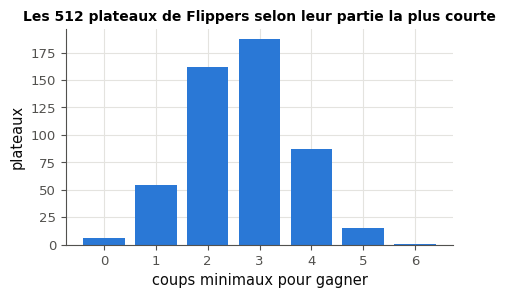

✅ Ex 26.17a : Exact !
✅ Ex 26.17b : Bien joué !
✅ Ex 26.17c : C'est ça !
[[1 1 1]
 [1 1 1]
 [1 1 1]]


In [35]:
def min_moves_17():
    """The minimal number of moves from each of the 512 boards to a winning board: an int array of shape (512,).
    A breadth-first search from the 6 winning boards (Flippers().winning): a move flips one tile, and flipping it
    again undoes it, so the boards one move from a winning board are its 9 neighbours, and so on."""
    dist = np.full(512, -1, dtype=int)
    frontier = sorted(Flippers().winning)
    dist[frontier] = 0
    while frontier:
        nxt = []
        for board in frontier:
            for tile in range(9):
                neighbour = board ^ (1 << tile)
                if dist[neighbour] < 0:
                    dist[neighbour] = dist[board] + 1
                    nxt.append(neighbour)
        frontier = nxt
    return dist


moves_17 = min_moves_17()
most_common_17 = int(np.bincount(moves_17).argmax())
mean_17 = round(moves_17[moves_17 > 0].mean(), 2)
hardest_17 = int(moves_17.argmax())


with checked("26.17"):
    moves_17 = min_moves_17()
    if returned("26.17", "min_moves_17", moves_17):
        reference_17 = wb.envs._flippers_distances(3)       # the reference search of wb.envs
        if same("26.17", "les 512 longueurs minimales, comparées à une recherche de référence", moves_17, reference_17):
            counts_17 = np.bincount(np.asarray(moves_17, dtype=int))
            plt.figure(figsize=(5, 2.8))
            plt.bar(range(len(counts_17)), counts_17, color=wb.plot.CATEGORICAL[0])
            plt.xlabel("coups minimaux pour gagner")
            plt.ylabel("plateaux")
            plt.title("Les 512 plateaux de Flippers selon leur partie la plus courte", fontsize=10)
            plt.show()
wb.check("26.17a", most_common_17)
wb.check("26.17b", mean_17)
wb.check("26.17c", hardest_17)
if filled(hardest_17):
    print(Flippers().board(hardest_17))

In [36]:
wb.record("26.17a", most_common_17, mistakes={"c'est la longueur de la plus longue partie, pas la plus fréquente": 6,
                                                "relis ton histogramme : quelle barre est la plus haute ?": 2})
wb.record("26.17b", mean_17, decimals=2, mistakes={"la moyenne porte sur les 506 plateaux non gagnants, sans les 6 gagnants": 2.67})
wb.record("26.17c", hardest_17)

WB_ANSWER {"hash": "201bd821e25df533d8fc3fd8a9445df90df0e094b74704c40ab9b516aa8aeb26", "id": "26.17a", "kind": "int", "magnitude": 0, "mistakes": {"a9f58af31c38fe1e5d2e76ffeec6604d5af465a35ce9f2e8b0ebcbb76afa7a35": "relis ton histogramme : quelle barre est la plus haute ?", "ecc9122b2398fb43591c314209a136a8c49def0dd2f0cdad3fde80a1c6bad2c1": "c'est la longueur de la plus longue partie, pas la plus fréquente"}, "sign": 1}
📝 Ex 26.17a : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "518f8fbaae972fe915a06000ee1d3a8dd0c9a65cab1a1b8f096f3a80fc9fa365", "hash_coarse": "ae3060d29c4a5c0891b8a3fa1790ced90d3c5b86f7cfe0d79fe4a2f9bb1207be", "id": "26.17b", "kind": "float", "magnitude": 0, "mistakes": {"df65f84fb14eb489f899055ab050b042ac0676f3c05a54234c1860aad5c31550": "la moyenne porte sur les 506 plateaux non gagnants, sans les 6 gagnants"}, "sign": 1}
📝 Ex 26.17b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "abfddc0cf700fcbf383a1b06a3f103fd18d055205ecadebdb3db0aa

### Ex 26.18 — L-learning sur Flippers, sans puis avec camion 🔬 ★★★ ⏱️ 40 min
**Objectif :** écrire le L-learning du livre et mesurer ce qu'il apprend sur les 506 plateaux, sans puis avec le camion.  
**Prérequis :** Ex 26.14 · Ex 26.17 · fiche §26.5, §26.5.1 · **Fil rouge :** Flippers · **Parcours :** C

Tu écris le L-learning du livre et tu refais l'expérience de 26.16 (une seule graine ici).

**Contrat** : `l_learning_18(env, n_games, rng, max_steps=100)` part d'une table `L = np.zeros((n_states, n_actions))`. Pour chaque partie : `env.reset(seed=int(rng.integers(2**31)))`, puis à chaque coup l'action `tie_argmax(L[state], rng)`, jusqu'à `terminated`, `truncated` ou `max_steps` coups. À la fin de la partie, chaque couple (état, action) joué reçoit son TFR, `mylearn.rl.returns_to_go(rewards)` ($\gamma = 1$), qui **remplace** la valeur de sa case, dans l'ordre des coups (un couple joué deux fois garde la valeur de son dernier coup). Elle rend `(L, lengths)` : la table et le nombre de coups de chaque partie.

La vérification fait jouer ta fonction 60 parties sur un Flippers au camion fréquent, en notant chaque coup (`GameRecorder`), puis refait la table attendue à partir des coups joués : elle vérifie ta règle de mise à jour, quel que soit l'ordre de tes tirages ; puis que les ex æquo d'une table nulle sont bien départagés au hasard. La cellule suivante entraîne quatre tables (3 000 et 6 000 parties, sans et avec camion ; une quinzaine de secondes), les fait jouer sur les 506 plateaux sans camion, trace les histogrammes des longueurs et montre la partie de chaque agent depuis un plateau qui se gagne en deux coups.

Dans tes notes : retrouves-tu l'amélioration que le livre montre entre 3 000 et 6 000 parties (fig. 26.23 à 26.26) ? Pourquoi, sans exploration, une table du L-learning cesse-t-elle presque de changer ? Le camion fait-il seulement du mal (regarde la part de plateaux joués au minimum) ? Qu'est-ce qui, dans le Q-learning, répond à chacun des défauts que tu observes ?

In [37]:
def l_learning_18(env, n_games, rng, max_steps=100):
    """The book's L-learning. L = np.zeros((n_states, n_actions)). For each game: state, info =
    env.reset(seed=int(rng.integers(2**31))), then at each move the action tie_argmax(L[state], rng) (the largest
    value, ties at random), until terminated or truncated or max_steps moves. At the end of the game, each
    (state, action) played receives its total future reward (mylearn.rl.returns_to_go of the rewards of the game,
    gamma = 1), which REPLACES the value in L, in the order of the moves (a pair played twice keeps the value of its
    last move). Returns (L, lengths): the table and the number of moves of each game (an int array)."""
    L = np.zeros((env.observation_space.n, env.action_space.n))
    lengths = []
    for _ in range(n_games):
        state, _ = env.reset(seed=int(rng.integers(2**31)))
        moves, rewards = [], []
        for _ in range(max_steps):
            action = tie_argmax(L[state], rng)
            next_state, reward, terminated, truncated, _ = env.step(action)
            moves.append((state, action))
            rewards.append(reward)
            state = next_state
            if terminated or truncated:
                break
        for (s, a), tfr in zip(moves, mylearn.rl.returns_to_go(rewards)):
            L[s, a] = tfr                                   # replace, never average
        lengths.append(len(moves))
    return L, np.array(lengths)


def expected_table_18(games, shape):
    """The L table that the replacement rule gives for these recorded games (whatever the policy)."""
    L = np.zeros(shape)
    for game in games:
        rewards = [r for _, _, r in game]
        tfr = np.cumsum(rewards[::-1])[::-1]
        for (s, a, _), value in zip(game, tfr):
            L[s, a] = value
    return L


with checked("26.18"):
    spy_18 = GameRecorder(Flippers(truck_prob=0.3))
    result_18 = l_learning_18(spy_18, 60, np.random.default_rng(18), max_steps=12)
    if returned("26.18", "l_learning_18", result_18):
        L_18, lengths_18 = result_18
        same("26.18", "la longueur de chaque partie jouée", lengths_18, [len(g) for g in spy_18.games])
        same("26.18", "la table L après 60 parties (camion 0,3, parties coupées à 12 coups), refaite à partir des coups "
             "joués", L_18, expected_table_18(spy_18.games, (512, 9)))
        verdict("26.18", max(len(g) for g in spy_18.games) <= 12, "aucune partie ne dépasse max_steps coups.",
                "une partie a dépassé max_steps coups.")
        ties_18 = GameRecorder(Flippers())
        l_learning_18(ties_18, 40, np.random.default_rng(1), max_steps=1)   # one move per game: the table stays ~ 0
        first_18 = {game[0][1] for game in ties_18.games}
        verdict("26.18", len(first_18) > 1, "avec une table nulle, les ex æquo sont départagés au hasard.",
                f"avec une table nulle, le premier coup est toujours {sorted(first_18)} : les ex æquo doivent être "
                "départagés au hasard (tie_argmax).")

✅ Ex 26.18 : la longueur de chaque partie jouée : un tableau (60,), comme attendu.


✅ Ex 26.18 : la table L après 60 parties (camion 0,3, parties coupées à 12 coups), refaite à partir des coups joués : un tableau (512, 9), comme attendu.
✅ Ex 26.18 : aucune partie ne dépasse max_steps coups.
✅ Ex 26.18 : avec une table nulle, les ex æquo sont départagés au hasard.


3000 parties, camion 0,0 : gagnées 100,0 % · au minimum de coups 7,7 % · longueur moyenne 15,57 (optimum 2,70) · la plus longue 45


6000 parties, camion 0,0 : gagnées 100,0 % · au minimum de coups 7,7 % · longueur moyenne 15,59 (optimum 2,70) · la plus longue 45


3000 parties, camion 0,1 : gagnées 86,0 % · au minimum de coups 18,4 % · longueur moyenne 20,46 (optimum 2,70) · la plus longue 100


6000 parties, camion 0,1 : gagnées 97,2 % · au minimum de coups 19,2 % · longueur moyenne 10,42 (optimum 2,70) · la plus longue 100


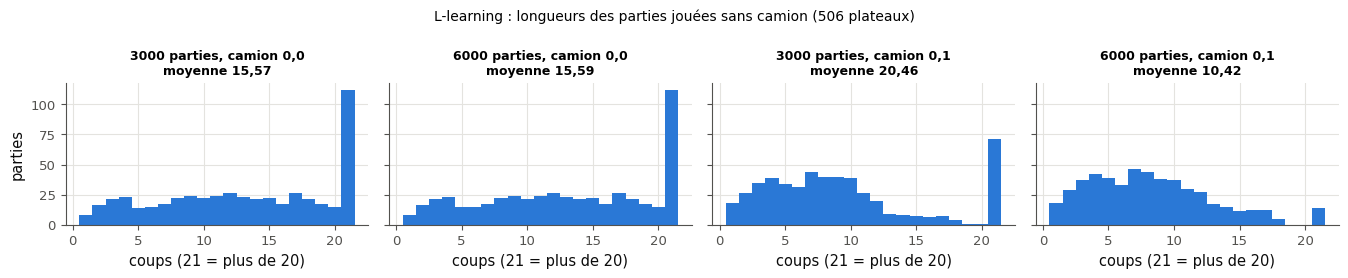

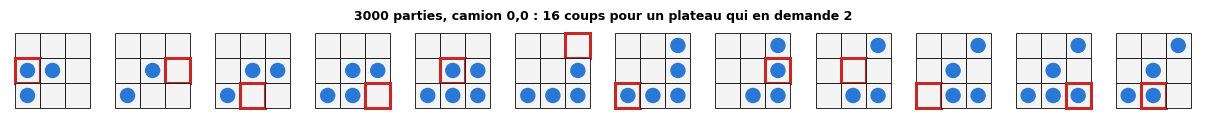

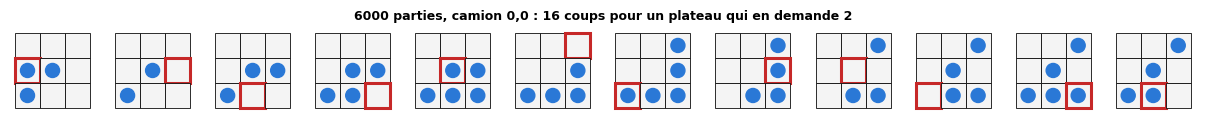

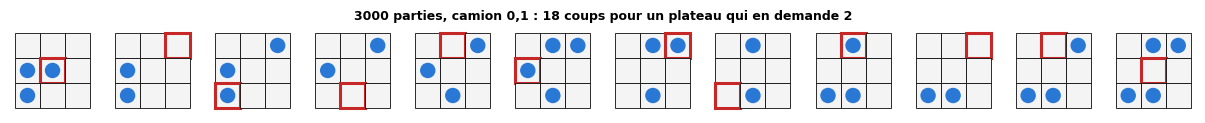

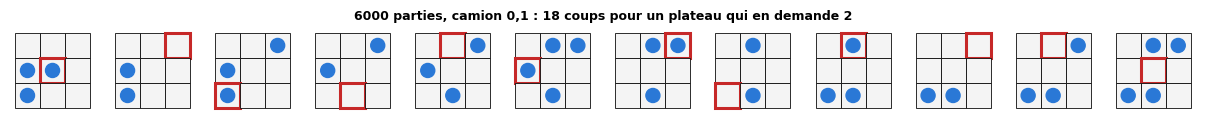

In [38]:
with checked("26.18"):
    results_18, tables_18 = {}, {}
    for truck_18 in (0.0, 0.1):
        for n_18 in (3000, 6000):
            L_18, _ = l_learning_18(Flippers(truck_prob=truck_18), n_18, np.random.default_rng(2618))
            label_18 = f"{n_18} parties, camion {fr(truck_18, 1)}"
            tables_18[label_18] = L_18
            results_18[label_18] = evaluate_flippers(L_18, truck_prob=0.0, seed=18)
            print(f"{label_18:24s} : {summary_flippers(results_18[label_18])}")
    length_histograms(results_18, "L-learning : longueurs des parties jouées sans camion (506 plateaux)")
    easy_18 = Flippers().encode([[0, 0, 0], [1, 1, 0], [1, 0, 0]])     # two moves from a win
    for label_18, L_18 in tables_18.items():
        env_18, rng_18 = Flippers(), np.random.default_rng(1)
        state_18, _ = env_18.reset(options={"state": easy_18})
        states_18, actions_18, done_18 = [state_18], [], False
        while not done_18:
            actions_18.append(tie_argmax(L_18[state_18], rng_18))
            state_18, _, term_18, trunc_18, _ = env_18.step(actions_18[-1])
            states_18.append(state_18)
            done_18 = term_18 or trunc_18
        plot_flippers_game(states_18[:12], actions_18[:12],
                           title=f"{label_18} : {len(actions_18)} coups pour un plateau qui en demande 2")
        plt.show()

## Partie B · Le cœur de ta librairie `rl.py`

Tu écris dans `rl.py` les politiques (26.19), les mises à jour du Q-learning et de SARSA (26.20), puis la boucle d'entraînement et l'évaluation d'une politique (26.21). Les parties C à F s'en servent : leurs expériences appellent **ta** librairie.

### Ex 26.19 — Politiques gloutonne et softmax (ε-greedy importée du ch. 11) 🔨 ★★★ ⏱️ 35 min
**Objectif :** écrire la politique gloutonne d'une table et le tirage softmax d'une action dans ta librairie.  
**Prérequis :** ✏️ 26.5 · ch. 11 (ε-greedy, `argmax_random_tie`) · fiche §26.6.2 · **mylearn :** `rl.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/rl.py` (créé par `python tools/start_chapter.py 26`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; `rl.py` importe déjà `argmax_random_tie`, `epsilon_greedy_action` et `incremental_update` de ton `bandit.py` (ch. 11 ; la référence les remplace si tu ne l'as pas écrit). La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch26_rl.py -q` les lance tous dans un terminal.

**Contrat commun de `rl.py`** (les docstrings, plus ces précisions que vérifient les tests) : une entrée invalide lève `ValueError`, jamais `IndexError` ni `TypeError` : $\gamma$ hors de $[0, 1]$, $\alpha$ hors de $]0, 1]$, $\varepsilon$ hors de $[0, 1]$, une température $\le 0$ ou NaN, un NaN dans les récompenses, dans les valeurs ou dans la table, un état ou une action hors de `0 .. n - 1` (−1 compris, jamais ramené au dernier indice), booléen ou non entier (`0.5`) ; les entiers de NumPy sont acceptés. Les listes et les tuples sont acceptés en entrée ; chaque tableau rendu est un **nouveau** tableau `float64` (des entiers pour une politique), et une valeur seule est un `float` Python (`float(...)`), un indice un `int` Python.

Écris `greedy_policy(Q)` et `softmax_action(q_values, temperature=1.0, rng=None)`. **Contrat** propre à ces deux fonctions :
- `greedy_policy` rend un tableau d'**entiers**, une action par ligne de `Q` (2-D), les ex æquo allant au plus petit indice (comme `np.argmax`), pour qu'une politique soit reproductible ;
- `softmax_action` soustrait le maximum avant l'exponentielle (pas de débordement pour des valeurs de l'ordre de $10^4$), puis fait **un seul** tirage par appel : `rng.choice(len(q), p=probs)` (les tests comparent tes tirages à ceux d'un générateur de même graine) ; il rend un `int` Python ; `rng=None` crée un générateur ;
- ε-greedy n'est pas à réécrire : c'est `epsilon_greedy_action` de ton `bandit.py` (ch. 11), qui explore parmi **toutes** les actions et départage les ex æquo au hasard.

La première cellule de vérification essaie tes fonctions, compare les fréquences de 20 000 tirages softmax à la formule, et trace les trois politiques sur une même ligne. La seconde lance les tests (`-k "test_greedy_policy_ or test_softmax_action_"`).

Dans tes notes : pourquoi la politique gloutonne de l'**évaluation** peut-elle départager les ex æquo vers le plus petit indice, alors que celle de l'**entraînement** doit les départager au hasard (26.24 y revient) ? Quelle température donnerait des fréquences proches de celles d'ε-greedy sur cette ligne ?

✅ Ex 26.19 : greedy_policy : la meilleure action de chaque ligne, ex æquo vers le plus petit indice : [1.0, 0.0, 1.0], comme attendu.
✅ Ex 26.19 : softmax_action : un T minuscule choisit la meilleure action : 1.0, comme attendu.


✅ Ex 26.19 : softmax_action laisse q_values intact.
✅ Ex 26.19 : softmax (T = 0,8) sur 20 000 tirages : fréquences [0.023 0.073 0.893 0.011], attendu [0.021 0.073 0.894 0.011].
✅ Ex 26.19 : softmax_action sur des valeurs énormes (1e4) : pas de débordement : 1.0, comme attendu.
✅ Ex 26.19 : température nulle : ValueError levée (temperature must be > 0, got 0.0).


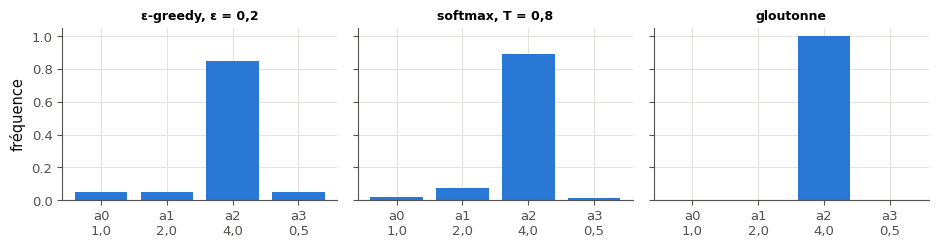

In [39]:
# Nothing to write here: greedy_policy and softmax_action go in mon_travail/mylearn/rl.py

with checked("26.19"):
    R = mylearn.rl
    same("26.19", "greedy_policy : la meilleure action de chaque ligne, ex æquo vers le plus petit indice",
         R.greedy_policy([[0.0, 1.0, 0.5], [2.0, 2.0, -1.0], [-3.0, -1.0, -1.0]]), [1, 0, 1])
    a_19 = R.softmax_action([0.0, 3.0, 1.0], temperature=1e-3, rng=np.random.default_rng(0))
    if not returned("26.19", "softmax_action", a_19):
        raise StopCheck
    if type(a_19) is not int:
        print(f"❌ Ex 26.19 : softmax_action doit rendre un int Python (un indice d'action), reçu {a_19!r} "
              f"({type(a_19).__name__}) : convertis avec int(...).")
        raise StopCheck
    same("26.19", "softmax_action : un T minuscule choisit la meilleure action", a_19, 1)
    q_19, T_19 = np.array([1.0, 2.0, 4.0, 0.5]), 0.8
    want_19 = np.exp(q_19 / T_19) / np.exp(q_19 / T_19).sum()   # computed before the draws, on the original row
    rng_19 = np.random.default_rng(19)
    draws_19 = np.array([R.softmax_action(q_19.copy(), T_19, rng_19) for _ in range(20_000)], dtype=int)
    freq_19 = np.bincount(draws_19, minlength=4) / draws_19.size
    probe_19 = q_19.copy()
    R.softmax_action(probe_19, T_19, np.random.default_rng(0))
    verdict("26.19", np.array_equal(probe_19, q_19), "softmax_action laisse q_values intact.",
            "softmax_action a modifié q_values : travaille sur une copie.")
    verdict("26.19", np.abs(freq_19 - want_19).max() < 0.015,
            f"softmax (T = 0,8) sur 20 000 tirages : fréquences {np.round(freq_19, 3)}, attendu {np.round(want_19, 3)}.",
            f"softmax (T = 0,8) : fréquences {np.round(freq_19, 3)}, loin de exp(q / T) normalisé {np.round(want_19, 3)}.")
    same("26.19", "softmax_action sur des valeurs énormes (1e4) : pas de débordement",
         R.softmax_action([1e4, 1e4 + 50.0], temperature=1.0, rng=np.random.default_rng(1)), 1)
    refuses("26.19", "température nulle", lambda: R.softmax_action([1.0, 2.0], temperature=0.0))
    # epsilon-greedy comes from chapter 11 (mylearn.bandit): the three policies on the same row
    rng_19 = np.random.default_rng(190)
    eps_19 = np.bincount([mylearn.bandit.epsilon_greedy_action(q_19, 0.2, rng_19) for _ in range(20_000)],
                         minlength=4) / 20_000
    fig_19, axes_19 = plt.subplots(1, 3, figsize=(9.5, 2.6), sharey=True)
    for ax_19, (title_19, p_19) in zip(axes_19, [("ε-greedy, ε = 0,2", eps_19), ("softmax, T = 0,8", freq_19),
                                                 ("gloutonne", np.eye(4)[int(R.greedy_policy([q_19])[0])])]):
        ax_19.bar(range(4), p_19, color=wb.plot.CATEGORICAL[0])
        ax_19.set_xticks(range(4), [f"a{j}\n{fr(v, 1)}" for j, v in enumerate(q_19)])
        ax_19.set_title(title_19, fontsize=9)
    axes_19[0].set_ylabel("fréquence")
    plt.tight_layout()
    plt.show()

In [40]:
if written(lambda: mylearn.rl.greedy_policy([[0.0, 1.0]])):
    run_pytest_group(TEST_RL, impl="ref", keyword="test_greedy_policy_ or test_softmax_action_")
else:
    print("⏳ Ex 26.19 : les tests attendent tes fonctions.")

pytest: 26 passed, 182 deselected in 9.15s


### Ex 26.20 — Mises à jour de Q-learning et de SARSA, états terminaux compris 🔨 ★★★ ⏱️ 75 min
**Objectif :** écrire les mises à jour du Q-learning et de SARSA, avec les états terminaux et les masques d'actions.  
**Prérequis :** ✏️ 26.3 · ✏️ 26.4 · fiche §26.6.1, §26.6.3, §26.7 · **mylearn :** `rl.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/rl.py` (créé par `python tools/start_chapter.py 26`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; `rl.py` importe déjà `argmax_random_tie`, `epsilon_greedy_action` et `incremental_update` de ton `bandit.py` (ch. 11 ; la référence les remplace si tu ne l'as pas écrit). La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch26_rl.py -q` les lance tous dans un terminal.

**Contrat commun de `rl.py`** (les docstrings, plus ces précisions que vérifient les tests) : une entrée invalide lève `ValueError`, jamais `IndexError` ni `TypeError` : $\gamma$ hors de $[0, 1]$, $\alpha$ hors de $]0, 1]$, $\varepsilon$ hors de $[0, 1]$, une température $\le 0$ ou NaN, un NaN dans les récompenses, dans les valeurs ou dans la table, un état ou une action hors de `0 .. n - 1` (−1 compris, jamais ramené au dernier indice), booléen ou non entier (`0.5`) ; les entiers de NumPy sont acceptés. Les listes et les tuples sont acceptés en entrée ; chaque tableau rendu est un **nouveau** tableau `float64` (des entiers pour une politique), et une valeur seule est un `float` Python (`float(...)`), un indice un `int` Python.

Écris `q_learning_update(Q, state, action, reward, next_state, terminated, alpha, gamma, next_mask=None)` et `sarsa_update(Q, state, action, reward, next_state, next_action, terminated, alpha, gamma)`. **Contrat** propre à ces deux fonctions :
- `Q` est un tableau NumPy de **flottants**, modifié sur place (une table d'entiers est refusée : `Q[s, a] += 0.45` y serait arrondi) ; seule la case `Q[state, action]` change ;
- la fonction rend l'erreur TD $\delta$, calculée **avant** la mise à jour, en `float` Python ; une transition vers le même état utilise les valeurs d'avant ;
- `terminated=True` : la cible vaut `reward`, même si la ligne de `next_state` n'est pas nulle ; le masque et `next_action` (même `None`) sont alors ignorés. Une coupure (`truncated`) n'est **pas** une fin : on passe `terminated=False` ;
- `next_mask` : les actions permises dans $s'$, en booléens ou en entiers 0/1 (le `int8` de Gymnasium : convertis avec `.astype(bool)`) ; le max ne porte que sur elles ; un masque de mauvaise longueur, ou entièrement faux alors que `terminated` est faux, lève `ValueError`.

La première cellule de vérification essaie tes fonctions sur une petite table ; la seconde lance les tests (`-k "test_q_learning_update_ or test_sarsa_update_"`).

Dans tes notes : pourquoi la mise à jour doit-elle rendre $\delta$ calculé **avant** de modifier la table ? Dans quel cas les deux mises à jour donnent-elles la même valeur (✏️ 26.4) ?

In [41]:
# Nothing to write here: q_learning_update and sarsa_update go in mon_travail/mylearn/rl.py

with checked("26.20"):
    R = mylearn.rl
    Q_20 = np.array([[0.2, 0.4], [1.0, 0.6], [0.0, 0.0]])
    delta_20 = R.q_learning_update(Q_20, 0, 1, reward=0.5, next_state=1, terminated=False, alpha=0.5, gamma=0.8)
    same("26.20", "q_learning_update : l'erreur TD, 0,5 + 0,8 × 1 − 0,4", delta_20, 0.9)
    same("26.20", "… et la table, modifiée sur place (une seule case)", Q_20, [[0.2, 0.85], [1.0, 0.6], [0.0, 0.0]])
    Q_20 = np.array([[0.2, 0.4], [1.0, 0.6], [0.0, 0.0]])
    R.q_learning_update(Q_20, 0, 1, reward=0.5, next_state=1, terminated=True, alpha=0.5, gamma=0.8)
    same("26.20", "état suivant terminal : la cible vaut r, quelle que soit la ligne de s'", Q_20[0, 1], 0.45)
    Q_20 = np.array([[0.2, 0.4], [1.0, 0.6], [0.0, 0.0]])
    R.q_learning_update(Q_20, 0, 1, 0.5, 1, False, 0.5, 0.8, next_mask=np.array([0, 1], dtype=np.int8))
    same("26.20", "avec un masque : le max ne porte que sur les actions permises de s'", Q_20[0, 1], 0.69)
    Q_20 = np.array([[0.2, 0.4], [1.0, 0.6], [0.0, 0.0]])
    delta_20 = R.sarsa_update(Q_20, 0, 1, reward=0.5, next_state=1, next_action=1, terminated=False, alpha=0.5,
                              gamma=0.8)
    same("26.20", "sarsa_update : la cible prend Q(s', a') de l'action suivante choisie", delta_20, 0.5 + 0.8 * 0.6 - 0.4)
    refuses("26.20", "alpha = 0", lambda: R.q_learning_update(np.zeros((2, 2)), 0, 0, 1.0, 1, False, 0.0, 0.9))
    refuses("26.20", "état −1", lambda: R.sarsa_update(np.zeros((2, 2)), -1, 0, 1.0, 1, 0, False, 0.5, 0.9))

✅ Ex 26.20 : q_learning_update : l'erreur TD, 0,5 + 0,8 × 1 − 0,4 : 0.9, comme attendu.
✅ Ex 26.20 : … et la table, modifiée sur place (une seule case) : [[0.2, 0.85], [1.0, 0.6], [0.0, 0.0]], comme attendu.
✅ Ex 26.20 : état suivant terminal : la cible vaut r, quelle que soit la ligne de s' : 0.45, comme attendu.
✅ Ex 26.20 : avec un masque : le max ne porte que sur les actions permises de s' : 0.69, comme attendu.
✅ Ex 26.20 : sarsa_update : la cible prend Q(s', a') de l'action suivante choisie : 0.58, comme attendu.
✅ Ex 26.20 : alpha = 0 : ValueError levée (alpha must be in (0, 1], got 0.0).
✅ Ex 26.20 : état −1 : ValueError levée (state must be in 0 .. 1, got -1).


In [42]:
if written(lambda: mylearn.rl.q_learning_update(np.zeros((2, 2)), 0, 0, 1.0, 1, True, 0.5, 0.9)):
    run_pytest_group(TEST_RL, impl="ref", keyword="test_q_learning_update_ or test_sarsa_update_")
else:
    print("⏳ Ex 26.20 : les tests attendent tes fonctions.")

pytest: 55 passed, 153 deselected in 1.92s


### Ex 26.21 — La boucle d'entraînement tabulaire et l'évaluation d'une politique 🔨 ★★★ ⏱️ 90 min
**Objectif :** écrire la boucle d'entraînement du Q-learning et de SARSA, masques d'actions compris, et l'évaluation d'une politique.  
**Prérequis :** Ex 26.19 · Ex 26.20 · Ex 26.13 · fiche §26.6.3, §26.6.4, §26.7 · **Fil rouge :** FrozenLake · **mylearn :** `rl.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/rl.py` (créé par `python tools/start_chapter.py 26`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; `rl.py` importe déjà `argmax_random_tie`, `epsilon_greedy_action` et `incremental_update` de ton `bandit.py` (ch. 11 ; la référence les remplace si tu ne l'as pas écrit). La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch26_rl.py -q` les lance tous dans un terminal.

**Contrat commun de `rl.py`** (les docstrings, plus ces précisions que vérifient les tests) : une entrée invalide lève `ValueError`, jamais `IndexError` ni `TypeError` : $\gamma$ hors de $[0, 1]$, $\alpha$ hors de $]0, 1]$, $\varepsilon$ hors de $[0, 1]$, une température $\le 0$ ou NaN, un NaN dans les récompenses, dans les valeurs ou dans la table, un état ou une action hors de `0 .. n - 1` (−1 compris, jamais ramené au dernier indice), booléen ou non entier (`0.5`) ; les entiers de NumPy sont acceptés. Les listes et les tuples sont acceptés en entrée ; chaque tableau rendu est un **nouveau** tableau `float64` (des entiers pour une politique), et une valeur seule est un `float` Python (`float(...)`), un indice un `int` Python.

Écris `train_tabular(env, n_episodes, *, algorithm="q_learning", alpha=0.1, gamma=0.99, epsilon=0.1, max_steps=200, Q_init=None, rng=None)` et `evaluate_policy(env, policy, n_episodes=100, *, max_steps=200, rng=None)`. **Contrat** propre à ces deux fonctions (les tests rejouent tes épisodes pas à pas) :
- chaque épisode commence par `env.reset(seed=int(rng.integers(2**31)))` : le **premier** tirage de l'épisode, un `int` Python (Gymnasium refuse un `np.int64`), un nouveau à chaque épisode ;
- `epsilon` est une constante ou une fonction `épisode -> epsilon`, appelée pour `i = 0 .. n_episodes - 1` ; la valeur utilisée va dans `history["epsilons"]` ; l'exploration passe par `epsilon_greedy_action` (ch. 11), qui départage les ex æquo au hasard ;
- aucun pas après la fin d'un épisode ; `history["lengths"]` compte les appels à `env.step`, `history["returns"]` la somme non actualisée des récompenses ; atteindre `max_steps` ou `truncated` garde l'amorçage, `terminated` non ;
- quand `info` contient `"action_mask"` (booléens ou `int8`) : l'exploration porte sur `Q[s, légales]` puis se réindexe, les cases illégales ne changent jamais, et le max du Q-learning utilise le masque de l'état **suivant** ;
- SARSA choisit l'action suivante **avant** la mise à jour, s'en sert, puis la joue ;
- `Q_init` est copiée (une forme fausse lève `ValueError`) ; le même générateur donne la même table et le même historique, sans aucun état aléatoire global ;
- `evaluate_policy` tire les graines de `reset` comme `train_tabular`, accepte une table d'actions (liste ou tableau d'entiers ; une table de flottants ou 2-D est refusée) ou une fonction `(state, info) -> action`, et rend exactement trois `float` Python : `"mean_return"`, `"std_return"` (écart type de population) et `"mean_length"`.

La première cellule de vérification essaie `evaluate_policy` sur l'exemple de la docstring, entraîne 300 épisodes sur FrozenLake sans glissade, vérifie la reproductibilité et dessine la politique apprise. La seconde lance les tests (`-k "test_train_tabular_ or test_evaluate_policy_"`, une vingtaine de secondes).

Dans tes notes : pourquoi les graines de `reset` doivent-elles venir de `rng`, et pas de `reset()` sans graine ? Que se passerait-il si la boucle mettait à jour la table après un pas qui a coupé l'épisode à `max_steps`, en le traitant comme une fin ?

In [43]:
# Nothing to write here: train_tabular and evaluate_policy go in mon_travail/mylearn/rl.py

with checked("26.21"):
    R = mylearn.rl
    lake_21 = make_env("FrozenLake-v1", seed=0, is_slippery=False)
    policy_21 = np.zeros(16, dtype=int)
    policy_21[[0, 1, 14]] = 2
    policy_21[[2, 6, 10]] = 1
    same("26.21", "evaluate_policy de l'exemple de la docstring", list(R.evaluate_policy(lake_21, policy_21, 5).values()),
         [1.0, 0.0, 6.0])
    result_21 = R.train_tabular(lake_21, 300, alpha=0.5, gamma=0.95, epsilon=0.2, max_steps=100,
                                rng=np.random.default_rng(21))
    if returned("26.21", "train_tabular", result_21):
        Q_21, history_21 = result_21
        verdict("26.21", sorted(history_21) == ["epsilons", "lengths", "returns"], "l'historique a ses trois clés.",
                f"l'historique doit avoir les clés epsilons, lengths et returns, reçu {sorted(history_21)}.")
        again_21 = R.train_tabular(lake_21, 300, alpha=0.5, gamma=0.95, epsilon=0.2, max_steps=100,
                                   rng=np.random.default_rng(21))[0]
        same("26.21", "le même générateur donne la même table", again_21, Q_21)
        score_21 = R.evaluate_policy(lake_21, R.greedy_policy(Q_21), 10, max_steps=100)
        verdict("26.21", score_21["mean_return"] == 1.0,
                f"après 300 épisodes, la politique gloutonne atteint le but en {fr(score_21['mean_length'], 0)} pas.",
                f"après 300 épisodes, la politique gloutonne n'atteint pas toujours le but (réussite "
                f"{pct(score_21['mean_return'])}) : relis la boucle et les mises à jour.")
        show_lake_policy(R.greedy_policy(Q_21), title="la politique gloutonne apprise :")

✅ Ex 26.21 : evaluate_policy de l'exemple de la docstring : [1.0, 0.0, 6.0], comme attendu.
✅ Ex 26.21 : l'historique a ses trois clés.


✅ Ex 26.21 : le même générateur donne la même table : un tableau (16, 4), comme attendu.
✅ Ex 26.21 : après 300 épisodes, la politique gloutonne atteint le but en 6 pas.
la politique gloutonne apprise :
↓ ← ↓ ←
↓ H ↓ H
→ → ↓ H
H ↑ → G


In [44]:
if written(lambda: mylearn.rl.evaluate_policy(make_env('FrozenLake-v1', is_slippery=False), [0] * 16, 1)):
    run_pytest_group(TEST_RL, impl="ref", keyword="test_train_tabular_ or test_evaluate_policy_")
else:
    print("⏳ Ex 26.21 : les tests attendent tes fonctions.")

pytest: 54 passed, 154 deselected in 7.24s


## Partie C · Le Q-learning en action

Tu entraînes ta boucle sur FrozenLake, avec et sans glissade (26.22), tu lis des courbes d'apprentissage (26.23), tu répares une boucle qui n'apprend rien (26.24), tu refais l'expérience du livre sur Flippers avec camion (26.25), tu calcules la référence exacte par l'itération sur les valeurs (26.26), puis tu balayes $\alpha$, $\gamma$ et le niveau de hasard (26.27).

### Ex 26.22 — Q-learning sur FrozenLake, glissant ou non 📦 ★★ ⏱️ 25 min
**Objectif :** entraîner un Q-learning avec un $\varepsilon$ qui décroît, et comparer un lac déterministe à un lac glissant.  
**Prérequis :** Ex 26.21 · fiche §26.6.2 (encadré 🕰️), §26.6.5 · **Fil rouge :** FrozenLake · **Parcours :** R, M, C

Ta boucle `train_tabular` sur FrozenLake, avec un $\varepsilon$ qui décroît : on explore beaucoup au début, quand la table ne sait rien, puis de moins en moins.

**Contrat**
- `epsilon_schedule_22(n_episodes, start=1.0, end=0.05, fraction=0.8)` rend une fonction `épisode -> epsilon` : `start` à l'épisode 0, une baisse linéaire jusqu'à `end` à l'épisode `fraction * n_episodes`, puis `end` ;
- `train_lake_22(slippery, n_episodes, seed=0)` crée le lac (`make_env("FrozenLake-v1", seed=0, is_slippery=slippery)`), l'entraîne avec `mylearn.rl.train_tabular` ($\alpha = 0{,}1$, $\gamma = 0{,}99$, ton calendrier, `max_steps=100`, `rng=np.random.default_rng(seed)`) et rend `(env, Q, history)`.

La vérification essaie ton calendrier, puis entraîne 500 épisodes sans glissade et 4 000 sur la glace glissante (une dizaine de secondes) : elle évalue chaque politique gloutonne sur 1 000 épisodes, la dessine et trace les deux courbes d'apprentissage.

Dans tes notes : pourquoi la politique du lac glissant fait-elle parfois des détours, ou va-t-elle même contre le mur (regarde les cases voisines des trous) ? Que vaut la réussite pendant l'entraînement, comparée à celle de la politique gloutonne, et pourquoi ?

✅ Ex 26.22 : epsilon aux épisodes 0, 40, 80 et 99 (100 épisodes) : [1.0, 0.525, 0.05, 0.05], comme attendu.


sans glissade  (500 épisodes) : la politique gloutonne réussit 100,0 % des épisodes, en 6,0 pas en moyenne
↓ ← ← ←
↓ H ↓ H
→ → ↓ H
H → → G


glissant       (4000 épisodes) : la politique gloutonne réussit 74,9 % des épisodes, en 44,0 pas en moyenne
← ↑ ↑ ↑
← H ← H
↑ ↓ ← H
H → ↓ G


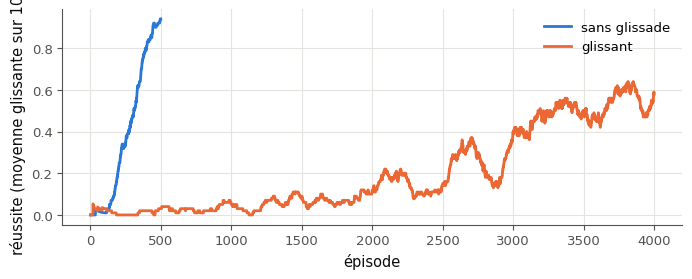

✅ Ex 26.22 : sans glissade, la politique apprise réussit toujours.
✅ Ex 26.22 : sur la glace glissante, la politique apprise réussit au moins 40 % du temps.


In [45]:
def epsilon_schedule_22(n_episodes, start=1.0, end=0.05, fraction=0.8):
    """A function episode -> epsilon: `start` at episode 0, decreasing linearly to `end` at episode
    fraction * n_episodes, then constant at `end`."""
    def epsilon(i):
        return max(end, start - (start - end) * i / (fraction * n_episodes))
    return epsilon


def train_lake_22(slippery, n_episodes, seed=0):
    """Q-learning on FrozenLake-v1 (make_env("FrozenLake-v1", seed=0, is_slippery=slippery)) with
    mylearn.rl.train_tabular: alpha=0.1, gamma=0.99, epsilon=epsilon_schedule_22(n_episodes), max_steps=100,
    rng=np.random.default_rng(seed). Returns (env, Q, history)."""
    env = make_env("FrozenLake-v1", seed=0, is_slippery=slippery)
    Q, history = mylearn.rl.train_tabular(env, n_episodes, alpha=0.1, gamma=0.99,
                                          epsilon=epsilon_schedule_22(n_episodes), max_steps=100,
                                          rng=np.random.default_rng(seed))
    return env, Q, history


with checked("26.22"):
    schedule_22 = epsilon_schedule_22(100)
    if returned("26.22", "epsilon_schedule_22", schedule_22):
        same("26.22", "epsilon aux épisodes 0, 40, 80 et 99 (100 épisodes)", [schedule_22(i) for i in (0, 40, 80, 99)],
             [1.0, 0.525, 0.05, 0.05])
    lakes_22 = {}
    for slippery_22, n_22 in ((False, 500), (True, 4000)):
        result_22 = train_lake_22(slippery_22, n_22, seed=22)
        if not returned("26.22", "train_lake_22", result_22):
            raise StopCheck
        env_22, Q_22, history_22 = result_22
        score_22 = mylearn.rl.evaluate_policy(env_22, mylearn.rl.greedy_policy(Q_22), 1000, max_steps=100,
                                              rng=np.random.default_rng(22))
        name_22 = "glissant" if slippery_22 else "sans glissade"
        lakes_22[name_22] = (Q_22, history_22, score_22)
        print(f"{name_22:14s} ({n_22} épisodes) : la politique gloutonne réussit {pct(score_22['mean_return'])} des "
              f"épisodes, en {fr(score_22['mean_length'], 1)} pas en moyenne")
        show_lake_policy(mylearn.rl.greedy_policy(Q_22))
    plt.figure(figsize=(8, 2.8))
    for name_22, (_, history_22, _) in lakes_22.items():
        plt.plot(moving_average(history_22["returns"], 100), label=name_22)
    plt.xlabel("épisode")
    plt.ylabel("réussite (moyenne glissante sur 100)")
    plt.legend()
    plt.show()
    verdict("26.22", lakes_22["sans glissade"][2]["mean_return"] == 1.0, "sans glissade, la politique apprise réussit "
            "toujours.", "sans glissade, la politique apprise ne réussit pas toujours : relis ton calendrier d'ε.")
    verdict("26.22", lakes_22["glissant"][2]["mean_return"] >= 0.4, "sur la glace glissante, la politique apprise "
            "réussit au moins 40 % du temps.", "sur la glace glissante, moins de 40 % de réussite : relis les "
            "réglages de train_lake_22.")

### Ex 26.23 — Lire des courbes d'apprentissage RL bruitées 📈 ★★ ⏱️ 15 min
**Objectif :** relier des courbes d'apprentissage de RL à leurs réglages, et juger ce qu'elles disent de la politique apprise.  
**Prérequis :** Ex 26.22 · fiche §26.6.2, §26.6.5 · **Fil rouge :** FrozenLake · **Parcours :** R, C

Quatre entraînements sur le lac glissant, de 4 000 épisodes chacun, sous des lettres mélangées : $\varepsilon$ décroissant de 1 à 0,05 avec $\alpha = 0{,}1$ (comme en 26.22) ; $\varepsilon = 0$ (aucune exploration, ex æquo au hasard seulement) avec $\alpha = 0{,}1$ ; $\varepsilon$ décroissant avec $\alpha = 1$ ; $\varepsilon = 0{,}5$ constant avec $\alpha = 0{,}1$. À gauche, la réussite **pendant** l'entraînement (moyenne glissante sur 100 épisodes) ; à droite, la réussite de la politique gloutonne de chacun, mesurée ensuite sur 1 000 épisodes.

Réponds dans la cellule suivante :
a) la lettre de l'entraînement à $\varepsilon$ décroissant et $\alpha = 0{,}1$ ;
b) la lettre de l'entraînement à $\varepsilon = 0{,}5$ constant ;
c) le nombre d'entraînements dont la politique gloutonne réussit au moins une fois sur deux ;
d) `True` ou `False` : pour chaque entraînement, la fin de la courbe d'apprentissage estime bien la réussite de sa politique gloutonne.

Dans tes notes : lesquels des deux entraînements restants ont $\varepsilon = 0$ et $\alpha = 1$, et sur quoi t'appuies-tu ? Pourquoi un $\alpha = 1$ échoue-t-il sur ce lac (fiche, encadré sur $\alpha$) ? Que faudrait-il tracer pendant l'entraînement pour suivre la politique elle-même ?

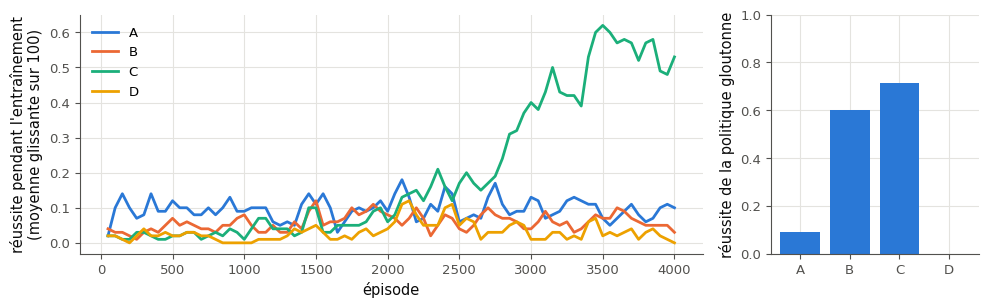

In [46]:
# Four trainings on the slippery lake (tools/chapters/history_ch26.py): the moving average (100 episodes) of the
# training returns every 50 episodes, and the success of each greedy policy over 1 000 episodes
RUNS_23 = unpack("eNqNlcGKGzEMhl8l5ByWkWR7Znprt29RSg/ZofTSloQUypJ33+q32fljZUIv4scj65Ml2fO6X37/OP96Wc77D7sveTjsZHDjSl2pK3NlrpKr5Cq7yq6Kq+JqdDW6mlxNrmZXc4sMC10x4AhAApIAJWAJYAKa5JoWNIACogApYAqgAqoAK3M7Byw0uFrPVw8IroKr4Cq4Cq7mWgRocBVcBVfBVXAVXAVX51Y1WGhwDVwD12pla2nBNXANXMu15NDgGrgGroFr4Bq4Bq7NrUfD18Nuf7r89K6+7j/CHi+nP4t3eXga9LAbngQmvcthhJ3W5WFerdCe1a95d1Is7O42F9jca+GcQn5G7mtUBigt1I0T5VPWUwpvLXTi0lei+SOC8N4pnNEoh7H3afUjn3ZArn0mPQcW508BvNffT8vy8vfb+XI8LmfvugfQ678vn0LzExWz2poyF5l9ckiQu5c2/HMoQw7cuFIoGpXthtuX4abK1FfuH6fDBefo7B7P0w96cxxD2qmf0jvDbsEzxOSDjCFMtLYxBmUQH4Pn+2/ATevl4WAIrWjwlLCuoZBCK2MoNluKI/39t4dlCK8DlbddvvowZLqI8FGhx0DX606ybaoaDEUww1aDp+FrXQY1gZpXmXS1higZ6yAXfZcZkfJEWvv1hP2p+myNwCh4CT7/xwiEzulGX3VjVkKwe0Y2bByZFN6J6B/fLb1/yYR/EtP9AeI3OYfLF+fQNp5FeXivYvolPEq2cZSt49b1rZ/B9Xp9A6ie2w8=")
fig_23, (left_23, right_23) = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={'width_ratios': [3, 1]})
for letter_23, run_23 in RUNS_23['runs'].items():
    left_23.plot(RUNS_23['episodes'], run_23['curve'], label=letter_23)
    right_23.bar(letter_23, run_23['greedy_success'], color=wb.plot.CATEGORICAL[0])
left_23.set_xlabel('épisode')
left_23.set_ylabel('réussite pendant l\'entraînement\n(moyenne glissante sur 100)')
left_23.legend()
right_23.set_ylabel('réussite de la politique gloutonne')
right_23.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [47]:
decay_23, explore_23, good_23, trust_23 = "C", "B", 2, False
wb.check("26.23a", decay_23)
wb.check("26.23b", explore_23)
wb.check("26.23c", good_23)
wb.check("26.23d", trust_23)

✅ Ex 26.23a : C'est ça !
✅ Ex 26.23b : Parfait !
✅ Ex 26.23c : Bravo !
✅ Ex 26.23d : Exact !


In [48]:
wb.record("26.23a", "C", mistakes={"cette courbe ne monte pas : une exploration qui décroît finit par exploiter ce qu'elle a appris": "A",
                                   "cette courbe reste basse pendant tout l'entraînement : cherche celle qui monte quand ε baisse": "B",
                                   "cette politique gloutonne ne réussit jamais : cherche une courbe qui monte": "D"})
wb.record("26.23b", "B", mistakes={"compare la fin de chaque courbe à la barre de sa politique gloutonne : laquelle sous-estime le plus sa politique ?": "A",
                                   "cette courbe monte : son exploration diminue": "C",
                                   "la barre de cette politique est vide : une exploration constante n'empêche pas d'apprendre": "D"})
wb.record("26.23c", 2, mistakes={"compte les barres au-dessus de 0,5": 1, "une des barres reste sous 0,5": 3})
wb.record("26.23d", False, mistakes={"compare la fin de la courbe B à sa barre": True})

WB_ANSWER {"hash": "57f5657d55347f8225eedf5ea9d3b0bc1c1e36385b0eddd97983ff24fb27a21c", "id": "26.23a", "kind": "str", "mistakes": {"72bd500e319fa47219fb81caf13e989f516a89092319d5205dff5ad61c933672": "cette courbe reste basse pendant tout l'entraînement : cherche celle qui monte quand ε baisse", "c42e959b79b8b2fd0b091bec12893fa1c3914cb5dc2c6c88287bb58b2cec4ce4": "cette politique gloutonne ne réussit jamais : cherche une courbe qui monte", "d6b117ff088ecb352ddc23c5cf70a68319ed97d0b1c3f418603bb4e358f977a8": "cette courbe ne monte pas : une exploration qui décroît finit par exploiter ce qu'elle a appris"}}
📝 Ex 26.23a : réponse enregistrée (str).
WB_ANSWER {"hash": "4ca9278cd40db0b032f057763e7a74c8712a2a889402bd542acae483b6ef4118", "id": "26.23b", "kind": "str", "mistakes": {"0fb611c21071dc3903874b9fd000ac227620ce3f2d1535c6f5e0724c2d2edded": "compare la fin de chaque courbe à la barre de sa politique gloutonne : laquelle sous-estime le plus sa politique ?", "2372fea17cdbe68c84609a032866095

### Ex 26.24 — L'agent qui n'apprenait rien 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver et corriger les erreurs d'une boucle de Q-learning grâce à des environnements de diagnostic.  
**Prérequis :** Ex 26.21 · fiche §26.6.1 (encadré 🧮), §26.6.4 · **Fil rouge :** FrozenLake · **Parcours :** C

La boucle ci-dessous écrit le Q-learning à la main, sans `mylearn`. Elle tourne sans erreur, mais apprend mal. Quatre de ses lignes repérées par une lettre sont fausses. Pour les trouver, la cellule donnée la fait jouer dans de tout petits environnements (`TinyEnv`) dont on connaît les bonnes valeurs : un état où toutes les actions se valent, une chaîne de deux pas, la même chaîne dont l'état final retombe sur l'état de départ (ce qui arrive quand on découpe un état continu en intervalles, comme en 26.36), une boucle coupée tous les trois pas. `diagnose_24` affiche les quatre diagnostics dans l'ordre et s'arrête au premier ❌.

Écris dans `faulty_24` les lettres des lignes fautives (dans l'ordre alphabétique), puis la version corrigée `q_learning_fixed_24`, avec les **mêmes** tirages de `rng` (un `rng.integers(2**31)` par `reset`, un `rng.random()` par pas, puis `rng.integers(n_actions)` pour explorer) et les ex æquo départagés par `tie_argmax(Q[state], rng)`.

La vérification lit tes lettres, passe ta fonction aux quatre diagnostics, puis compare le code fautif et ta version sur le lac glissant (3 000 épisodes chacun, quelques secondes).

Dans tes notes : lequel des quatre défauts suffit à lui seul à empêcher tout apprentissage ? Lequel ne se voit pas sur FrozenLake, et pourquoi (que valent les lignes des états terminaux de sa table) ?

In [49]:
# The code to debug (do not change this cell: copy the function into the next one to fix it)
def q_learning_24(env, n_episodes, alpha=0.1, gamma=0.99, epsilon=0.1, max_steps=100, seed=0):
    """Tabular Q-learning with epsilon-greedy exploration: returns the table Q (the code to debug)."""
    rng = np.random.default_rng(seed)                                          # (A)
    Q = np.zeros((env.observation_space.n, env.action_space.n))                # (B)
    for episode in range(n_episodes):
        state, _ = env.reset(seed=int(rng.integers(2**31)))                    # (C)
        for step in range(max_steps):
            if rng.random() < epsilon:                                         # (D)
                action = int(rng.integers(env.action_space.n))
            else:
                action = int(np.argmax(Q[state]))                              # (E)
            next_state, reward, terminated, truncated, _ = env.step(action)    # (F)
            bootstrap = gamma * np.max(Q[state])                               # (G)
            target = reward + bootstrap                                        # (H)
            if truncated:                                                      # (I)
                target = reward
            Q[state, action] += alpha * (target - Q[state, action])            # (J)
            state = next_state                                                 # (K)
            if terminated or truncated:                                        # (L)
                break
    return Q


class TinyEnv(gym.Env):
    """Small environments for the diagnostics of 26.24 (gymnasium API, discrete spaces).
    kind="ties": one state, 3 actions, every action ends the episode with reward 0.
    kind="chain": 0 -> 1 (reward 0), then 1 -> the end (reward 1, terminated), whatever the action (2 actions); the
    final observation is `final` (2: a state of its own; 0: the start state, as happens when a continuous state is
    cut into intervals). kind="loop": one state, reward 1 at each step, cut (truncated) after 3 steps."""

    def __init__(self, kind, final=2):
        self.kind, self.final = kind, final
        self.observation_space = gym.spaces.Discrete(1 if kind in ("ties", "loop") else 3)
        self.action_space = gym.spaces.Discrete(3 if kind == "ties" else 2)

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.state, self.t = 0, 0
        return 0, {}

    def step(self, action):
        self.t += 1
        if self.kind == "ties":
            return 0, 0.0, True, False, {}
        if self.kind == "loop":
            return 0, 1.0, False, self.t >= 3, {}
        if self.state == 0:
            self.state = 1
            return 1, 0.0, False, False, {}
        return self.final, 1.0, True, False, {}


def diagnose_24(train_fn):
    """The four diagnostics of 26.24, in order: the ties, the row of the target, the terminal states, the
    truncations. Prints ✅ or ❌ for each one, stops at the first ❌ (⏳ for the next ones)."""
    spy = GameRecorder(TinyEnv("ties"))
    train_fn(spy, 60, alpha=0.5, gamma=0.9, epsilon=0.0, seed=1)
    first_actions = {game[0][1] for game in spy.games}
    Q_chain = train_fn(TinyEnv("chain"), 30, alpha=0.5, gamma=0.9, epsilon=0.0, seed=2)
    Q_back = train_fn(TinyEnv("chain", final=0), 200, alpha=0.5, gamma=0.9, epsilon=0.0, seed=3)
    Q_loop = train_fn(TinyEnv("loop"), 300, alpha=0.5, gamma=0.5, epsilon=0.0, seed=4)
    points = [
        ("les ex æquo sont départagés au hasard", len(first_actions) > 1,
         f"avec une table nulle et ε = 0, la première action est toujours {sorted(first_actions)} : les ex æquo vont "
         "toujours au même indice."),
        ("la cible regarde l'état suivant", float(np.max(Q_chain[0])) > 0.5,
         f"sur la chaîne 0 → 1 → fin, Q(0) reste à {fr(float(np.max(Q_chain[0])), 3)} : la valeur de l'état 1 ne "
         "remonte pas vers l'état 0."),
        ("pas d'amorçage sur un état terminal", float(np.max(Q_back[1])) <= 1 + 1e-9,
         f"Q(1) vaut {fr(float(np.max(Q_back[1])), 3)}, plus que la seule récompense 1 qui suit : la cible amorce sur "
         "un état terminal."),
        ("une coupure garde l'amorçage", float(np.max(Q_loop[0])) > 1.9,
         f"dans la boucle coupée tous les 3 pas (récompense 1, γ = 0,5), Q vaut {fr(float(np.max(Q_loop[0])), 3)} "
         "au lieu de 2 environ : une coupure est traitée comme une fin."),
    ]
    for k, (name, ok, why) in enumerate(points, start=1):
        if ok:
            print(f"✅ Ex 26.24 : point {k}, {name}.")
        else:
            print(f"❌ Ex 26.24 : point {k} : {why}")
            for later in range(k + 1, len(points) + 1):
                print(f"⏳ Ex 26.24 : point {later} : corrige d'abord le point {k}.")
            return False
    return True


print("Le code fautif, essayé par les diagnostics :")
_ = diagnose_24(q_learning_24)

Le code fautif, essayé par les diagnostics :
❌ Ex 26.24 : point 1 : avec une table nulle et ε = 0, la première action est toujours [0] : les ex æquo vont toujours au même indice.
⏳ Ex 26.24 : point 2 : corrige d'abord le point 1.
⏳ Ex 26.24 : point 3 : corrige d'abord le point 1.
⏳ Ex 26.24 : point 4 : corrige d'abord le point 1.


In [50]:
faulty_24 = "EGHI"


def q_learning_fixed_24(env, n_episodes, alpha=0.1, gamma=0.99, epsilon=0.1, max_steps=100, seed=0):
    """The fixed version of q_learning_24: same arguments, same draws from rng (one rng.integers(2**31) per reset,
    one rng.random() per step, then rng.integers(n_actions) when exploring), ties broken at random with
    tie_argmax(Q[state], rng). Returns Q."""
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.observation_space.n, env.action_space.n))
    for episode in range(n_episodes):
        state, _ = env.reset(seed=int(rng.integers(2**31)))
        for step in range(max_steps):
            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = tie_argmax(Q[state], rng)                             # ties at random
            next_state, reward, terminated, truncated, _ = env.step(action)
            bootstrap = gamma * np.max(Q[next_state])                          # the row of the NEXT state
            target = reward if terminated else reward + bootstrap             # no future after a real end
            Q[state, action] += alpha * (target - Q[state, action])            # a truncation keeps the bootstrap
            state = next_state
            if terminated or truncated:
                break
    return Q


wb.check("26.24", faulty_24)
with checked("26.24"):
    if written(lambda: q_learning_fixed_24(TinyEnv("ties"), 0)):
        if diagnose_24(q_learning_fixed_24):
            lake_24 = make_env("FrozenLake-v1", seed=0, is_slippery=True)
            for name_24, fn_24 in (("le code fautif", q_learning_24), ("ta version corrigée", q_learning_fixed_24)):
                Q_24 = fn_24(lake_24, 3000, alpha=0.1, gamma=0.99, epsilon=0.1, seed=24)
                score_24 = mylearn.rl.evaluate_policy(lake_24, mylearn.rl.greedy_policy(Q_24), 1000, max_steps=100,
                                                      rng=np.random.default_rng(24))
                print(f"{name_24:20s} : sur le lac glissant, la politique gloutonne réussit "
                      f"{pct(score_24['mean_return'])} des épisodes")
    else:
        print("⏳ Ex 26.24 : les diagnostics attendent ta fonction corrigée.")

✅ Ex 26.24 : Bien joué !
✅ Ex 26.24 : point 1, les ex æquo sont départagés au hasard.
✅ Ex 26.24 : point 2, la cible regarde l'état suivant.
✅ Ex 26.24 : point 3, pas d'amorçage sur un état terminal.
✅ Ex 26.24 : point 4, une coupure garde l'amorçage.


le code fautif       : sur le lac glissant, la politique gloutonne réussit 0,0 % des épisodes


ta version corrigée  : sur le lac glissant, la politique gloutonne réussit 75,1 % des épisodes


In [51]:
wb.record("26.24", "EGHI", mistakes={"il manque une ligne fautive : un des diagnostics regarde la première action choisie quand toutes les valeurs sont égales": "GHI",
                     "il manque une ligne fautive : un des diagnostics regarde si la valeur d'un état remonte vers celui qui le précède": "EHI",
                     "il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui termine l'épisode ; telle qu'elle est écrite, la ligne (H) amorce après toute fin, même si une autre correction peut la compenser": "EGI",
                     "il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode": "EGH",
                     "une ligne de trop : la ligne (A) est correcte ; relis ce qu'elle fait": "AEGHI",
                     "une ligne de trop : la ligne (B) est correcte ; relis ce qu'elle fait": "BEGHI",
                     "une ligne de trop : la ligne (C) est correcte ; relis ce qu'elle fait": "CEGHI",
                     "une ligne de trop : la ligne (D) est correcte ; relis ce qu'elle fait": "DEGHI",
                     "une ligne de trop : la ligne (F) est correcte ; relis ce qu'elle fait": "EFGHI",
                     "une ligne de trop : la ligne (J) est correcte ; relis ce qu'elle fait": "EGHIJ",
                     "une ligne de trop : la ligne (K) est correcte ; relis ce qu'elle fait": "EGHIK",
                     "une ligne de trop : la ligne (L) est correcte ; relis ce qu'elle fait": "EGHIL",
                     "la ligne (A) est correcte, et il manque une ligne fautive : un des diagnostics regarde la première action choisie quand toutes les valeurs sont égales": "AGHI",
                     "la ligne (B) est correcte, et il manque une ligne fautive : un des diagnostics regarde la première action choisie quand toutes les valeurs sont égales": "BGHI",
                     "la ligne (C) est correcte, et il manque une ligne fautive : un des diagnostics regarde la première action choisie quand toutes les valeurs sont égales": "CGHI",
                     "la ligne (D) est correcte, et il manque une ligne fautive : un des diagnostics regarde la première action choisie quand toutes les valeurs sont égales": "DGHI",
                     "la ligne (F) est correcte, et il manque une ligne fautive : un des diagnostics regarde la première action choisie quand toutes les valeurs sont égales": "FGHI",
                     "la ligne (J) est correcte, et il manque une ligne fautive : un des diagnostics regarde la première action choisie quand toutes les valeurs sont égales": "GHIJ",
                     "la ligne (K) est correcte, et il manque une ligne fautive : un des diagnostics regarde la première action choisie quand toutes les valeurs sont égales": "GHIK",
                     "la ligne (L) est correcte, et il manque une ligne fautive : un des diagnostics regarde la première action choisie quand toutes les valeurs sont égales": "GHIL",
                     "la ligne (A) est correcte, et il manque une ligne fautive : un des diagnostics regarde si la valeur d'un état remonte vers celui qui le précède": "AEHI",
                     "la ligne (B) est correcte, et il manque une ligne fautive : un des diagnostics regarde si la valeur d'un état remonte vers celui qui le précède": "BEHI",
                     "la ligne (C) est correcte, et il manque une ligne fautive : un des diagnostics regarde si la valeur d'un état remonte vers celui qui le précède": "CEHI",
                     "la ligne (D) est correcte, et il manque une ligne fautive : un des diagnostics regarde si la valeur d'un état remonte vers celui qui le précède": "DEHI",
                     "la ligne (F) est correcte, et il manque une ligne fautive : un des diagnostics regarde si la valeur d'un état remonte vers celui qui le précède": "EFHI",
                     "la ligne (J) est correcte, et il manque une ligne fautive : un des diagnostics regarde si la valeur d'un état remonte vers celui qui le précède": "EHIJ",
                     "la ligne (K) est correcte, et il manque une ligne fautive : un des diagnostics regarde si la valeur d'un état remonte vers celui qui le précède": "EHIK",
                     "la ligne (L) est correcte, et il manque une ligne fautive : un des diagnostics regarde si la valeur d'un état remonte vers celui qui le précède": "EHIL",
                     "la ligne (A) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui termine l'épisode ; telle qu'elle est écrite, la ligne (H) amorce après toute fin, même si une autre correction peut la compenser": "AEGI",
                     "la ligne (B) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui termine l'épisode ; telle qu'elle est écrite, la ligne (H) amorce après toute fin, même si une autre correction peut la compenser": "BEGI",
                     "la ligne (C) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui termine l'épisode ; telle qu'elle est écrite, la ligne (H) amorce après toute fin, même si une autre correction peut la compenser": "CEGI",
                     "la ligne (D) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui termine l'épisode ; telle qu'elle est écrite, la ligne (H) amorce après toute fin, même si une autre correction peut la compenser": "DEGI",
                     "la ligne (F) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui termine l'épisode ; telle qu'elle est écrite, la ligne (H) amorce après toute fin, même si une autre correction peut la compenser": "EFGI",
                     "la ligne (J) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui termine l'épisode ; telle qu'elle est écrite, la ligne (H) amorce après toute fin, même si une autre correction peut la compenser": "EGIJ",
                     "la ligne (K) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui termine l'épisode ; telle qu'elle est écrite, la ligne (H) amorce après toute fin, même si une autre correction peut la compenser": "EGIK",
                     "la ligne (L) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui termine l'épisode ; telle qu'elle est écrite, la ligne (H) amorce après toute fin, même si une autre correction peut la compenser": "EGIL",
                     "la ligne (A) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode": "AEGH",
                     "la ligne (B) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode": "BEGH",
                     "la ligne (C) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode": "CEGH",
                     "la ligne (D) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode": "DEGH",
                     "la ligne (F) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode": "EFGH",
                     "la ligne (J) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode": "EGHJ",
                     "la ligne (K) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode": "EGHK",
                     "la ligne (L) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode": "EGHL"})

WB_ANSWER {"hash": "de0bd2331d140356c130e2ca7d5e0663723d1d9fa186aa6878329896bfe7007d", "id": "26.24", "kind": "str", "mistakes": {"03abc7a36e55c6d41b2e7caf8c220d533c6b02da712fa1de505ed56e9ec9a211": "la ligne (D) est correcte, et il manque une ligne fautive : un des diagnostics regarde si la valeur d'un état remonte vers celui qui le précède", "096bd3a9ac5b664c213b2fd06d4737e7331cb7a6f811b2f3a20da6fd0ad73cb1": "la ligne (K) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode", "0d91acf1720450ea62ce21183a026bbc32c49d3da665351795f001e27ed38ff8": "la ligne (C) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode", "1dbeec42f35584a59d9ac9e0b911d950c156cefc571b8b80a57d3acdc1700b78": "la ligne (B) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible après un pas qui coupe l'épisode", "225fa15c7b3e9c62d97dae73c31e6f14f61c6e1792eb2e8daea832

### Ex 26.25 — Q-learning sur Flippers avec camion : 300, 3 000 puis 6 000 parties 🔬 ★★★ ⏱️ 40 min
**Objectif :** refaire l'expérience du livre et suivre la longueur des parties et les valeurs de la table au fil de l'entraînement.  
**Prérequis :** Ex 26.21 · Ex 26.17 · fiche §26.6.5 · **Fil rouge :** Flippers · **Parcours :** C

Le livre entraîne le Q-learning sur Flippers avec camion ($\alpha = 0{,}95$, $\gamma = 0{,}2$, $\varepsilon = 0{,}1$, une chance sur dix qu'une tuile se retourne), puis fait jouer chacun des plateaux dix fois, après 300, 3 000 et 6 000 parties d'entraînement. Tu refais l'expérience avec la récompense finale $1/\sqrt{k}$ de `Flippers` (celle du L-learning ; le livre ne dit pas laquelle il a prise).

**Contrat** : `train_in_stages_25(stages, seed=0, truck_prob=0.1, **kwargs)` entraîne **un seul** agent sur `Flippers(truck_prob=truck_prob)` avec `mylearn.rl.train_tabular`, en s'arrêtant à chaque nombre de parties de `stages` : le premier appel joue `stages[0]` parties, chaque appel suivant joue la différence et repart de la table précédente (`Q_init`) ; l'appel numéro $k$ (à partir de 0) utilise `rng=np.random.default_rng(seed + k)`, et les autres arguments (`alpha`, `gamma`, `epsilon`…) vont à `train_tabular`, avec `max_steps=100`. Elle rend `{nombre de parties: une copie de Q à ce moment}`.

La vérification compare ta fonction à deux appels faits à la main. La cellule suivante lance l'expérience (quelques secondes), fait jouer les 506 plateaux avec le camion (2 fois chacun en mode rapide, 10 en mode complet), trace les histogrammes des longueurs et des valeurs de la table.

Dans tes notes : comment évoluent la longueur moyenne et la plus longue partie ? Que deviennent les cases non nulles et la forme des valeurs (le livre y voit des « bandes ») ? À combien de coups de l'optimum (26.17) es-tu après 6 000 parties, et qu'est-ce qui empêche d'y arriver avec le camion ?

In [52]:
def train_in_stages_25(stages, seed=0, truck_prob=0.1, **kwargs):
    """Train ONE Q-learning agent on Flippers(truck_prob=truck_prob) with mylearn.rl.train_tabular, stopping at each
    number of games of `stages` (increasing, e.g. (300, 3000, 6000)): the first call plays stages[0] games, each
    next call plays the difference and continues from the previous table (Q_init); call k (from 0) uses
    rng=np.random.default_rng(seed + k). kwargs (alpha, gamma, epsilon...) go to train_tabular, with
    max_steps=100. Returns a dict {number of games: a copy of Q at that point}."""
    env = Flippers(truck_prob=truck_prob)
    tables, Q, done = {}, None, 0
    for k, n in enumerate(stages):
        Q, _ = mylearn.rl.train_tabular(env, n - done, max_steps=100, Q_init=Q, rng=np.random.default_rng(seed + k),
                                        **kwargs)
        done = n
        tables[n] = Q.copy()
    return tables


with checked("26.25"):
    tables_25 = train_in_stages_25((5, 12), seed=3, alpha=0.5, gamma=0.9, epsilon=0.2)
    if returned("26.25", "train_in_stages_25", tables_25):
        verdict("26.25", sorted(tables_25) == [5, 12], "une table pour chaque étape.",
                f"attendu les clés [5, 12], reçu {sorted(tables_25)}.")
        R, env_25 = mylearn.rl, Flippers(truck_prob=0.1)
        first_25, _ = R.train_tabular(env_25, 5, alpha=0.5, gamma=0.9, epsilon=0.2, max_steps=100,
                                      rng=np.random.default_rng(3))
        second_25, _ = R.train_tabular(env_25, 7, alpha=0.5, gamma=0.9, epsilon=0.2, max_steps=100, Q_init=first_25,
                                       rng=np.random.default_rng(4))
        same("26.25", "la table après 5 parties", tables_25[5], first_25)
        same("26.25", "la table après 12 parties : 7 de plus, à partir de la précédente", tables_25[12], second_25)

✅ Ex 26.25 : une table pour chaque étape.
✅ Ex 26.25 : la table après 5 parties : un tableau (512, 9), comme attendu.
✅ Ex 26.25 : la table après 12 parties : 7 de plus, à partir de la précédente : un tableau (512, 9), comme attendu.


  300 parties : gagnées 100,0 % · au minimum de coups 29,2 % · longueur moyenne 6,06 (optimum 2,70) · la plus longue 24 · cases non nulles 8,1 %
 3000 parties : gagnées 100,0 % · au minimum de coups 50,4 % · longueur moyenne 4,08 (optimum 2,70) · la plus longue 35 · cases non nulles 31,8 %


 6000 parties : gagnées 100,0 % · au minimum de coups 62,1 % · longueur moyenne 3,47 (optimum 2,70) · la plus longue 10 · cases non nulles 44,8 %


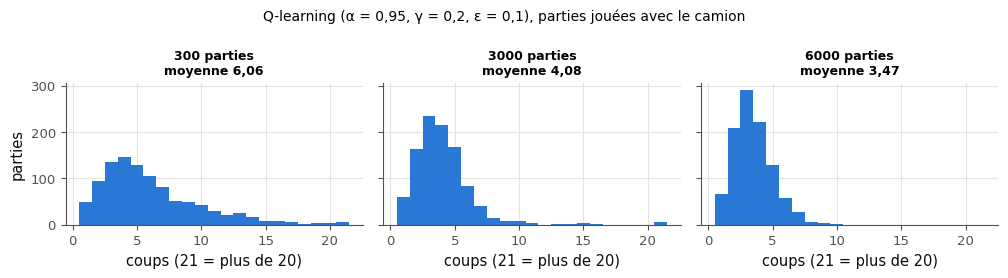

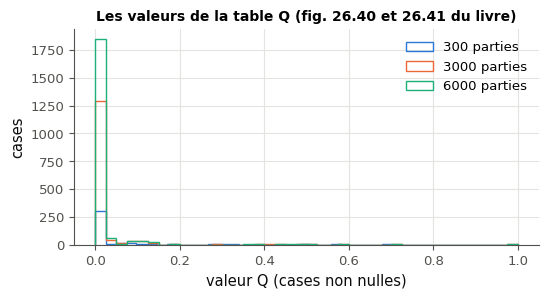

In [53]:
with checked("26.25"):
    REPEATS_25 = 2 if FAST_MODE else 10                   # the book plays each board 10 times
    tables_25 = train_in_stages_25((300, 3000, 6000), seed=2625, alpha=0.95, gamma=0.2, epsilon=0.1)
    results_25 = {}
    for n_25, Q_25 in tables_25.items():
        results_25[f"{n_25} parties"] = evaluate_flippers(Q_25, truck_prob=0.1, repeats=REPEATS_25, seed=25)
        print(f"{n_25:5d} parties : {summary_flippers(results_25[f'{n_25} parties'])} · cases non nulles "
              f"{pct(np.mean(Q_25 != 0))}")
    length_histograms(results_25, "Q-learning (α = 0,95, γ = 0,2, ε = 0,1), parties jouées avec le camion")
    plt.figure(figsize=(6, 2.8))
    for n_25, Q_25 in tables_25.items():
        plt.hist(Q_25[Q_25 != 0], bins=40, histtype="step", label=f"{n_25} parties")
    plt.xlabel("valeur Q (cases non nulles)")
    plt.ylabel("cases")
    plt.legend()
    plt.title("Les valeurs de la table Q (fig. 26.40 et 26.41 du livre)", fontsize=10)
    plt.show()

### Ex 26.26 — Itération sur les valeurs : la référence quand le modèle est connu 🔨 ★★★ ⏱️ 40 min
**Objectif :** écrire l'itération sur les valeurs et s'en servir pour juger une table apprise par le Q-learning.  
**Prérequis :** ∂ 26.8 · Ex 26.22 · fiche §26.6.4 (encadré 🧮) · **Fil rouge :** FrozenLake · **mylearn :** `rl.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/rl.py` (créé par `python tools/start_chapter.py 26`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; `rl.py` importe déjà `argmax_random_tie`, `epsilon_greedy_action` et `incremental_update` de ton `bandit.py` (ch. 11 ; la référence les remplace si tu ne l'as pas écrit). La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch26_rl.py -q` les lance tous dans un terminal.

**Contrat commun de `rl.py`** (les docstrings, plus ces précisions que vérifient les tests) : une entrée invalide lève `ValueError`, jamais `IndexError` ni `TypeError` : $\gamma$ hors de $[0, 1]$, $\alpha$ hors de $]0, 1]$, $\varepsilon$ hors de $[0, 1]$, une température $\le 0$ ou NaN, un NaN dans les récompenses, dans les valeurs ou dans la table, un état ou une action hors de `0 .. n - 1` (−1 compris, jamais ramené au dernier indice), booléen ou non entier (`0.5`) ; les entiers de NumPy sont acceptés. Les listes et les tuples sont acceptés en entrée ; chaque tableau rendu est un **nouveau** tableau `float64` (des entiers pour une politique), et une valeur seule est un `float` Python (`float(...)`), un indice un `int` Python.

Écris `value_iteration(P, gamma=0.99, *, theta=1e-10, max_iter=10_000)`. **Contrat** propre à cette fonction :
- `P` est le modèle au format de Gymnasium (`env.unwrapped.P`) : `P[s][a]` est une liste d'issues `(probabilité, état suivant, récompense, terminated)` ; les états sont `0 .. n_states - 1`, tous avec les mêmes actions ; un `P` vide, des états manquants, des actions inégales, des probabilités dont la somme s'écarte de 1 de plus de $10^{-6}$ ou un état suivant hors limites lèvent `ValueError` ; `P` n'est pas modifié ; les `np.int64` de Gymnasium sont acceptés ;
- $\gamma$ est dans $[0, 1[$ : $\gamma = 1$ est refusé ;
- on part de $V = 0$ et chaque balayage calcule le nouveau $V$ à partir de l'**ancien** (balayages synchrones) : `max_iter=k` rend exactement le $k$-ième itéré ; on s'arrête quand la plus grande variation de $V$ est **strictement** sous `theta` (> 0) ;
- `Q` est calculé à partir du $V$ final (un balayage de plus) ; `greedy_policy(Q)` est une politique optimale.

La première cellule de vérification essaie ta fonction sur une petite chaîne, calcule $V^*$ et la politique optimale du lac glissant, mesure sa réussite, et la compare à la table apprise en 26.22. La seconde lance les tests (`-k "test_value_iteration_"`).

Dans tes notes : pourquoi la politique optimale va-t-elle parfois « contre le mur » ? Le Q-learning de 26.22 a-t-il trouvé la même politique, et ses valeurs sont-elles proches de $Q^*$ partout ? Pourquoi les écarts sont-ils les plus grands dans les états rarement visités ?

In [54]:
# Nothing to write here: value_iteration go in mon_travail/mylearn/rl.py

with checked("26.26"):
    R = mylearn.rl
    P_26 = {0: {0: [(1.0, 1, 0.0, False)], 1: [(1.0, 0, 0.0, False)]},     # a chain 0 -> 1 -> 2 (terminal),
            1: {0: [(1.0, 2, 1.0, True)], 1: [(1.0, 0, 0.0, False)]},      # reward 1 on the last step
            2: {0: [(1.0, 2, 0.0, True)], 1: [(1.0, 2, 0.0, True)]}}
    V_26, Q_26 = R.value_iteration(P_26, gamma=0.5)
    same("26.26", "V* de la chaîne avec γ = 0,5", V_26, [0.5, 1.0, 0.0])
    same("26.26", "Q* de la chaîne", Q_26, [[0.5, 0.25], [1.0, 0.25], [0.0, 0.0]])
    same("26.26", "un seul balayage (max_iter=1) : seule la dernière transition a une valeur",
         R.value_iteration(P_26, gamma=0.5, max_iter=1)[0], [0.0, 1.0, 0.0])
    refuses("26.26", "gamma = 1", lambda: R.value_iteration(P_26, gamma=1.0))
    lake_26 = make_env("FrozenLake-v1", seed=0, is_slippery=True)
    V_lake_26, Q_star_26 = R.value_iteration(lake_26.unwrapped.P, gamma=0.99)
    print("V* du lac glissant (γ = 0,99) :")
    print(np.round(V_lake_26.reshape(4, 4), 3))
    show_lake_policy(R.greedy_policy(Q_star_26), title="la politique optimale :")
    best_26 = R.evaluate_policy(lake_26, R.greedy_policy(Q_star_26), 2000, max_steps=100, rng=np.random.default_rng(26))
    print(f"elle réussit {pct(best_26['mean_return'])} des épisodes (2 000 épisodes de 100 pas au plus)")
    if "lakes_22" in globals() and "glissant" in lakes_22:
        Q_22 = lakes_22["glissant"][0]
        gap_26 = np.abs(Q_22 - Q_star_26).max(axis=1)
        print("le plus grand écart entre ta table de 26.22 et Q*, état par état :")
        print(np.round(gap_26.reshape(4, 4), 2))
        agree_26 = np.mean(R.greedy_policy(Q_22) == R.greedy_policy(Q_star_26))
        print(f"les deux politiques gloutonnes choisissent la même action dans {pct(agree_26)} des états")

✅ Ex 26.26 : V* de la chaîne avec γ = 0,5 : [0.5, 1.0, 0.0], comme attendu.
✅ Ex 26.26 : Q* de la chaîne : [[0.5, 0.25], [1.0, 0.25], [0.0, 0.0]], comme attendu.
✅ Ex 26.26 : un seul balayage (max_iter=1) : seule la dernière transition a une valeur : [0.0, 1.0, 0.0], comme attendu.
✅ Ex 26.26 : gamma = 1 : ValueError levée (gamma must be in [0, 1), got 1.0).
V* du lac glissant (γ = 0,99) :
[[0.542 0.499 0.471 0.457]
 [0.558 0.    0.358 0.   ]
 [0.592 0.643 0.615 0.   ]
 [0.    0.742 0.863 0.   ]]
la politique optimale :
← ↑ ↑ ↑
← H ← H
↑ ↓ ← H
H → ↓ G


elle réussit 73,2 % des épisodes (2 000 épisodes de 100 pas au plus)
le plus grand écart entre ta table de 26.22 et Q*, état par état :
[[0.03 0.1  0.02 0.07]
 [0.1  0.   0.18 0.  ]
 [0.14 0.12 0.09 0.  ]
 [0.   0.11 0.07 0.  ]]
les deux politiques gloutonnes choisissent la même action dans 100,0 % des états


In [55]:
if written(lambda: mylearn.rl.value_iteration({0: {0: [(1.0, 0, 0.0, True)]}}, 0.5)):
    run_pytest_group(TEST_RL, impl="ref", keyword="test_value_iteration_")
else:
    print("⏳ Ex 26.26 : les tests attendent tes fonctions.")

pytest: 27 passed, 181 deselected in 2.45s


### Ex 26.27 — α, γ, ε : balayage d'hyperparamètres sur Flippers bruité 🔬 ★★★ ⏱️ 45 min
**Objectif :** mesurer, sur plusieurs graines, l'effet de $\alpha$ et de $\gamma$ selon le niveau de hasard de l'environnement.  
**Prérequis :** Ex 26.25 · fiche §26.6.1 (encadré ⚠️ sur α), §26.3.7 · **Fil rouge :** Flippers · **Parcours :** C

La fiche le dit : un $\alpha$ proche de 1 remplace presque la valeur à chaque mise à jour, comme le L-learning. Mais à partir de quel niveau de hasard cela coûte-t-il ? Tu balayes $\alpha \in \{0{,}95 ; 0{,}3 ; 0{,}1\}$ avec le $\gamma = 0{,}2$ du livre, pour trois camions de plus en plus fréquents (0,1, 0,5 et 1 : à chaque coup qui ne gagne pas), puis $\gamma = 0{,}9$ avec $\alpha = 0{,}3$. Ici, la récompense est `reward="win"` (1 pour toute victoire) : avec $\gamma < 1$, elle préfère déjà les parties courtes, et elle ne dépend que de l'état atteint (la récompense $1/\sqrt{k}$ dépend aussi du nombre de coups déjà joués, que l'état ne contient pas ; 26.32 y revient).

**Contrat** : `sweep_27(settings, n_games, seeds, epsilon=0.1)` : pour chaque réglage `(alpha, gamma, truck_prob)` et chaque graine, un Q-learning sur `Flippers(truck_prob=truck_prob, reward="win")` pendant `n_games` parties (`mylearn.rl.train_tabular`, `max_steps=100`, `rng=np.random.default_rng(seed)`), puis une partie sur chacun des 506 plateaux avec `evaluate_flippers(Q, truck_prob=truck_prob, seed=seed)` ; elle rend `{réglage: [longueur moyenne, une par graine]}`.

La vérification compare ta fonction à un entraînement fait à la main. La cellule suivante lance les 24 entraînements du mode rapide (3 000 parties, 2 graines ; environ une demi-minute) et trace une barre par réglage, de l'écart entre les graines.

Dans tes notes : à partir de quel camion $\alpha = 0{,}95$ décroche-t-il ? Avec un camion rare, un grand $\alpha$ coûte-t-il quelque chose ici, et pourquoi le hasard de Flippers est-il moins gênant que celui du lac glissant (26.23) ? Le $\gamma = 0{,}9$ fait-il mieux que le $\gamma = 0{,}2$ du livre, et l'écart entre deux graines suffit-il pour conclure ?

In [56]:
SETTINGS_27 = [(alpha, 0.2, truck) for truck in (0.1, 0.5, 1.0) for alpha in (0.95, 0.3, 0.1)] + \
              [(0.3, 0.9, truck) for truck in (0.1, 0.5, 1.0)]     # (alpha, gamma, truck_prob)
N_GAMES_27 = 3000 if FAST_MODE else 6000
SEEDS_27 = (0, 1) if FAST_MODE else (0, 1, 2, 3, 4)

In [57]:
def sweep_27(settings, n_games, seeds, epsilon=0.1):
    """For each setting (alpha, gamma, truck_prob) of `settings` and each seed of `seeds`: train a Q-learning agent
    on Flippers(truck_prob=truck_prob, reward="win") for n_games games (mylearn.rl.train_tabular with alpha, gamma,
    epsilon, max_steps=100, rng=np.random.default_rng(seed)), then play the 506 boards once with
    evaluate_flippers(Q, truck_prob=truck_prob, seed=seed). Returns {setting: [the mean length of the games, one
    value per seed]}."""
    results = {}
    for alpha, gamma, truck in settings:
        lengths = []
        for seed in seeds:
            Q, _ = mylearn.rl.train_tabular(Flippers(truck_prob=truck, reward="win"), n_games, alpha=alpha, gamma=gamma,
                                            epsilon=epsilon, max_steps=100, rng=np.random.default_rng(seed))
            lengths.append(float(evaluate_flippers(Q, truck_prob=truck, seed=seed)["length"].mean()))
        results[(alpha, gamma, truck)] = lengths
    return results


with checked("26.27"):
    tiny_27 = sweep_27([(0.5, 0.9, 0.5)], 20, (7,))
    if returned("26.27", "sweep_27", tiny_27):
        Q_27, _ = mylearn.rl.train_tabular(Flippers(truck_prob=0.5, reward="win"), 20, alpha=0.5, gamma=0.9,
                                           epsilon=0.1, max_steps=100, rng=np.random.default_rng(7))
        same("26.27", "un réglage (camion 0,5), une graine, 20 parties : la longueur moyenne",
             tiny_27.get((0.5, 0.9, 0.5), [None]), [evaluate_flippers(Q_27, truck_prob=0.5, seed=7)["length"].mean()])

✅ Ex 26.27 : un réglage (camion 0,5), une graine, 20 parties : la longueur moyenne : [32.53952569], comme attendu.


24 entraînements en 48 s
    α    γ  camion   longueur moyenne (une valeur par graine)
 0,95  0,2     0,1   3,77  3,98
 0,30  0,2     0,1   3,91  3,88
 0,10  0,2     0,1   3,90  3,95
 0,95  0,2     0,5   5,88  5,36
 0,30  0,2     0,5   5,03  4,62
 0,10  0,2     0,5   5,49  4,72
 0,95  0,2     1,0   14,11  14,07
 0,30  0,2     1,0   9,40  9,59
 0,10  0,2     1,0   8,80  11,54
 0,30  0,9     0,1   4,89  5,07
 0,30  0,9     0,5   6,03  6,48
 0,30  0,9     1,0   13,34  11,34


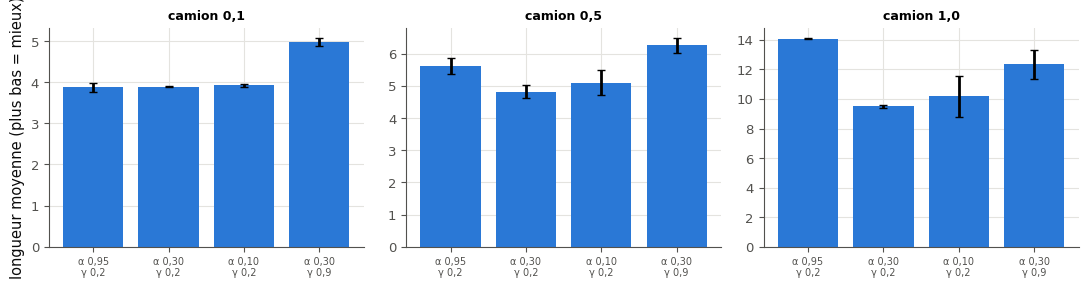

In [58]:
with checked("26.27"):
    start_27 = time.perf_counter()
    sweep_results_27 = sweep_27(SETTINGS_27, N_GAMES_27, SEEDS_27)
    print(f"{len(SETTINGS_27) * len(SEEDS_27)} entraînements en {time.perf_counter() - start_27:.0f} s")
    print(f"{'α':>5s} {'γ':>4s} {'camion':>7s}   longueur moyenne (une valeur par graine)")
    for (alpha_27, gamma_27, truck_27), lengths_27 in sweep_results_27.items():
        print(f"{fr(alpha_27, 2):>5s} {fr(gamma_27, 1):>4s} {fr(truck_27, 1):>7s}   "
              + "  ".join(fr(v, 2) for v in lengths_27))
    fig_27, axes_27 = plt.subplots(1, 3, figsize=(11, 3), sharey=False)
    for ax_27, truck_27 in zip(axes_27, (0.1, 0.5, 1.0)):
        labels_27, means_27, lows_27, highs_27 = [], [], [], []
        for (alpha_27, gamma_27, t_27), lengths_27 in sweep_results_27.items():
            if t_27 == truck_27:
                labels_27.append(f"α {fr(alpha_27, 2)}\nγ {fr(gamma_27, 1)}")
                means_27.append(np.mean(lengths_27))
                lows_27.append(np.mean(lengths_27) - np.min(lengths_27))
                highs_27.append(np.max(lengths_27) - np.mean(lengths_27))
        ax_27.bar(range(len(means_27)), means_27, yerr=[lows_27, highs_27], color=wb.plot.CATEGORICAL[0], capsize=3)
        ax_27.set_xticks(range(len(means_27)), labels_27, fontsize=7)
        ax_27.set_title(f"camion {fr(truck_27, 1)}", fontsize=9)
    axes_27[0].set_ylabel("longueur moyenne (plus bas = mieux)")
    plt.tight_layout()
    plt.show()

## Partie D · SARSA contre le Q-learning

Tu prédis les chemins que les deux algorithmes apprennent au bord d'une falaise (26.28), tu les compares sur plusieurs graines, pendant l'entraînement et après (26.29), puis tu refais les courbes de comparaison du livre (26.30). CliffWalking (l'exemple 6.6 de Sutton et Barto) est une grille de 4 × 12 cases : on part en bas à gauche, l'arrivée est en bas à droite, et les 10 cases entre les deux sont une falaise. Chaque pas coûte −1 ; une chute coûte −100 et renvoie au départ, sans finir l'épisode.

### Ex 26.28 — Prédire le chemin appris par SARSA et par Q-learning au bord de la falaise 🔮 ★ ⏱️ 10 min
**Objectif :** prédire, puis mesurer, ce que l'exploration coûte à chacun des deux algorithmes au bord d'une falaise.  
**Prérequis :** Ex 26.20 · Ex 26.21 · 26.Q11 · fiche §26.7 (encadré ⚠️) · **Parcours :** R, C

La fiche le dit : quand l'exploration coûte cher, SARSA apprend un chemin plus prudent, le Q-learning le chemin optimal, qui longe la falaise. Les deux apprennent ici 500 épisodes avec ta `train_tabular` ($\alpha = 0{,}5$, $\gamma = 1$, $\varepsilon = 0{,}1$ constant, 200 pas au plus). Le chemin optimal fait 13 pas : monter d'une case, 11 pas vers la droite, redescendre. Le nombre de chutes d'un épisode se lit dans l'historique : chaque pas coûte −1 et chaque chute −100 de plus.

**Avant d'exécuter**, écris tes trois prédictions dans la cellule suivante :
a) la longueur du chemin glouton de SARSA, du départ à l'arrivée : `"A"` 13 pas, `"B"` 15, `"C"` 17 ou plus ;
b) sur les 500 épisodes d'entraînement, le Q-learning tombe de la falaise : `"A"` à peu près aussi souvent que SARSA (moins de 1,5 fois plus), `"B"` de 1,5 à 5 fois plus souvent, `"C"` plus de 5 fois plus souvent ;
c) le nombre de chutes du Q-learning en 500 épisodes : `"A"` moins de 50, `"B"` de 50 à 100, `"C"` plus de 100.

La cellule d'expérience n'entraîne rien tant que tes trois prédictions ne sont pas écrites (quelques secondes ensuite).

In [59]:
def cliff_path(Q, max_len=60):
    """The greedy path of a CliffWalking table from the start (state 36): the list of states visited (at most
    max_len steps; a path that loops stops there)."""
    env = make_env("CliffWalking-v1", seed=0)
    state, _ = env.reset(seed=0)
    path = [int(state)]
    for _ in range(max_len):
        state, _, terminated, truncated, _ = env.step(int(np.argmax(Q[state])))
        path.append(int(state))
        if terminated or truncated:
            break
    return path


def show_cliff_paths(paths):
    """Print the 4 x 12 grid of CliffWalking with one path per label: C the cliff, S the start, G the goal."""
    for label, path in paths.items():
        rows = [["·"] * 12 for _ in range(4)]
        for c in range(1, 11):
            rows[3][c] = "C"
        for s in path:
            rows[s // 12][s % 12] = "*"
        rows[3][0], rows[3][11] = "S", "G"
        print(f"{label} ({len(path) - 1} pas) :")
        print("\n".join(" ".join(row) for row in rows))

In [60]:
sarsa_path_28, falls_ratio_28, q_falls_28 = "C", "B", "C"

In [61]:
wb.record("26.28a", "C", mistakes={"c'est le chemin le plus court, celui du Q-learning : compte les pas du chemin de SARSA": "A",
                                   "le chemin de SARSA monte-t-il seulement d'une rangée ?": "B"})
wb.record("26.28b", "B", mistakes={"compare les deux nombres de chutes : le Q-learning tombe-t-il autant que SARSA ?": "A",
                                   "divise les chutes du Q-learning par celles de SARSA : le rapport dépasse-t-il 5 ?": "C"})
wb.record("26.28c", "C", mistakes={"lis le nombre de chutes du Q-learning : est-il sous 50 ?": "A",
                                   "lis le nombre de chutes du Q-learning : est-il sous 100 ?": "B"})

WB_ANSWER {"hash": "3941ae78d0b53ba512e8c225bfd465bae42376253b8ef7e02e77a595776d2cc4", "id": "26.28a", "kind": "str", "mistakes": {"a1380746e102b4ccd609fa0f4f29e6452b60526cae63cf6a01085887825f7020": "c'est le chemin le plus court, celui du Q-learning : compte les pas du chemin de SARSA", "f60ec7ed403ea64d6230bee881e4a094903b258287ee425890bd8dfbf82afa57": "le chemin de SARSA monte-t-il seulement d'une rangée ?"}}
📝 Ex 26.28a : réponse enregistrée (str).
WB_ANSWER {"hash": "372c7750dd7611492fbe533f2f5dbb63ce7843503029a1cedf73f21dc4746127", "id": "26.28b", "kind": "str", "mistakes": {"2f89a9de9c522225f4f4e3211eb12ca9dc43086e4d44318dc111723abea09fc4": "compare les deux nombres de chutes : le Q-learning tombe-t-il autant que SARSA ?", "975ec3d1a872cc8d2fd9e055a2de5ea41a3538cee160527e4d3d485a013bdef4": "divise les chutes du Q-learning par celles de SARSA : le rapport dépasse-t-il 5 ?"}}
📝 Ex 26.28b : réponse enregistrée (str).
WB_ANSWER {"hash": "46d9aa90f36722ba48c77e96a727a63da19fba818bb3a

In [62]:
if any(answer is ... or answer is None for answer in [sarsa_path_28, falls_ratio_28, q_falls_28]):
    print("⏳ Ex 26.28 : écris d'abord tes trois prédictions dans la cellule précédente.")
else:
    ran_28 = False
    with checked("26.28"):
        tables_28, falls_28 = {}, {}
        for algorithm_28 in ("q_learning", "sarsa"):
            cliff_28 = make_env("CliffWalking-v1", seed=0)
            Q_28, history_28 = mylearn.rl.train_tabular(cliff_28, 500, algorithm=algorithm_28, alpha=0.5, gamma=1.0,
                                                        epsilon=0.1, max_steps=200, rng=np.random.default_rng(2628))
            tables_28[algorithm_28] = Q_28
            falls_28[algorithm_28] = -(history_28["returns"] + history_28["lengths"]) / 99    # -100 per fall, -1 per step
            print(f"{algorithm_28:10s} : {falls_28[algorithm_28].sum():.0f} chutes en 500 épisodes, retour moyen des 100 "
                  f"derniers épisodes {fr(history_28['returns'][-100:].mean(), 1)}")
        show_cliff_paths({name_28: cliff_path(Q_28) for name_28, Q_28 in tables_28.items()})
        ran_28 = True
    if ran_28:
        wb.check("26.28a", sarsa_path_28)
        wb.check("26.28b", falls_ratio_28)
        wb.check("26.28c", q_falls_28)
    else:
        print("⏳ Ex 26.28 : tes prédictions se vérifient une fois l'expérience terminée ; elle attend ta train_tabular "
              "(26.21).")

q_learning : 191 chutes en 500 épisodes, retour moyen des 100 derniers épisodes -48,7


sarsa      : 48 chutes en 500 épisodes, retour moyen des 100 derniers épisodes -25,4
q_learning (13 pas) :
· · · · · · · · · · · ·
· · · · · · · · · · · ·
* * * * * * * * * * * *
S C C C C C C C C C C G
sarsa (17 pas) :
· * * * * * * * * * * *
* * · · · · · · · · · *
* · · · · · · · · · · *
S C C C C C C C C C C G
✅ Ex 26.28a : C'est ça !
✅ Ex 26.28b : Parfait !
✅ Ex 26.28c : Bravo !


Dans tes notes : lesquelles de tes prédictions étaient justes ? Pourquoi SARSA s'éloigne-t-il autant du bord, alors qu'un seul pas d'écart suffirait à ne jamais tomber avec la politique gloutonne ? Que deviendrait son chemin si $\varepsilon$ décroissait vers 0 ? Lequel choisirais-tu pour un robot qui apprend dans le monde réel, et pour un agent qu'on entraîne en simulation avant de le déployer sans exploration ?

### Ex 26.29 — Q-learning contre SARSA sur Flippers et CliffWalking 🔬 ★★★ ⏱️ 45 min
**Objectif :** comparer les deux algorithmes sur plusieurs graines, pendant l'entraînement et sans exploration.  
**Prérequis :** Ex 26.28 · Ex 26.25 · fiche §26.7.1, §26.7.2 · **Fil rouge :** Flippers · **Parcours :** C

Le livre conclut que SARSA est meilleur que le Q-learning sur Flippers. La fiche corrige : ils n'apprennent pas la même chose. Tu mesures les deux, sur plusieurs graines, de deux façons : **pendant** l'entraînement (le retour moyen des 100 derniers épisodes, exploration comprise) et **après** (la politique gloutonne, sans exploration).

**Contrat** : `compare_29(make, n_episodes, seeds, score, **train_kwargs)` : pour chaque algorithme (`"q_learning"`, puis `"sarsa"`) et chaque graine, `env = make()`, puis `Q, history = mylearn.rl.train_tabular(env, n_episodes, algorithm=..., rng=np.random.default_rng(seed), **train_kwargs)` ; deux mesures : `"online"`, la moyenne de `history["returns"]` sur les 100 derniers épisodes, et `"greedy"`, `score(env, Q)` (plus grand = mieux). Elle rend `{algorithme: {"online": [une valeur par graine], "greedy": [...]}}`.

La vérification compare ta fonction à un petit essai fait à la main. La cellule suivante compare les deux algorithmes sur CliffWalking (500 épisodes) et sur Flippers avec camion (3 000 parties, les réglages du livre), 3 graines en mode rapide, 5 sinon (une vingtaine de secondes).

Dans tes notes : sur CliffWalking, lequel gagne pendant l'entraînement, et lequel après ? Et sur Flippers, où une erreur d'exploration ne coûte qu'un coup de plus ? L'écart entre les algorithmes dépasse-t-il l'écart entre les graines ? Qu'aurait-il fallu au livre pour conclure ?

In [63]:
def compare_29(make, n_episodes, seeds, score, **train_kwargs):
    """For each algorithm ("q_learning", then "sarsa") and each seed of `seeds`: env = make(), then
    Q, history = mylearn.rl.train_tabular(env, n_episodes, algorithm=algorithm, rng=np.random.default_rng(seed),
    **train_kwargs). Two measures: "online", the mean of history["returns"] over the last 100 episodes (the agent
    still explores), and "greedy", score(env, Q) (the greedy policy, no exploration; larger is better).
    Returns {algorithm: {"online": [one value per seed], "greedy": [one value per seed]}}."""
    results = {}
    for algorithm in ("q_learning", "sarsa"):
        online, greedy = [], []
        for seed in seeds:
            env = make()
            Q, history = mylearn.rl.train_tabular(env, n_episodes, algorithm=algorithm,
                                                  rng=np.random.default_rng(seed), **train_kwargs)
            online.append(float(np.mean(history["returns"][-100:])))
            greedy.append(float(score(env, Q)))
        results[algorithm] = {"online": online, "greedy": greedy}
    return results


with checked("26.29"):
    tiny_29 = compare_29(lambda: make_env("CliffWalking-v1", seed=0), 150, (5,),
                         lambda env, Q: float(Q.sum()), alpha=0.5, gamma=0.9, epsilon=0.3, max_steps=50)
    if returned("26.29", "compare_29", tiny_29):
        R = mylearn.rl
        want_29 = {}
        for algorithm_29 in ("q_learning", "sarsa"):
            Q_29, h_29 = R.train_tabular(make_env("CliffWalking-v1", seed=0), 150, algorithm=algorithm_29,
                                         alpha=0.5, gamma=0.9, epsilon=0.3, max_steps=50, rng=np.random.default_rng(5))
            want_29[algorithm_29] = [h_29["returns"][-100:].mean(), Q_29.sum()]
        for algorithm_29 in ("q_learning", "sarsa"):
            got_29 = tiny_29.get(algorithm_29, {})
            same("26.29", f"{algorithm_29} sur un petit essai : les mesures online et greedy",
                 [got_29.get("online", [None])[0], got_29.get("greedy", [None])[0]], want_29[algorithm_29])

✅ Ex 26.29 : q_learning sur un petit essai : les mesures online et greedy : [-146.8, -1926.99201455], comme attendu.
✅ Ex 26.29 : sarsa sur un petit essai : les mesures online et greedy : [-65.7, -2807.52756185], comme attendu.


In [64]:
def cliff_score_29(env, Q):
    """The return of the greedy policy on CliffWalking (deterministic: one episode, 100 steps at most)."""
    return mylearn.rl.evaluate_policy(env, mylearn.rl.greedy_policy(Q), 1, max_steps=100,
                                      rng=np.random.default_rng(0))["mean_return"]


def flippers_score_29(env, Q):
    """Minus the mean length of the 506 boards played greedily with the truck (larger is better)."""
    return -evaluate_flippers(Q, truck_prob=0.1, seed=29)["length"].mean()


with checked("26.29"):
    SEEDS_29 = (0, 1, 2) if FAST_MODE else (0, 1, 2, 3, 4)
    cliff_29 = compare_29(lambda: make_env("CliffWalking-v1", seed=0), 500, SEEDS_29, cliff_score_29,
                          alpha=0.5, gamma=1.0, epsilon=0.1, max_steps=200)
    flippers_29 = compare_29(lambda: Flippers(truck_prob=0.1), 3000, SEEDS_29, flippers_score_29,
                             alpha=0.95, gamma=0.2, epsilon=0.1, max_steps=100)
    for title_29, results_29, unit_29 in (("CliffWalking (des retours : plus haut = mieux)", cliff_29, 1),
                                          ("Flippers avec camion (pendant l'entraînement, le retour : plus haut = mieux ; "
                                           "politique gloutonne, la longueur : plus bas = mieux)", flippers_29, -1)):
        print(title_29)
        for algorithm_29, measures_29 in results_29.items():
            online_29 = np.array(measures_29["online"])
            greedy_29 = unit_29 * np.array(measures_29["greedy"])
            print(f"  {algorithm_29:10s} pendant l'entraînement : {fr(online_29.mean(), 2)} "
                  f"({' ; '.join(fr(v, 2) for v in online_29)}) · politique gloutonne : {fr(greedy_29.mean(), 2)} "
                  f"({' ; '.join(fr(v, 2) for v in greedy_29)})")

CliffWalking (des retours : plus haut = mieux)
  q_learning pendant l'entraînement : -54,48 (-55,16 ; -44,27 ; -64,00) · politique gloutonne : -13,00 (-13,00 ; -13,00 ; -13,00)
  sarsa      pendant l'entraînement : -25,49 (-22,75 ; -29,98 ; -23,73) · politique gloutonne : -17,00 (-17,00 ; -17,00 ; -17,00)
Flippers avec camion (pendant l'entraînement, le retour : plus haut = mieux ; politique gloutonne, la longueur : plus bas = mieux)
  q_learning pendant l'entraînement : 0,53 (0,55 ; 0,53 ; 0,52) · politique gloutonne : 3,91 (4,01 ; 3,98 ; 3,74)
  sarsa      pendant l'entraînement : 0,51 (0,49 ; 0,52 ; 0,52) · politique gloutonne : 4,38 (4,52 ; 4,30 ; 4,31)


### Ex 26.30 — Reproduire les comparaisons au fil de l'entraînement (fig. 26.58-26.60) 🎨 ★★★ ⏱️ 35 min
**Objectif :** tracer, au fil de l'entraînement, la longueur des parties, la valeur moyenne et la part de cases non nulles des deux algorithmes.  
**Prérequis :** Ex 26.29 · Ex 26.25 · fiche §26.7.2 · **Fil rouge :** Flippers · **Parcours :** C

Le livre compare les deux algorithmes jusqu'à 100 000 parties sur trois courbes : la longueur moyenne d'une partie, la valeur moyenne de la table et la part de ses cases non nulles (fig. 26.58 à 26.60). Tu les refais, avec `train_in_stages_25` (26.25), qui accepte `algorithm="sarsa"`.

**Contrat**
- `measure_30(tables, truck_prob=0.1)` : pour un dictionnaire `{nombre de parties: Q}`, dans l'ordre de ses clés, la longueur moyenne de `evaluate_flippers(Q, truck_prob=truck_prob, seed=30)`, la moyenne de **toutes** les cases de `Q` et la part des cases non nulles ; elle rend `{"games": [...], "length": [...], "mean_q": [...], "nonzero": [...]}` ;
- `plot_comparison_30(curves)` : trois panneaux côte à côte (longueur, valeur moyenne, cases non nulles) en fonction du nombre de parties, en échelle logarithmique, une ligne avec des points par entrée de `curves` (un nom → un résultat de `measure_30`), une légende ; elle finit par `plt.show()`.

La vérification essaie `measure_30` sur deux tables connues. La cellule suivante entraîne les deux algorithmes jusqu'à 6 000 parties en mode rapide (100 000 en mode complet : une dizaine de minutes) et trace les trois comparaisons.

Dans tes notes : retrouves-tu les trois écarts du livre (des parties un peu plus courtes, des valeurs plus basses, moins de cases non nulles pour SARSA) ? Pourquoi la valeur moyenne de SARSA est-elle plus basse (pense à sa cible) ? Une seule graine suffit-elle pour l'affirmer (26.29) ?

In [65]:
def measure_30(tables, truck_prob=0.1):
    """For a dict {number of games: Q} (as train_in_stages_25 returns), in the order of the keys: "length", the mean
    length of evaluate_flippers(Q, truck_prob=truck_prob, seed=30); "mean_q", the mean of all the cells of Q;
    "nonzero", the share of cells of Q different from 0. Returns {"games": [...], "length": [...], "mean_q": [...],
    "nonzero": [...]}."""
    curves = {"games": [], "length": [], "mean_q": [], "nonzero": []}
    for n, Q in tables.items():
        curves["games"].append(n)
        curves["length"].append(float(evaluate_flippers(Q, truck_prob=truck_prob, seed=30)["length"].mean()))
        curves["mean_q"].append(float(Q.mean()))
        curves["nonzero"].append(float(np.mean(Q != 0)))
    return curves


def plot_comparison_30(curves):
    """Three panels side by side (the figures 26.58 to 26.60 of the book): the mean length, the mean Q value and the
    share of nonzero cells, against the number of training games (log scale), one line with markers per entry of
    `curves` (a label -> a measure_30 result), with a legend. Ends with plt.show()."""
    fig, axes = plt.subplots(1, 3, figsize=(11, 3))
    for key, ax, ylabel in (("length", axes[0], "longueur moyenne"), ("mean_q", axes[1], "valeur Q moyenne"),
                            ("nonzero", axes[2], "part de cases non nulles")):
        for label, curve in curves.items():
            ax.plot(curve["games"], curve[key], "o-", label=label)
        ax.set_xscale("log")
        ax.set_xlabel("parties d'entraînement")
        ax.set_ylabel(ylabel)
    axes[0].legend()
    plt.tight_layout()
    plt.show()


with checked("26.30"):
    fake_30 = {10: np.zeros((512, 9)), 20: np.eye(512, 9)}
    measured_30 = measure_30(fake_30)
    if returned("26.30", "measure_30", measured_30):
        same("26.30", "deux tables : la valeur moyenne et la part de cases non nulles",
             [measured_30["mean_q"], measured_30["nonzero"]], [[0.0, 9 / (512 * 9)], [0.0, 9 / (512 * 9)]])
        same("26.30", "les longueurs moyennes", measured_30["length"],
             [evaluate_flippers(Q, truck_prob=0.1, seed=30)["length"].mean() for Q in fake_30.values()])

✅ Ex 26.30 : deux tables : la valeur moyenne et la part de cases non nulles : [[0.0, 0.00195312], [0.0, 0.00195312]], comme attendu.


✅ Ex 26.30 : les longueurs moyennes : [60.00395257, 58.0256917], comme attendu.


entraînements et mesures en 5 s


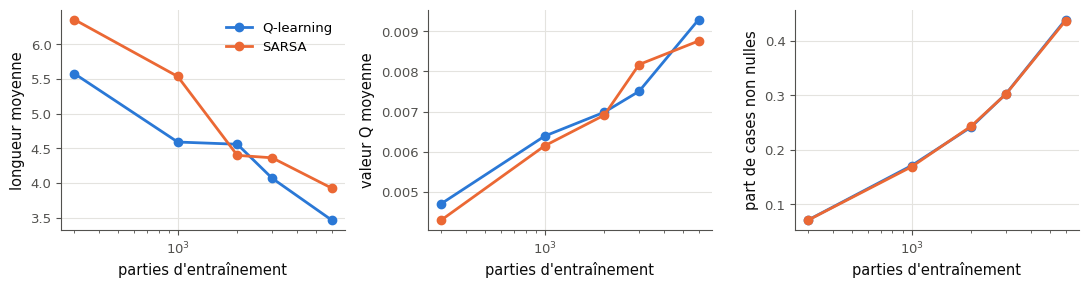

In [66]:
with checked("26.30"):
    CHECKPOINTS_30 = (300, 1000, 2000, 3000, 6000) if FAST_MODE else (300, 1000, 3000, 6000, 10_000, 30_000, 100_000)
    start_30 = time.perf_counter()
    curves_30 = {}
    for algorithm_30, label_30 in (("q_learning", "Q-learning"), ("sarsa", "SARSA")):
        tables_30 = train_in_stages_25(CHECKPOINTS_30, seed=2630, algorithm=algorithm_30, alpha=0.95, gamma=0.2,
                                       epsilon=0.1)
        curves_30[label_30] = measure_30(tables_30)
    print(f"entraînements et mesures en {time.perf_counter() - start_30:.0f} s")
    plot_comparison_30(curves_30)

## Partie E · Le rejeu d'expérience, la conception des récompenses, un résultat honnête

Tu écris une mémoire de rejeu (26.31), tu compares plusieurs récompenses pour un même jeu, dont une qu'un agent détourne (26.32), tu rejoues l'expérience pour apprendre avec moins d'épisodes (26.33), puis tu rapportes un résultat de RL comme il faut : plusieurs graines, un intervalle, la configuration enregistrée (26.34).

### Ex 26.31 — Une mémoire de rejeu 🔨 ★★★ ⏱️ 40 min
**Objectif :** écrire une mémoire de rejeu de capacité fixe et le tirage de mini-batches dans ta librairie.  
**Prérequis :** 0A (tableaux NumPy) · fiche §26.9 (encadré 🕰️) · **mylearn :** `rl.py` · **Parcours :** R, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/rl.py` (créé par `python tools/start_chapter.py 26`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; `rl.py` importe déjà `argmax_random_tie`, `epsilon_greedy_action` et `incremental_update` de ton `bandit.py` (ch. 11 ; la référence les remplace si tu ne l'as pas écrit). La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch26_rl.py -q` les lance tous dans un terminal.

**Contrat commun de `rl.py`** (les docstrings, plus ces précisions que vérifient les tests) : une entrée invalide lève `ValueError`, jamais `IndexError` ni `TypeError` : $\gamma$ hors de $[0, 1]$, $\alpha$ hors de $]0, 1]$, $\varepsilon$ hors de $[0, 1]$, une température $\le 0$ ou NaN, un NaN dans les récompenses, dans les valeurs ou dans la table, un état ou une action hors de `0 .. n - 1` (−1 compris, jamais ramené au dernier indice), booléen ou non entier (`0.5`) ; les entiers de NumPy sont acceptés. Les listes et les tuples sont acceptés en entrée ; chaque tableau rendu est un **nouveau** tableau `float64` (des entiers pour une politique), et une valeur seule est un `float` Python (`float(...)`), un indice un `int` Python.

Écris les méthodes `push`, `sample` et `__len__` de la classe `ReplayBuffer`, la mémoire de rejeu (*replay buffer*) de ta librairie (son `__init__` est déjà écrit : lis sa docstring, qui décrit le stockage). **Contrat** propre à cette classe :
- `push(state, action, reward, next_state, terminated)` écrit à la position `self._pos`, puis avance cette position modulo la capacité (la plus ancienne transition est écrasée quand la mémoire est pleine) ; un état ou un état suivant dont la forme n'est pas `obs_shape` lève `ValueError` (pas de diffusion) ;
- `sample(batch_size)` tire **sans remise**, uniformément, `batch_size` transitions parmi celles qui sont stockées (après un retour au début aussi), avec `self._rng` : la même `random_state` donne les mêmes mini-batches ; il rend exactement les cinq clés `"states"`, `"actions"`, `"rewards"`, `"next_states"`, `"terminated"`, la ligne $i$ de chaque tableau venant de la même transition, et des **copies** ; un `batch_size` nul, plus grand que `len(buffer)` ou booléen lève `ValueError` ;
- `len(buffer)` est le nombre de transitions stockées, au plus la capacité.

La première cellule de vérification remplit une mémoire de 3 avec 5 transitions, vérifie ce qui reste, les copies, puis des états de CartPole (4 nombres `float32`). La seconde lance les tests (`-k "test_replay_buffer_"`).

Dans tes notes : pourquoi tirer **sans remise** dans un mini-batch ? Pourquoi `sample` doit-il rendre des copies, et quel bug une vue créerait-elle ?

In [67]:
# Nothing to write here: the methods push, sample and __len__ of ReplayBuffer go in mon_travail/mylearn/rl.py

with checked("26.31"):
    R = mylearn.rl
    buffer_31 = R.ReplayBuffer(capacity=3, random_state=0)
    for i_31 in range(5):                      # 5 transitions in a memory of 3: the first two are overwritten
        buffer_31.push(i_31, i_31 % 2, float(i_31), i_31 + 1, i_31 == 4)
    same("26.31", "len après 5 transitions dans une mémoire de 3", len(buffer_31), 3)
    batch_31 = buffer_31.sample(3)
    if returned("26.31", "sample", batch_31):
        verdict("26.31", sorted(batch_31) == ["actions", "next_states", "rewards", "states", "terminated"],
                "le mini-batch a ses cinq clés.", f"attendu les clés actions, next_states, rewards, states, terminated, "
                f"reçu {sorted(batch_31)}.")
        order_31 = np.argsort(batch_31["states"])
        same("26.31", "les trois transitions gardées, triées par état : états", batch_31["states"][order_31], [2, 3, 4])
        same("26.31", "… états suivants (chaque ligne reste une même transition)", batch_31["next_states"][order_31],
             [3, 4, 5])
        same("26.31", "… récompenses", batch_31["rewards"][order_31], [2.0, 3.0, 4.0])
        same("26.31", "… fins", batch_31["terminated"][order_31], [False, False, True])
        batch_31["states"][:] = -1
        same("26.31", "le mini-batch est une copie : le modifier ne touche pas la mémoire",
             np.sort(buffer_31.sample(3)["states"]), [2, 3, 4])
        refuses("26.31", "un mini-batch plus grand que la mémoire", lambda: buffer_31.sample(4))
        cart_31 = R.ReplayBuffer(10, obs_shape=(4,), obs_dtype="float32", random_state=1)
        for i_31 in range(4):
            cart_31.push(np.full(4, i_31, dtype=np.float32), 1, 1.0, np.full(4, i_31 + 1, dtype=np.float32), False)
        states_31 = cart_31.sample(2)["states"]
        verdict("26.31", states_31.shape == (2, 4) and states_31.dtype == np.float32,
                "des états de CartPole : un mini-batch (2, 4) en float32.",
                f"des états de CartPole : attendu (2, 4) float32, reçu {states_31.shape} {states_31.dtype}.")

✅ Ex 26.31 : len après 5 transitions dans une mémoire de 3 : 3.0, comme attendu.
✅ Ex 26.31 : le mini-batch a ses cinq clés.
✅ Ex 26.31 : les trois transitions gardées, triées par état : états : [2.0, 3.0, 4.0], comme attendu.
✅ Ex 26.31 : … états suivants (chaque ligne reste une même transition) : [3.0, 4.0, 5.0], comme attendu.
✅ Ex 26.31 : … récompenses : [2.0, 3.0, 4.0], comme attendu.
✅ Ex 26.31 : … fins : [0.0, 0.0, 1.0], comme attendu.
✅ Ex 26.31 : le mini-batch est une copie : le modifier ne touche pas la mémoire : [2.0, 3.0, 4.0], comme attendu.
✅ Ex 26.31 : un mini-batch plus grand que la mémoire : ValueError levée (batch_size must be <= len(self) = 3, got 4).
✅ Ex 26.31 : des états de CartPole : un mini-batch (2, 4) en float32.


In [68]:
if written(lambda: len(mylearn.rl.ReplayBuffer(2))):
    run_pytest_group(TEST_RL, impl="ref", keyword="test_replay_buffer_")
else:
    print("⏳ Ex 26.31 : les tests attendent tes fonctions.")

pytest: 17 passed, 191 deselected in 2.31s


### Ex 26.32 — Concevoir la récompense : finale, pénalité par coup ou façonnée 🔬 ★★ ⏱️ 30 min
**Objectif :** comparer plusieurs récompenses pour un même jeu, et voir un agent détourner une récompense mal conçue.  
**Prérequis :** Ex 26.25 · ⚖️ 26.11 · fiche §26.3.7, §26.5, « Au-delà du livre » · **Fil rouge :** Flippers · **Parcours :** C

Une même tâche, gagner Flippers vite, peut se récompenser de plusieurs façons. `Flippers` en propose quatre : la récompense finale du livre, $1/\sqrt{k}$ (`reward="final"`) ; 1 pour toute victoire (`"win"`) ; la même avec un coût de 0,05 par coup (`step_penalty=0.05`) ; une récompense **façonnée** (`"shaped"`) qui ajoute à chaque pas $0{,}1 \times (d(s) - d(s'))$, où $d$ est le nombre minimal de coups de 26.17 : un bonus pour chaque coup qui rapproche de la victoire. Tu en écris une cinquième : 0,2 de plus à chaque coup qui **ajoute** un point, l'idée naïve « il faut des points pour gagner ».

**Contrat**
- `DotBonus_32(env, bonus=0.2)`, un `gym.Wrapper` : `reset` mémorise le nombre de points du plateau ; `step` rend la récompense du jeu, plus `bonus` si le plateau compte un point de plus qu'avant le coup (rien quand un point disparaît) ; l'état, `terminated`, `truncated` et `info` sont ceux du jeu ;
- `train_eval_32(make, n_games, seed)` entraîne un Q-learning sur `make()` (`mylearn.rl.train_tabular`, $\alpha = 0{,}5$, $\gamma = 0{,}9$, $\varepsilon = 0{,}1$, `max_steps=100`, `rng=np.random.default_rng(seed)`), puis fait jouer les 506 plateaux au jeu **ordinaire** (`evaluate_flippers(Q, truck_prob=0.0, seed=seed)`) ; elle rend `(part des parties gagnées, longueur moyenne)`.

La vérification essaie ton wrapper sur quatre coups connus, puis ta fonction contre un entraînement fait à la main. La cellule suivante compare les cinq récompenses (3 000 parties, 2 graines en mode rapide ; environ une demi-minute).

Dans tes notes : quelle récompense apprend le plus vite à jouer court, et pourquoi la récompense façonnée aide-t-elle (que contient-elle que l'agent devrait sinon découvrir) ? Qu'a appris l'agent payé pour les points, et pourquoi est-ce, pour lui, la bonne stratégie (⚖️ 26.11) ? La récompense $1/\sqrt{k}$ dépend du nombre de coups déjà joués, que l'état ne contient pas : qu'est-ce que cela change pour une table Q ?

In [69]:
DOT_BONUS_32 = 0.2

In [70]:
class DotBonus_32(gym.Wrapper):
    """Flippers with a reward that also pays for dots: at each step, the reward of the wrapped game, plus `bonus`
    if the move ADDED a dot (one more dot on the board after the step than before it; nothing when a dot is
    removed). The state, terminated, truncated and info are those of the wrapped game."""

    def __init__(self, env, bonus=DOT_BONUS_32):
        super().__init__(env)
        self.bonus = bonus

    def reset(self, **kwargs):
        state, info = self.env.reset(**kwargs)
        self._dots = bin(int(state)).count("1")
        return state, info

    def step(self, action):
        state, reward, terminated, truncated, info = self.env.step(action)
        dots = bin(int(state)).count("1")
        if dots > self._dots:
            reward += self.bonus
        self._dots = dots
        return state, reward, terminated, truncated, info


def train_eval_32(make, n_games, seed):
    """Train a Q-learning agent on make() for n_games games (mylearn.rl.train_tabular, alpha=0.5, gamma=0.9,
    epsilon=0.1, max_steps=100, rng=np.random.default_rng(seed)), then play the 506 boards with the PLAIN game
    (evaluate_flippers(Q, truck_prob=0.0, seed=seed)). Returns (share of games won, mean length)."""
    Q, _ = mylearn.rl.train_tabular(make(), n_games, alpha=0.5, gamma=0.9, epsilon=0.1, max_steps=100,
                                    rng=np.random.default_rng(seed))
    result = evaluate_flippers(Q, truck_prob=0.0, seed=seed)
    return float(result["won"].mean()), float(result["length"].mean())


with checked("26.32"):
    game_32 = DotBonus_32(Flippers(reward="win"), bonus=0.2)
    start_32 = Flippers().encode([[1, 1, 0], [0, 0, 0], [0, 0, 1]])
    state_32, _ = game_32.reset(options={"state": start_32})
    rewards_32 = [game_32.step(a)[1] for a in (4, 4, 8)]          # add a dot, remove it, remove another one
    same("26.32", "les récompenses de trois coups : + un point, − un point, − un point", rewards_32, [0.2, 0.0, 0.0])
    last_32 = game_32.step(2)                                       # the top row: a win, and one more dot
    same("26.32", "le coup gagnant ajoute un point : victoire (1) + bonus", last_32[1], 1.2)
    verdict("26.32", bool(last_32[2]), "le coup gagnant termine la partie.",
            "le coup gagnant doit garder le terminated du jeu.")
    pair_32 = train_eval_32(lambda: Flippers(reward="win"), 20, 3)
    if returned("26.32", "train_eval_32", pair_32):
        Q_32, _ = mylearn.rl.train_tabular(Flippers(reward="win"), 20, alpha=0.5, gamma=0.9, epsilon=0.1, max_steps=100,
                                           rng=np.random.default_rng(3))
        r_32 = evaluate_flippers(Q_32, truck_prob=0.0, seed=3)
        same("26.32", "train_eval_32 sur 20 parties : (part gagnée, longueur moyenne)", list(pair_32),
             [r_32["won"].mean(), r_32["length"].mean()])

✅ Ex 26.32 : les récompenses de trois coups : + un point, − un point, − un point : [0.2, 0.0, 0.0], comme attendu.
✅ Ex 26.32 : le coup gagnant ajoute un point : victoire (1) + bonus : 1.2, comme attendu.
✅ Ex 26.32 : le coup gagnant termine la partie.


✅ Ex 26.32 : train_eval_32 sur 20 parties : (part gagnée, longueur moyenne) : [0.96640316, 30.83992095], comme attendu.


In [71]:
with checked("26.32"):
    N_32 = 3000 if FAST_MODE else 10_000
    SEEDS_32 = (0, 1) if FAST_MODE else (0, 1, 2, 3, 4)
    DESIGNS_32 = {
        "finale 1/√k": lambda: Flippers(reward="final"),
        "victoire 1": lambda: Flippers(reward="win"),
        "victoire 1, −0,05 par coup": lambda: Flippers(reward="win", step_penalty=0.05),
        "façonnée (+0,1 par coup qui rapproche)": lambda: Flippers(reward="shaped"),
        "victoire 1, +0,2 par point ajouté": lambda: DotBonus_32(Flippers(reward="win")),
    }
    start_32 = time.perf_counter()
    print(f"{'récompense':42s} {'gagnées':>9s} {'longueur moyenne':>17s}   ({N_32} parties, graines {SEEDS_32})")
    for name_32, make_32 in DESIGNS_32.items():
        runs_32 = [train_eval_32(make_32, N_32, seed) for seed in SEEDS_32]
        print(f"{name_32:42s} {pct(np.mean([w for w, _ in runs_32])):>9s} "
              f"{fr(np.mean([n for _, n in runs_32]), 2):>17s}")
    print(f"({time.perf_counter() - start_32:.0f} s ; l'optimum est de {fr(np.mean([Flippers().min_moves(s) for s in range(512) if s not in Flippers().winning]), 2)} coups)")

récompense                                   gagnées  longueur moyenne   (3000 parties, graines (0, 1))


finale 1/√k                                   87,3 %             17,05


victoire 1                                   100,0 %              4,60


victoire 1, −0,05 par coup                   100,0 %              3,71


façonnée (+0,1 par coup qui rapproche)       100,0 %              3,48


victoire 1, +0,2 par point ajouté              4,5 %             95,54
(43 s ; l'optimum est de 2,70 coups)


### Ex 26.33 — Rejouer l'expérience pour apprendre avec moins d'épisodes 🔬 ★★★ ⏱️ 35 min
**Objectif :** ajouter une mémoire de rejeu au Q-learning tabulaire et mesurer ce qu'elle apporte à nombre d'épisodes égal.  
**Prérequis :** Ex 26.31 · Ex 26.22 · fiche §26.9 · **Fil rouge :** FrozenLake · **Parcours :** C

Avec une mémoire de rejeu, chaque transition vécue sert plusieurs fois : après chaque vrai pas, on refait quelques mises à jour sur des transitions tirées au hasard dans la mémoire. C'est l'idée de DQN (fiche §26.9), sans réseau.

**Contrat** : `train_with_replay_33(env, n_episodes, replay_updates, *, alpha=0.1, gamma=0.99, epsilon=0.1, capacity=10_000, max_steps=100, seed=0)` : `rng = np.random.default_rng(seed)`, une mémoire `mylearn.rl.ReplayBuffer(capacity, random_state=seed)`, une table nulle. Pour chaque épisode : `epsilon` (une constante ou une fonction de l'épisode), `env.reset(seed=int(rng.integers(2**31)))` ; à chaque pas : l'action `mylearn.bandit.epsilon_greedy_action(Q[state], eps, rng)`, `env.step`, **une** `mylearn.rl.q_learning_update` sur cette transition, `push` dans la mémoire, puis, si `replay_updates > 0` et que la mémoire contient au moins `replay_updates` transitions, un mini-batch `sample(replay_updates)` et une mise à jour par transition du mini-batch ; arrêt à `terminated`, `truncated` ou `max_steps` pas. Elle rend `(Q, returns)`.

Sans rejeu, ta fonction doit refaire **exactement** ta `train_tabular` : la vérification le contrôle, s'assure que le rejeu change la table, puis compte tes appels à `mylearn.rl.q_learning_update` (appelle-la par `mylearn.rl`, pas par un `import` qui en garderait une copie). La cellule suivante entraîne 500 épisodes sur le lac glissant, sans rejeu et avec 8 mises à jour rejouées par pas, sur 3 graines en mode rapide (une dizaine de secondes).

Dans tes notes : combien de mises à jour chaque version fait-elle en tout, et le gain vient-il seulement de ce nombre (que donnerait 9 fois plus d'épisodes sans rejeu) ? Pourquoi le rejeu suppose-t-il une méthode **off-policy** (*hors politique*) comme le Q-learning ? Qu'est-ce que la mémoire de rejeu de DQN apporte en plus, qu'une table n'a pas besoin (fiche, 💼 26.E4) ?

In [72]:
def train_with_replay_33(env, n_episodes, replay_updates, *, alpha=0.1, gamma=0.99, epsilon=0.1,
                         capacity=10_000, max_steps=100, seed=0):
    """Q-learning with experience replay. rng = np.random.default_rng(seed), buffer =
    mylearn.rl.ReplayBuffer(capacity, random_state=seed), Q = zeros. For each episode: epsilon (a constant or a
    function of the episode index), env.reset(seed=int(rng.integers(2**31))); at each step:
    action = mylearn.bandit.epsilon_greedy_action(Q[state], eps, rng), env.step, ONE mylearn.rl.q_learning_update
    on this transition, buffer.push(...), then, if replay_updates > 0 and len(buffer) >= replay_updates, a
    mini-batch buffer.sample(replay_updates) and one q_learning_update per transition of the batch; stop at
    terminated, truncated or max_steps steps. Returns (Q, returns): the table and the total reward of each
    episode (an array)."""
    R = mylearn.rl
    rng = np.random.default_rng(seed)
    buffer = R.ReplayBuffer(capacity, random_state=seed)
    Q = np.zeros((env.observation_space.n, env.action_space.n))
    returns = []
    for episode in range(n_episodes):
        eps = epsilon(episode) if callable(epsilon) else epsilon
        state, _ = env.reset(seed=int(rng.integers(2**31)))
        total = 0.0
        for _ in range(max_steps):
            action = mylearn.bandit.epsilon_greedy_action(Q[state], eps, rng)
            next_state, reward, terminated, truncated, _ = env.step(action)
            total += reward
            R.q_learning_update(Q, state, action, reward, next_state, terminated, alpha, gamma)
            buffer.push(state, action, reward, next_state, terminated)
            if replay_updates > 0 and len(buffer) >= replay_updates:
                batch = buffer.sample(replay_updates)
                for i in range(replay_updates):
                    R.q_learning_update(Q, int(batch["states"][i]), int(batch["actions"][i]), float(batch["rewards"][i]),
                                        int(batch["next_states"][i]), bool(batch["terminated"][i]), alpha, gamma)
            state = next_state
            if terminated or truncated:
                break
        returns.append(total)
    return Q, np.array(returns)


with checked("26.33"):
    lake_33 = make_env("FrozenLake-v1", seed=0, is_slippery=True)
    result_33 = train_with_replay_33(lake_33, 40, 0, alpha=0.5, gamma=0.9, epsilon=0.3, seed=33)
    if returned("26.33", "train_with_replay_33", result_33):
        Q_ref_33, h_33 = mylearn.rl.train_tabular(lake_33, 40, alpha=0.5, gamma=0.9, epsilon=0.3, max_steps=100,
                                                  rng=np.random.default_rng(33))
        same("26.33", "sans rejeu (replay_updates=0), la même table que train_tabular", result_33[0], Q_ref_33)
        same("26.33", "… et les mêmes retours", result_33[1], h_33["returns"])
        Q_replay_33, _ = train_with_replay_33(lake_33, 40, 4, alpha=0.5, gamma=0.9, epsilon=0.3, seed=33)
        verdict("26.33", not np.allclose(Q_replay_33, Q_ref_33), "avec rejeu, la table change bien.",
                "avec replay_updates=4, la table est la même que sans rejeu : les transitions rejouées ne mettent "
                "rien à jour.")
        calls_33, original_33 = [], mylearn.rl.q_learning_update

        def counting_33(*args, **kwargs):
            calls_33.append(1)
            return original_33(*args, **kwargs)

        spy_33 = GameRecorder(make_env("FrozenLake-v1", seed=0, is_slippery=True))
        mylearn.rl.q_learning_update = counting_33               # counts the updates of train_with_replay_33
        try:
            train_with_replay_33(spy_33, 5, 3, alpha=0.5, gamma=0.9, epsilon=0.3, seed=34)
        finally:
            mylearn.rl.q_learning_update = original_33
        steps_33 = sum(len(game) for game in spy_33.games)
        same("26.33", f"le nombre d'appels à mylearn.rl.q_learning_update en {steps_33} pas avec replay_updates=3 : un "
             "par pas vécu, plus 3 par pas dès que la mémoire contient 3 transitions", len(calls_33),
             steps_33 + 3 * max(0, steps_33 - 2))

✅ Ex 26.33 : sans rejeu (replay_updates=0), la même table que train_tabular : un tableau (16, 4), comme attendu.
✅ Ex 26.33 : … et les mêmes retours : un tableau (40,), comme attendu.
✅ Ex 26.33 : avec rejeu, la table change bien.
✅ Ex 26.33 : le nombre d'appels à mylearn.rl.q_learning_update en 38 pas avec replay_updates=3 : un par pas vécu, plus 3 par pas dès que la mémoire contient 3 transitions : 146.0, comme attendu.


In [73]:
with checked("26.33"):
    SEEDS_33 = (0, 1, 2) if FAST_MODE else tuple(range(10))
    N_33 = 500
    schedule_33 = lambda i: max(0.05, 1.0 - 0.95 * i / (0.8 * N_33))      # as epsilon_schedule_22(500)
    lake_33 = make_env("FrozenLake-v1", seed=0, is_slippery=True)
    start_33 = time.perf_counter()
    for k_33 in (0, 8):
        scores_33 = []
        for seed_33 in SEEDS_33:
            Q_33, _ = train_with_replay_33(lake_33, N_33, k_33, epsilon=schedule_33, seed=seed_33)
            scores_33.append(mylearn.rl.evaluate_policy(lake_33, mylearn.rl.greedy_policy(Q_33), 300, max_steps=100,
                                                        rng=np.random.default_rng(1))["mean_return"])
        print(f"{k_33} mises à jour rejouées par pas : réussite de la politique gloutonne "
              + " ; ".join(pct(s) for s in scores_33) + f" (moyenne {pct(np.mean(scores_33))})")
    print(f"({time.perf_counter() - start_33:.0f} s ; la politique optimale réussit environ 73 % du temps, 26.26)")

0 mises à jour rejouées par pas : réussite de la politique gloutonne 47,3 % ; 3,7 % ; 24,7 % (moyenne 25,2 %)


8 mises à jour rejouées par pas : réussite de la politique gloutonne 68,0 % ; 50,0 % ; 69,7 % (moyenne 62,6 %)
(12 s ; la politique optimale réussit environ 73 % du temps, 26.26)


### Ex 26.34 — Rapporter un résultat RL honnête : plusieurs graines, configuration, intervalle 🛠️ ★★ ⏱️ 25 min
**Objectif :** rapporter un résultat stochastique sur plusieurs graines, avec un intervalle et la configuration enregistrée en JSON.  
**Prérequis :** Ex 26.22 · ch. 2 (bootstrap, `mylearn.stats.bootstrap_ci`) · fiche « Au-delà du livre » · **Fil rouge :** FrozenLake · **Parcours :** R, C

En RL, deux entraînements qui ne diffèrent que par la graine peuvent donner des résultats très différents. Un résultat sérieux se donne sur plusieurs graines, avec un intervalle, et avec **toute** la configuration, pour qu'un autre puisse le refaire. `CONFIG_34` décrit l'expérience de 26.22 sur le lac glissant, avec 1 000 épisodes au lieu de 4 000.

**Contrat**
- `run_34(config, seed)` : le lac `make_env(config["env"], seed=0, is_slippery=config["is_slippery"])`, un entraînement `mylearn.rl.train_tabular` avec les réglages de `config` (l'$\varepsilon$ de `epsilon_schedule_22(n_episodes, epsilon_start, epsilon_end, epsilon_fraction)`) et `rng=np.random.default_rng(seed)`, puis la réussite de la politique gloutonne, `evaluate_policy(..., config["eval_episodes"], max_steps=config["max_steps"], rng=np.random.default_rng(config["eval_seed"]))` : les **mêmes** graines d'évaluation pour toutes les graines d'entraînement ; elle rend cette moyenne en `float` ;
- `report_34(config, seeds, path)` lance `run_34` pour chaque graine, écrit dans `path` (JSON, `indent=2`) et rend `{"config", "seeds", "results", "mean", "ci95"}`, où `ci95` est `mylearn.stats.bootstrap_ci(results, confidence=0.95, n_boot=2000, rng=np.random.default_rng(0))` (ch. 2), en liste de deux `float`.

La vérification compare `run_34` à un calcul fait à la main sur un petit réglage, relit ton fichier JSON et refait l'intervalle. La cellule suivante lance 5 graines (10 en mode complet ; une dizaine de secondes) et dessine chaque graine, la moyenne et l'intervalle.

Dans tes notes : si tu n'avais publié qu'une graine, entre quelles valeurs ton résultat aurait-il pu tomber ? Que vaut un intervalle bootstrap avec 5 valeurs seulement (ch. 2) ? Pourquoi les graines d'évaluation doivent-elles être les mêmes pour toutes les méthodes comparées ? Que manque-t-il encore au fichier pour refaire l'expérience dans un an (les versions des bibliothèques, le commit du code) ?

In [74]:
CONFIG_34 = {"env": "FrozenLake-v1", "is_slippery": True, "algorithm": "q_learning", "n_episodes": 1000,
             "alpha": 0.1, "gamma": 0.99, "epsilon_start": 1.0, "epsilon_end": 0.05, "epsilon_fraction": 0.8,
             "max_steps": 100, "eval_episodes": 500, "eval_seed": 34}

In [75]:
def run_34(config, seed):
    """One run: make_env(config["env"], seed=0, is_slippery=config["is_slippery"]), mylearn.rl.train_tabular with
    the algorithm, n_episodes, alpha, gamma, max_steps of config, the epsilon of epsilon_schedule_22(n_episodes,
    epsilon_start, epsilon_end, epsilon_fraction) and rng=np.random.default_rng(seed); then the success of the
    greedy policy: mylearn.rl.evaluate_policy(env, greedy policy, config["eval_episodes"], max_steps=...,
    rng=np.random.default_rng(config["eval_seed"])) -- the SAME evaluation seeds for every run. Returns this
    mean return as a float."""
    R = mylearn.rl
    env = make_env(config["env"], seed=0, is_slippery=config["is_slippery"])
    schedule = epsilon_schedule_22(config["n_episodes"], config["epsilon_start"], config["epsilon_end"],
                                   config["epsilon_fraction"])
    Q, _ = R.train_tabular(env, config["n_episodes"], algorithm=config["algorithm"], alpha=config["alpha"],
                           gamma=config["gamma"], epsilon=schedule, max_steps=config["max_steps"],
                           rng=np.random.default_rng(seed))
    score = R.evaluate_policy(env, R.greedy_policy(Q), config["eval_episodes"], max_steps=config["max_steps"],
                              rng=np.random.default_rng(config["eval_seed"]))
    return float(score["mean_return"])


def report_34(config, seeds, path):
    """Run run_34 for each seed, then write to `path` (JSON, indent=2) and return the dict {"config": config,
    "seeds": list of the seeds, "results": list of the results, "mean": their mean, "ci95": [low, high]}, where
    ci95 is mylearn.stats.bootstrap_ci(results, confidence=0.95, n_boot=2000, rng=np.random.default_rng(0))
    (chapter 2) as a list of two floats."""
    results = [run_34(config, seed) for seed in seeds]
    low, high = mylearn.stats.bootstrap_ci(results, confidence=0.95, n_boot=2000, rng=np.random.default_rng(0))
    report = {"config": config, "seeds": list(seeds), "results": results, "mean": float(np.mean(results)),
              "ci95": [float(low), float(high)]}
    Path(path).write_text(json.dumps(report, indent=2), encoding="utf-8")
    return report


with checked("26.34"):
    tiny_config_34 = dict(CONFIG_34, n_episodes=300, eval_episodes=20)
    one_34 = run_34(tiny_config_34, 1)
    if returned("26.34", "run_34", one_34):
        R = mylearn.rl
        env_34 = make_env("FrozenLake-v1", seed=0, is_slippery=True)
        Q_34, _ = R.train_tabular(env_34, 300, alpha=0.1, gamma=0.99, epsilon=epsilon_schedule_22(300, 1.0, 0.05, 0.8),
                                  max_steps=100, rng=np.random.default_rng(1))
        same("26.34", "run_34 sur un petit réglage (300 épisodes, 20 d'évaluation)", one_34, R.evaluate_policy(
            env_34, R.greedy_policy(Q_34), 20, max_steps=100, rng=np.random.default_rng(34))["mean_return"])
        path_34 = WORK_DIR / "rep_34test.json"
        report_34(tiny_config_34, (1, 2, 3), path_34)
        saved_34 = json.loads(path_34.read_text(encoding="utf-8"))
        verdict("26.34", sorted(saved_34) == ["ci95", "config", "mean", "results", "seeds"] and saved_34["config"] ==
                tiny_config_34, "le fichier JSON contient la configuration complète, les graines et les résultats.",
                f"le fichier JSON doit avoir les clés ci95, config, mean, results, seeds, reçu {sorted(saved_34)}.")
        same("26.34", "les résultats enregistrés, graine par graine", saved_34["results"],
             [one_34, run_34(tiny_config_34, 2), run_34(tiny_config_34, 3)])
        same("26.34", "l'intervalle bootstrap", saved_34["ci95"],
             list(mylearn.stats.bootstrap_ci(saved_34["results"], confidence=0.95, n_boot=2000,
                                             rng=np.random.default_rng(0))))

✅ Ex 26.34 : run_34 sur un petit réglage (300 épisodes, 20 d'évaluation) : 0.05, comme attendu.


✅ Ex 26.34 : le fichier JSON contient la configuration complète, les graines et les résultats.


✅ Ex 26.34 : les résultats enregistrés, graine par graine : [0.05, 0.25, 0.1], comme attendu.
✅ Ex 26.34 : l'intervalle bootstrap : [0.05, 0.25], comme attendu.


5 graines en 7 s : 57,4 % ; 35,2 % ; 74,2 % ; 73,6 % ; 37,8 %
réussite moyenne 55,6 %, intervalle bootstrap à 95 % [41,2 % ; 70,6 %] · la meilleure graine seule : 74,2 %, la pire : 35,2 %


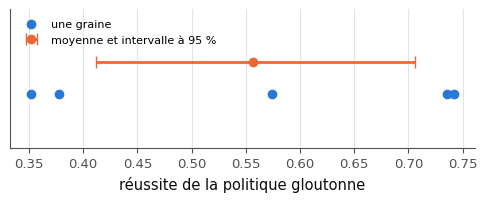

le fichier du rapport : /tmp/wb_ch26_1agb8kv7/report_34.json


In [76]:
with checked("26.34"):
    SEEDS_34 = tuple(range(5)) if FAST_MODE else tuple(range(10))
    start_34 = time.perf_counter()
    rep_34 = report_34(CONFIG_34, SEEDS_34, WORK_DIR / "report_34.json")
    results_34 = np.array(rep_34["results"])
    print(f"{len(SEEDS_34)} graines en {time.perf_counter() - start_34:.0f} s : "
          + " ; ".join(pct(r) for r in results_34))
    print(f"réussite moyenne {pct(rep_34['mean'])}, intervalle bootstrap à 95 % [{pct(rep_34['ci95'][0])} ; "
          f"{pct(rep_34['ci95'][1])}] · la meilleure graine seule : {pct(results_34.max())}, la pire : "
          f"{pct(results_34.min())}")
    plt.figure(figsize=(6, 1.8))
    plt.scatter(results_34, np.zeros_like(results_34), color=wb.plot.CATEGORICAL[0], zorder=3, label="une graine")
    plt.errorbar(rep_34["mean"], 0.3, xerr=[[rep_34["mean"] - rep_34["ci95"][0]],
                 [rep_34["ci95"][1] - rep_34["mean"]]], fmt="o", color=wb.plot.CATEGORICAL[1], capsize=4,
                 label="moyenne et intervalle à 95 %")
    plt.yticks([])
    plt.ylim(-0.5, 0.8)
    plt.xlabel("réussite de la politique gloutonne")
    plt.legend(fontsize=8, loc="upper left")
    plt.show()
    print("le fichier du rapport :", WORK_DIR / "report_34.json")

## Partie F · Le morpion, CartPole, l'auto-apprentissage et le défi

Tu apprends le morpion contre un adversaire aléatoire, avec un masque d'actions ou une pénalité (26.35), tu découpes l'état continu de CartPole pour une table (26.36), tu fais jouer un agent contre lui-même jusqu'à ne plus perdre contre un joueur parfait (26.37), puis tu relèves le défi CartPole (26.38). Le joueur parfait est `minimax` (`TicTacToe(opponent="minimax")`) : il calcule l'arbre de toutes les parties possibles et joue toujours le coup qui donne le meilleur résultat dans le pire des cas (encadré 🧮 du §26.10 de la fiche).

### Ex 26.35 — Morpion contre un adversaire aléatoire : masque d'actions ou pénalité 📦 ★★★ ⏱️ 45 min
**Objectif :** entraîner un agent de morpion avec ta boucle, et comparer un masque d'actions à une pénalité pour les coups interdits.  
**Prérequis :** Ex 26.21 · 26.Q2 · fiche §26.2.1, §26.3.4, §26.10 (encadré 🧮 minimax) · **Fil rouge :** morpion · **Parcours :** C

Le livre propose deux façons de traiter les coups interdits du morpion : ne donner à l'agent que les coups permis, ou lui laisser proposer les neuf cases et punir les coups interdits (fiche §26.2.1). `TicTacToe` fait les deux : `illegal="mask"` met les coups permis dans `info["action_mask"]` (ta `train_tabular` s'en sert), `illegal="penalty"` n'en donne pas, et un coup interdit finit la partie avec −1. L'agent joue les croix (il commence), l'adversaire joue au hasard ; un état est le code en base 3 du plateau (19 683 codes).

**Contrat** : `play_ttt_35(env, Q, n_games, seed=0)` joue `n_games` parties avec la politique gloutonne de `Q` : la meilleure action **permise** quand `info` contient `"action_mask"` (`masked_greedy`), sinon la meilleure action de `Q[state]` ; chaque partie commence par `env.reset(seed=int(rng.integers(2**31)))`, avec `rng = np.random.default_rng(seed)` ; elle rend `{"win": …, "draw": …, "loss": …, "illegal": …}`, le compte de `info["result"]` à la fin des parties, avec les quatre clés.

La vérification essaie ta fonction avec une table qui joue toujours la case 0. La cellule suivante entraîne les deux agents (20 000 parties chacun, une dizaine de secondes ; $\alpha = 0{,}3$, $\gamma = 0{,}9$, $\varepsilon = 0{,}1$), puis les fait jouer contre l'adversaire aléatoire et contre minimax, un adversaire **parfait** (fiche §26.10, encadré 🧮) : il joue toujours le coup qui donne le meilleur résultat dans le pire des cas ; au morpion, deux joueurs parfaits font match nul.

Dans tes notes : combien de coups interdits l'agent à pénalité joue-t-il encore ? Que lui a coûté d'apprendre les règles en plus du jeu ? Contre minimax, aucun agent ne gagne : lequel s'en sort le mieux, et pourquoi l'autre perd-il autant ? L'agent à masque a-t-il appris à bien jouer, ou à battre un adversaire aléatoire (que valent ses coups dans les positions où un joueur parfait le mène, et que fait 26.37 pour les lui montrer) ?

In [77]:
def play_ttt_35(env, Q, n_games, seed=0):
    """Play n_games games of env with the greedy policy of Q: the best LEGAL action when info has "action_mask"
    (masked_greedy), else the best action of Q[state] (np.argmax); each game starts with
    env.reset(seed=int(rng.integers(2**31))), rng = np.random.default_rng(seed). Returns the dict
    {"win": ..., "draw": ..., "loss": ..., "illegal": ...} of the counts of info["result"] at the end of the games
    (all four keys, even at 0)."""
    rng = np.random.default_rng(seed)
    with_mask = masked_greedy(Q)
    counts = {"win": 0, "draw": 0, "loss": 0, "illegal": 0}
    for _ in range(n_games):
        state, info = env.reset(seed=int(rng.integers(2**31)))
        terminated = truncated = False
        while not (terminated or truncated):
            action = with_mask(state, info) if "action_mask" in info else int(np.argmax(Q[state]))
            state, _, terminated, truncated, info = env.step(action)
        counts[info["result"]] += 1
    return counts


with checked("26.35"):
    first_cell_35 = np.zeros((3**9, 9))
    first_cell_35[:, 0] = 1.0                       # always cell 0: legal once, then illegal
    counts_35 = play_ttt_35(TicTacToe(illegal="penalty"), first_cell_35, 20, seed=1)
    if returned("26.35", "play_ttt_35", counts_35):
        same("26.35", "sans masque, une table qui joue toujours la case 0 : 20 coups interdits sur 20 parties",
             [counts_35.get(k, None) for k in ("win", "draw", "loss", "illegal")], [0, 0, 0, 20])
        masked_35 = play_ttt_35(TicTacToe(opponent="minimax"), first_cell_35, 20, seed=1)
        verdict("26.35", masked_35.get("illegal", 1) == 0 and sum(masked_35.values()) == 20,
                f"avec le masque, aucun coup interdit, et minimax ne perd jamais : {masked_35}.",
                f"avec le masque, attendu 20 parties sans coup interdit, reçu {masked_35}.")

✅ Ex 26.35 : sans masque, une table qui joue toujours la case 0 : 20 coups interdits sur 20 parties : [0.0, 0.0, 0.0, 20.0], comme attendu.
✅ Ex 26.35 : avec le masque, aucun coup interdit, et minimax ne perd jamais : {'win': 0, 'draw': 0, 'loss': 20, 'illegal': 0}.


In [78]:
with checked("26.35"):
    N_35 = 20_000 if FAST_MODE else 100_000
    start_35 = time.perf_counter()
    agents_35 = {}
    for mode_35 in ("mask", "penalty"):
        agents_35[mode_35], history_35 = mylearn.rl.train_tabular(
            TicTacToe(opponent="random", illegal=mode_35), N_35, alpha=0.3, gamma=0.9, epsilon=0.1, max_steps=9,
            rng=np.random.default_rng(2635))
        print(f"{mode_35:8s} : {N_35} parties d'entraînement, {pct(np.mean(history_35['returns'][-1000:] == 1))} de "
              f"victoires sur les 1 000 dernières")
    print(f"({time.perf_counter() - start_35:.0f} s)")
    for mode_35, Q_35 in agents_35.items():
        for opponent_35, n_games_35 in (("random", 1000), ("minimax", 200)):
            counts_35 = play_ttt_35(TicTacToe(opponent=opponent_35, illegal=mode_35), Q_35, n_games_35, seed=35)
            print(f"{mode_35:8s} contre {opponent_35:8s} : " + " · ".join(f"{k} {pct(v / n_games_35)}"
                                                                     for k, v in counts_35.items()))

mask     : 20000 parties d'entraînement, 91,7 % de victoires sur les 1 000 dernières


penalty  : 20000 parties d'entraînement, 83,2 % de victoires sur les 1 000 dernières
(15 s)
mask     contre random   : win 98,2 % · draw 1,8 % · loss 0,0 % · illegal 0,0 %


mask     contre minimax  : win 0,0 % · draw 100,0 % · loss 0,0 % · illegal 0,0 %
penalty  contre random   : win 95,5 % · draw 1,9 % · loss 0,1 % · illegal 2,5 %


penalty  contre minimax  : win 0,0 % · draw 52,5 % · loss 23,5 % · illegal 24,0 %


### Ex 26.36 — CartPole : discrétiser un état continu pour un Q-learning tabulaire 📦 ★★★ ⏱️ 45 min
**Objectif :** découper un état continu en intervalles pour qu'une table puisse l'apprendre.  
**Prérequis :** Ex 26.21 · fiche §26.8 · **Fil rouge :** CartPole · **Parcours :** R, C

CartPole-v1 : un chariot porte un bâton en équilibre ; à chaque pas, on pousse le chariot à gauche (0) ou à droite (1) ; chaque pas tenu rapporte 1 ; l'épisode finit quand le bâton penche de plus de 12° ou que le chariot sort de la piste. L'observation est continue : 4 nombres réels (position et vitesse du chariot, angle et vitesse angulaire du bâton). Une table ne peut pas les lister (26.R1) : on découpe chaque variable en quelques intervalles, et un état devient une case de cette grille. `EDGES_36` ignore la position, découpe la vitesse en 3 intervalles, l'angle en 6 et la vitesse angulaire en 8 : 144 états.

**Contrat** : `Discretize_36(env, edges)`, un `gym.ObservationWrapper` : `edges[i]` liste les bornes intérieures de la variable $i$ ; `np.digitize(valeur, edges[i])` donne son intervalle, de 0 à `len(edges[i])` ; l'état est l'indice de la case, `np.ravel_multi_index(indices, dims)` avec `dims[i] = len(edges[i]) + 1`, en `int` Python ; `observation_space` devient `gym.spaces.Discrete(produit des dims)`.

La vérification essaie ton wrapper sur trois observations. La cellule suivante entraîne 800 épisodes avec ta `train_tabular` (200 pas au plus, $\varepsilon$ de 1 à 0,01 sur la moitié de l'entraînement ; une dizaine de secondes) et évalue la politique gloutonne sur 100 épisodes.

Dans tes notes : quel état terminal partage-t-il sa case avec des états qui ne le sont pas, et lequel des bugs de 26.24 deviendrait alors visible ? Pourquoi découper finement l'angle et sa vitesse, et presque pas la position ? Que se passe-t-il si l'on découpe chaque variable en 20 intervalles ?

In [79]:
EDGES_36 = [[],                                    # the cart's position: ignored (one interval)
            [-0.5, 0.5],                           # its speed: 3 intervals
            list(np.linspace(-0.2, 0.2, 7)[1:-1]), # the pole's angle (radians): 6 intervals
            list(np.linspace(-2.0, 2.0, 9)[1:-1])] # its angular speed: 8 intervals

In [80]:
class Discretize_36(gym.ObservationWrapper):
    """Cut each variable of a continuous observation into intervals: edges[i] lists the inner bounds of variable
    i; np.digitize(value, edges[i]) is its interval index, from 0 to len(edges[i]); the state is the index of the
    cell of this grid, np.ravel_multi_index(indices, dims) with dims[i] = len(edges[i]) + 1, as a Python int.
    observation_space becomes gym.spaces.Discrete(product of the dims)."""

    def __init__(self, env, edges):
        super().__init__(env)
        self.edges = [np.asarray(e, dtype=float) for e in edges]
        self.dims = tuple(len(e) + 1 for e in self.edges)
        self.observation_space = gym.spaces.Discrete(int(np.prod(self.dims)))

    def observation(self, observation):
        indices = [int(np.digitize(value, e)) for value, e in zip(observation, self.edges)]
        return int(np.ravel_multi_index(indices, self.dims))


with checked("26.36"):
    cart_36 = Discretize_36(gym.make("CartPole-v1"), EDGES_36)
    verdict("26.36", getattr(cart_36.observation_space, "n", None) == 144, "144 états (1 × 3 × 6 × 8).",
            f"attendu un espace Discrete(144), reçu {cart_36.observation_space}.")
    obs_36 = np.array([[0.3, -1.0, 0.0, 0.0], [0.0, 0.6, -0.25, 2.5], [-2.0, 0.0, 0.05, -0.3]])
    want_36 = [int(np.ravel_multi_index([0, int(np.digitize(o[1], EDGES_36[1])), int(np.digitize(o[2], EDGES_36[2])),
                                         int(np.digitize(o[3], EDGES_36[3]))], (1, 3, 6, 8))) for o in obs_36]
    same("26.36", "trois observations et leurs états", [cart_36.observation(o) for o in obs_36], want_36)
    state_36, _ = cart_36.reset(seed=0)
    verdict("26.36", isinstance(state_36, int), "reset rend un état entier.",
            f"reset doit rendre un int Python, reçu {type(state_36).__name__}.")

✅ Ex 26.36 : 144 états (1 × 3 × 6 × 8).
✅ Ex 26.36 : trois observations et leurs états : [28.0, 103.0, 75.0], comme attendu.
✅ Ex 26.36 : reset rend un état entier.


800 épisodes en 13 s · la politique gloutonne tient 199,7 pas en moyenne (au plus 200) · 60,1 % de cases non nulles


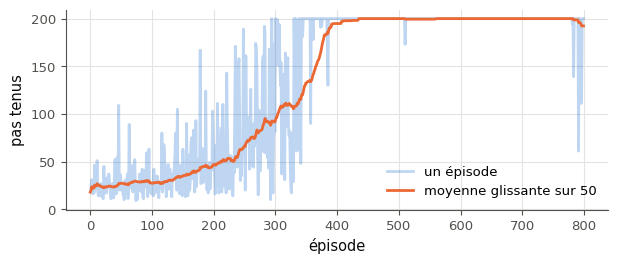

In [81]:
with checked("26.36"):
    N_36 = 800 if FAST_MODE else 2000
    cart_36 = Discretize_36(gym.make("CartPole-v1"), EDGES_36)
    start_36 = time.perf_counter()
    Q_36, history_36 = mylearn.rl.train_tabular(cart_36, N_36, alpha=0.2, gamma=0.99,
                                                epsilon=epsilon_schedule_22(N_36, 1.0, 0.01, 0.5), max_steps=200,
                                                rng=np.random.default_rng(2636))
    score_36 = mylearn.rl.evaluate_policy(cart_36, mylearn.rl.greedy_policy(Q_36), 100, max_steps=200,
                                          rng=np.random.default_rng(36))
    print(f"{N_36} épisodes en {time.perf_counter() - start_36:.0f} s · la politique gloutonne tient "
          f"{fr(score_36['mean_length'], 1)} pas en moyenne (au plus 200) · {pct(np.mean(Q_36 != 0))} de cases non nulles")
    plt.figure(figsize=(7, 2.6))
    plt.plot(history_36["lengths"], alpha=0.3, label="un épisode")
    plt.plot(moving_average(history_36["lengths"], 50), label="moyenne glissante sur 50")
    plt.xlabel("épisode")
    plt.ylabel("pas tenus")
    plt.legend()
    plt.show()

### Ex 26.37 — Auto-apprentissage au morpion : l'agent joue les deux camps 🔬 ★★★★ ⏱️ 90 min
**Objectif :** entraîner un agent qui joue contre lui-même avec une seule table, jusqu'à ne plus perdre contre un joueur parfait.  
**Prérequis :** Ex 26.35 · fiche §26.10 · ∂ 26.8 (Bellman) · **Fil rouge :** morpion · **Parcours :** C

Contre un adversaire aléatoire, l'agent de 26.35 apprend à exploiter ses fautes, pas à bien jouer. AlphaGo Zero apprend en jouant contre lui-même (fiche §26.10). Au morpion, une seule table suffit pour les deux camps, à condition de la lire du point de vue du **joueur au trait** : on échange les croix et les ronds quand c'est aux ronds de jouer (`canonical_37`), si bien que le joueur au trait a toujours les marques 1. Le morpion est un jeu à somme nulle : ce que vaut une position pour l'un, l'autre le perd. La cible d'un coup est donc 1 s'il gagne, 0 s'il remplit le plateau, et sinon **moins** $\gamma$ fois la meilleure valeur de l'adversaire dans la position qui suit.

**Contrat**
- `self_play_37(n_games, alpha=0.5, gamma=0.9, epsilon=0.2, seed=0)` : la docstring donne l'ordre exact des opérations (les tables `TABLES_37`, le tirage d'exploration, la cible, la mise à jour) ; elle rend `Q`, de forme `(19683, 9)` ;
- `vs_minimax_37(Q, n_games, seed=0)` joue `n_games` parties en X et `n_games` en O contre `TicTacToe(opponent="minimax", agent=...)`, avec le meilleur coup permis de `Q[canonical_37(state)]`, et rend `{"X": {"win", "draw", "loss"}, "O": {...}}`.

La vérification contrôle la forme et les valeurs de ta table, puis qu'un agent entraîné 10 000 parties complète une ligne quand il le peut (quelques secondes). La cellule suivante joue 50 000 parties (une dizaine de secondes ; 200 000 en mode complet), puis 100 parties dans chaque camp contre minimax. L'objectif : **aucune défaite**.

Dans tes notes : pourquoi le signe moins dans la cible ? Pourquoi les ronds sont-ils plus difficiles à apprendre que les croix ? Quelle part des cases légales a reçu une valeur, et pourquoi l'agent n'a-t-il pas besoin des autres ? Qu'est-ce qui, au go, empêche de garder cette table, et que fait AlphaGo Zero à la place ?

In [82]:
TABLES_37 = ttt_tables()          # lookup tables over the 19 683 codes: "legal", "winner", "swap", "to_move"


def canonical_37(state):
    """The board seen by the player to move, as if it played X: the code itself when X is to move, else the code
    with X and O exchanged."""
    return int(state) if TABLES_37["to_move"][state] == 1 else int(TABLES_37["swap"][state])

In [83]:
def self_play_37(n_games, alpha=0.5, gamma=0.9, epsilon=0.2, seed=0):
    """Self-play Q-learning with ONE table Q (19683, 9) for both players, read from the point of view of the player
    to move (canonical codes: the mover's marks are 1). rng = np.random.default_rng(seed). Each game starts at
    c = 0; at each move: legal = np.flatnonzero(TABLES_37["legal"][c]); with probability epsilon (rng.random()) a
    legal move drawn by rng.choice(legal), else the best legal move of Q[c] (ties at random with tie_argmax on
    Q[c, legal]); after = c + 3**a. Target: 1 if the mover has just won (TABLES_37["winner"][after] == 1), 0 if
    the board is full, else -gamma * max over the legal moves of Q[c2], with c2 = TABLES_37["swap"][after] (the
    opponent's view: its best value is our loss). Update Q[c, a] += alpha * (target - Q[c, a]), then c = c2
    until the game ends. Returns Q."""
    legal_table, winner, swap = TABLES_37["legal"], TABLES_37["winner"], TABLES_37["swap"]
    rng = np.random.default_rng(seed)
    Q = np.zeros((3**9, 9))
    for _ in range(n_games):
        c = 0
        while True:
            legal = np.flatnonzero(legal_table[c])
            if rng.random() < epsilon:
                a = int(rng.choice(legal))
            else:
                a = int(legal[tie_argmax(Q[c, legal], rng)])
            after = c + 3**a
            c2 = int(swap[after])
            if winner[after] == 1:
                target, done = 1.0, True
            elif not legal_table[after].any():           # no legal move and no winner: the board is full
                target, done = 0.0, True
            else:
                target, done = -gamma * Q[c2, legal_table[c2] == 1].max(), False
            Q[c, a] += alpha * (target - Q[c, a])
            if done:
                break
            c = c2
    return Q


def vs_minimax_37(Q, n_games, seed=0):
    """Play n_games games as X and n_games as O against TicTacToe(opponent="minimax", agent=...), with the best
    legal move of Q[canonical_37(state)]; resets with env.reset(seed=int(rng.integers(2**31))),
    rng = np.random.default_rng(seed). Returns {"X": counts, "O": counts}, counts = {"win", "draw", "loss"}."""
    rng = np.random.default_rng(seed)
    results = {}
    for agent in ("X", "O"):
        env = TicTacToe(opponent="minimax", agent=agent)
        counts = {"win": 0, "draw": 0, "loss": 0}
        for _ in range(n_games):
            state, info = env.reset(seed=int(rng.integers(2**31)))
            terminated = False
            while not terminated:
                legal = np.flatnonzero(info["action_mask"])
                action = int(legal[np.argmax(Q[canonical_37(state), legal])])
                state, _, terminated, _, info = env.step(action)
            counts[info["result"]] += 1
        results[agent] = counts
    return results


with checked("26.37"):
    Q_37 = self_play_37(300, seed=37)
    if returned("26.37", "self_play_37", Q_37):
        Q_37 = np.asarray(Q_37)
        verdict("26.37", Q_37.shape == (3**9, 9), "une table (19683, 9).", f"attendu une table (19683, 9), reçu {Q_37.shape}.")
        illegal_37 = (TABLES_37["legal"] == 0) & (Q_37 != 0)
        verdict("26.37", not illegal_37.any(), "les coups interdits gardent la valeur 0.",
                f"{int(illegal_37.sum())} cases de coups interdits ont changé.")
        verdict("26.37", np.abs(Q_37).max() <= 1 + 1e-12, "toutes les valeurs restent dans [−1, 1].",
                f"une valeur sort de [−1, 1] : {fr(np.abs(Q_37).max(), 3)}.")
        board_37 = np.array([0, 0, 0, 2, 2, 0, 1, 1, 0])           # X to move: cell 8 completes the bottom row
        code_37 = int((board_37 * 3 ** np.arange(9)).sum())
        Q_win_37 = self_play_37(10_000, seed=1)
        legal_37 = np.flatnonzero(TABLES_37["legal"][code_37])
        verdict("26.37", int(legal_37[np.argmax(Q_win_37[code_37, legal_37])]) == 8,
                "après 10 000 parties, l'agent complète sa ligne quand il le peut (_ _ _ / O O _ / X X _).",
                "après 10 000 parties, l'agent ne complète pas la ligne X X _ : relis la cible d'un coup gagnant.")
        counts_37 = vs_minimax_37(np.zeros((3**9, 9)), 5, seed=2)
        verdict("26.37", isinstance(counts_37, dict) and sorted(counts_37) == ["O", "X"]
                and all(sum(c.values()) == 5 for c in counts_37.values()),
                f"vs_minimax_37 rend les résultats des deux camps : {counts_37}.",
                f"vs_minimax_37 doit rendre {{'X': ..., 'O': ...}} avec 5 parties chacun, reçu {counts_37}.")

✅ Ex 26.37 : une table (19683, 9).
✅ Ex 26.37 : les coups interdits gardent la valeur 0.
✅ Ex 26.37 : toutes les valeurs restent dans [−1, 1].


✅ Ex 26.37 : après 10 000 parties, l'agent complète sa ligne quand il le peut (_ _ _ / O O _ / X X _).
✅ Ex 26.37 : vs_minimax_37 rend les résultats des deux camps : {'X': {'win': 0, 'draw': 0, 'loss': 5}, 'O': {'win': 0, 'draw': 0, 'loss': 5}}.


In [84]:
with checked("26.37"):
    N_37 = 50_000 if FAST_MODE else 200_000
    start_37 = time.perf_counter()
    Q_37 = self_play_37(N_37, seed=2637)
    print(f"{N_37} parties contre lui-même en {time.perf_counter() - start_37:.0f} s ; "
          f"{pct(np.mean(Q_37[TABLES_37['legal'] == 1] != 0))} des cases légales ont une valeur")
    results_37 = vs_minimax_37(Q_37, 100, seed=37)
    for side_37, counts_37 in results_37.items():
        print(f"contre minimax, en jouant {side_37} : " + " · ".join(f"{k} {v}" for k, v in counts_37.items()))
    losses_37 = sum(c["loss"] for c in results_37.values())
    verdict("26.37", losses_37 == 0, "aucune défaite contre un joueur parfait, dans les deux camps.",
            f"{losses_37} défaites contre minimax : plus de parties, ou un ε plus grand ?")

50000 parties contre lui-même en 13 s ; 24,8 % des cases légales ont une valeur
contre minimax, en jouant X : win 0 · draw 100 · loss 0
contre minimax, en jouant O : win 0 · draw 100 · loss 0
✅ Ex 26.37 : aucune défaite contre un joueur parfait, dans les deux camps.


### Ex 26.38 — Défi CartPole tabulaire : tenir 475 pas en moyenne sur 500 🏆 ★★★★ ⏱️ 120 min
**Objectif :** régler un découpage de l'état et un entraînement tabulaire pour tenir CartPole-v1 475 pas en moyenne.  
**Prérequis :** Ex 26.36 · Ex 26.22 · Ex 26.34 · **Fil rouge :** CartPole · **Parcours :** C

Le défi : une politique gloutonne tabulaire qui tient le bâton **au moins 475 pas en moyenne sur 100 épisodes** de CartPole-v1, chaque épisode étant coupé à 500 pas (le seuil officiel de CartPole-v1 ; CartPole-v0 coupait à 200 pas et demandait 195, ce que ta politique de 26.36 fait déjà). L'entraînement doit tenir en **3 minutes** de CPU ; il peut couper ses propres épisodes plus tôt. Tu choisis tout : le découpage de l'état (`make_cartpole_38`), l'algorithme, $\alpha$, $\gamma$, le calendrier de $\varepsilon$, le nombre d'épisodes (`train_38`).

La vérification mesure la durée de ton entraînement, évalue ta politique sur 100 épisodes de graines publiques, puis, si tu atteins 475, sur 100 épisodes de graines **cachées**, révélés une fois par session : un nouvel essai affiche la même valeur, pour qu'on ne règle pas le modèle sur le test.

Dans tes notes : quels réglages ont compté le plus ? Ta politique de 26.36 tient-elle 500 pas, et pourquoi une table plus fine n'est-elle pas forcément meilleure ? Sur combien de graines d'entraînement ta recette réussit-elle (26.34) ?

In [85]:
# The challenge: the mean of 100 evaluation episodes of CartPole-v1 (500 steps at most) must reach 475, on public
# seeds, then on hidden ones; the training must stay within MAX_SECONDS_38 seconds on a CPU
GOAL_38 = 475
EPISODE_STEPS_38 = 500
MAX_SECONDS_38 = 180
PUBLIC_SEED_38, HIDDEN_SEED_38 = 38, 3838
print(f"objectif : au moins {GOAL_38} pas en moyenne sur 100 épisodes de {EPISODE_STEPS_38} pas au plus · au plus "
      f"{MAX_SECONDS_38} s d'entraînement")

objectif : au moins 475 pas en moyenne sur 100 épisodes de 500 pas au plus · au plus 180 s d'entraînement


In [86]:
def make_cartpole_38():
    """Your CartPole-v1 with DISCRETE states (gym.make("CartPole-v1") wrapped, for example, by your Discretize_36,
    with the intervals of your choice)."""
    edges = [[], [], [-0.05, 0.0, 0.05], [-0.5, 0.5]]   # the angle (4 intervals) and its speed (3) only: 12 states
    return Discretize_36(gym.make("CartPole-v1"), edges)


def train_38(env):
    """Train a table on env (any tabular method: mylearn.rl.train_tabular, your own loop...) within MAX_SECONDS_38
    seconds, and return it: an array (n_states, n_actions) whose greedy policy will be evaluated."""
    n = 800
    Q, _ = mylearn.rl.train_tabular(env, n, alpha=0.2, gamma=0.99, epsilon=epsilon_schedule_22(n, 1.0, 0.01, 0.5),
                                    max_steps=200, rng=np.random.default_rng(2638))
    return Q


with checked("26.38"):
    env_38 = make_cartpole_38()
    if returned("26.38", "make_cartpole_38", env_38):
        start_38 = time.perf_counter()
        Q_38 = train_38(env_38)
        seconds_38 = time.perf_counter() - start_38
        if returned("26.38", "train_38", Q_38):
            policy_38 = mylearn.rl.greedy_policy(Q_38)
            public_38 = mylearn.rl.evaluate_policy(make_cartpole_38(), policy_38, 100, max_steps=EPISODE_STEPS_38,
                                                   rng=np.random.default_rng(PUBLIC_SEED_38))["mean_length"]
            print(f"entraînement {seconds_38:.0f} s · {Q_38.shape[0]} états · moyenne sur les graines publiques "
                  f"{fr(public_38, 1)} pas")
            if seconds_38 > MAX_SECONDS_38:
                print(f"❌ Ex 26.38 : l'entraînement a duré plus de {MAX_SECONDS_38} s.")
            elif public_38 < GOAL_38:
                print(f"❌ Ex 26.38 : il faut au moins {GOAL_38} pas sur les graines publiques avant de révéler le test.")
            else:
                REVEALED_38 = globals().setdefault("REVEALED_38", mylearn.rl.evaluate_policy(
                    make_cartpole_38(), policy_38, 100, max_steps=EPISODE_STEPS_38,
                    rng=np.random.default_rng(HIDDEN_SEED_38))["mean_length"])
                print(f"test (révélé une fois par session ; un nouvel essai affiche la même valeur) : "
                      f"{fr(REVEALED_38, 1)} pas")
                verdict("26.38", REVEALED_38 >= GOAL_38, f"défi réussi : {fr(REVEALED_38, 1)} pas sur les graines cachées.",
                        f"sur les graines cachées, {fr(REVEALED_38, 1)} pas : moins que les {GOAL_38} visés.")

entraînement 12 s · 12 états · moyenne sur les graines publiques 500,0 pas


test (révélé une fois par session ; un nouvel essai affiche la même valeur) : 500,0 pas
✅ Ex 26.38 : défi réussi : 500,0 pas sur les graines cachées.


## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu écrire et appliquer à la main les mises à jour du Q-learning et de SARSA, état terminal compris ?
2. Sais-tu expliquer ce que règlent $\alpha$, $\gamma$ et $\varepsilon$, et ce qui se passe quand on les choisit mal ?
3. Sais-tu dire pourquoi une table ne passe pas à l'échelle, et ce que DQN y ajoute ?

**Pour aller plus loin** : les chapitres 2, 3 et 6 de Sutton et Barto (2018), cités dans la fiche. La suite : le ch. 27, les GAN.